## Setup

**The code.** Shirol's odd kitten code: $|0_L\rangle = (|1\rangle + |5\rangle)/\sqrt2$, $|1_L\rangle = |3\rangle$, 3
photons on average. One photon loss turns them into the *error words* $(|0\rangle + \sqrt5|4\rangle)/\sqrt6$ and
$|2\rangle$, which have an even photon number.

**The chip and the model.** Shirol's Table I (`AQEC/device.py`). States $|n, j, m\rangle$ = storage photons ×
transmon (g, e, f) × readout photons. The higher-order terms (storage Kerr, $\chi'$) are on. Unless stated otherwise
the losses are the **decay set**: storage photon loss ($\kappa_a$), readout decay ($\kappa_r$) and transmon decay
($T_1$). **All channels** adds dephasing and heating. As in Shirol, $\alpha$ and every $\chi$ are stored positive.

**The gates.** Three X gates, each 1.1 μs on a 2 ns grid, and in §7 one H gate.

- **d2:** open-system GRAPE with photon loss and transmon decay in the cost (`dissipation_grape.ipynb` §11), trained
  on the code words only.
- **EsT:** closed-system GRAPE on this chip that also keeps losses repairable (§3). It is seed 24 of the $C_{\rm err}$
  cost, picked from 50 seeds in `est_gate_selection.ipynb` (`pulses/dgrape/u_X_est_err_closed_s24.npy`). An earlier,
  less transparent EsT gate ("mid", seed 42) was used until 2026-11-01; its runs stay on disk (`*_est_*`).
- **Ord:** the same closed training as EsT without the transparency terms.
- **EsT H (§7 only):** an H gate trained like EsT, 2 μs long, seed 17 of the same cost (`est_gate_selection.ipynb`
  §7, `pulses/dgrape/u_H_est_err_closed_T2_s17.npy`).

**Words and symbols.**

| term | meaning |
|---|---|
| tail | the time after the gate in which only the two FWM combs act |
| comb 1, comb 2 | comb 1 puts a lost photon back and lifts the transmon $g \to f$; comb 2 moves that excitation into the readout, which leaks it away |
| tooth $n$ | one frequency of a comb; it drives the repair $n{-}1 \to n$ photons |
| $\eta_c(t)$ | the control: one complex waveform per comb $c$ (§4.1), capped at $\lvert\eta_c\rvert \le 0.1$ |
| QEC teeth | Shirol's published tooth strengths for PReSPA, their passive correction scheme (their Table II), held constant; a fixed reference tail and one of the two training starts (tag `t2`) |
| $F_{\rm pro}$ | process fidelity on the code against the ideal gate. Gains in % are percentage points of $F_{\rm pro}$ |
| F1 | closed-system fidelity over six logical states (EST's training measure) |
| $T_g$ | the end of the gate, 1.1 μs (2 μs for the H gate of §7) |
| $n_c$ | number of storage photon levels kept in the simulation |
| $\bar n\kappa_a$ | photon-loss rate of the code: 3 photons × $\kappa_a$ ≈ 2.2 % per μs |
| $\chi_{gf}$ | shift of the transmon $g \to f$ line per storage photon, $2\pi \times 2.07$ MHz |
| ideal repair | an instant, perfect photon-add on every error state, with one free phase per photon number (§2.1) |
| kitten limit | 0.935: the best an ideal repair can do for a loss right after a perfect gate (§2.2) |
| shot | the single burst, comb 1 then comb 2, that every trained tail ends with (§6.2) |
| better start | of the two training starts for one gate and tail length, the one that ended higher |

**Code.** `DGRAPE/fwm_tail.py` (model, propagator, objective, scoring), `DGRAPE/train_fwm_tail.py` (training),
`DGRAPE/fwm_tail_score.py` (held-out scoring); §3: `DGRAPE/est_gate.py`, `DGRAPE/train_est_gate.py`; §7: `DGRAPE/fwm_tail_hgate.py`; §8:
`DGRAPE/fwm_repeat.py`, `DGRAPE/fwm_repeat_run.py`. Tests: `validation/test_fwm_tail.py`, `test_est_gate.py`,
`test_fwm_repeat.py`. Dated decisions are in Appendix B.

In [1]:
import json
import os
import sys
import time

if os.path.basename(os.path.abspath(".")) == "notebooks":   # the notebook lives in notebooks/; data paths are relative to the repo root
    os.chdir("..")
REPO_ROOT = os.path.abspath(".")
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from AQEC import device as dev
from DGRAPE import fwm
from DGRAPE import fwm_tail as ft
from DGRAPE import est_gate as eg
import DGRAPE.lindblad_np as lnp
from DGRAPE.code import process_targets, embedded_basis
from DGRAPE.model import Model, operators, index
from core.fourier_cutoff import make_band_mask

# Apple's Accelerate BLAS raises spurious divide/overflow warnings on ordinary complex
# matmuls (no actual NaN/Inf; see core/grape_core.py). Harmless elsewhere.
np.seterr(divide="ignore", over="ignore", invalid="ignore")

TWO_PI = 2 * np.pi
G, E, F = 0, 1, 2
DT = ft.DT                             # us, the 2 ns control grid of the gate
N_C = 16                               # truncation of the tails (and of d2 in section 4), as in fwm_grape Stage 2
N_CMP = 24                             # truncation for the closed-trained gates (section 3)
TAIL_LENGTHS = (0.5, 1.0, 2.0, 3.0)    # us; ft.TAIL_US = 1 us is the default tail
TAU_REPAIR = 0.3                       # us, the shortest time a repair can take (section 2.4)
LOSS_RATE = 3 * dev.kappa_a            # photon losses per us at nbar = 3
F_KITTEN = ft.kitten_repair_limit()    # a loss right after a perfect gate, after the best ideal repair
os.makedirs("figures", exist_ok=True)

OKABE = ["#0072B2", "#E69F00", "#009E73", "#CC79A7", "#D55E00", "#56B4E9"]
# The EsT gate of this notebook: seed 24 of the C_err cost, picked in est_gate_selection.ipynb (the "good" gate).
EST_PULSE = "pulses/dgrape/u_X_est_err_closed_s24.npy"


def tidy(ax, grid=True):
    # House style (aqec_experiments.ipynb, fwm_tuning.ipynb): recessive grid, no top/right spines.
    if grid:
        ax.grid(color="0.9", lw=0.6)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)


def mhz(w):
    return w / TWO_PI


def panel(ax, letter):
    # bold panel letter above the top-left corner of the axes
    ax.text(-0.02, 1.03, f"({letter})", transform=ax.transAxes, fontsize=11, fontweight="bold",
            ha="right", va="bottom")


MU = {"tail (us)": "tail (μs)"}                # display name of the tail-length column


def tail_estimate(gain_ideal, T):
    """Section 2.4's rough upper estimate for a tail of T us, against the gate alone. Returns the
    gate's losses repaired, the losses too late to repair, the kitten-limit cost of repaired losses
    (both negative) and their sum."""
    gain = gain_ideal if T >= TAU_REPAIR else 0.0
    late = LOSS_RATE * min(T, TAU_REPAIR)
    rep = LOSS_RATE * max(T - TAU_REPAIR, 0.0) * (1 - F_KITTEN)
    return gain, -late, -rep, gain - late - rep


print(f"d2 gate: {ft.d2_pulse().shape[0]} steps of {DT * 1e3:.0f} ns; default tail {ft.TAIL_US:g} μs = "
      f"{ft.n_steps(ft.TAIL_US)} steps; reference tooth n_ref = {ft.N_REF}")

d2 gate: 550 steps of 2 ns; default tail 1 μs = 500 steps; reference tooth n_ref = 3


# 1. The idea

$$
|\psi_L\rangle \;\xrightarrow{\ \text{X gate, 1.1 μs}\ }\; \hat\rho(T_g)
\;\xrightarrow{\ \text{tail: combs only, } T_{\rm tail}\ }\; \hat\rho(T_g + T_{\rm tail})
\quad\text{scored against}\quad X|\psi_L\rangle .
$$

The gate runs unchanged. Its output is mostly the right logical state, plus branches in which a photon was lost, the
transmon decayed, or the gate made a small coherent error. In the **tail** only the two FWM combs act; they must fix
the bad branches without spoiling the good one. Every tail is judged against **the same gate alone**.

**Why after the gate.** `fwm_grape.ipynb` §6 found pumps *during* the gate useless: their Stark shift moves the
transmon line the gate's photon-number-selective rotations need, and a loss late in the gate cannot be repaired
before it ends. In the tail neither applies.

**What the combs can do.** Comb 1 puts a lost photon back and lifts the transmon, $|n{-}1,g\rangle \to |n,f\rangle$;
comb 2 hands that excitation to the readout, $|n,f,0\rangle \to |n,g,1\rangle$, which leaks it away. They cannot
return a transmon left in $|e\rangle$, undo most coherent gate errors, or remove the $\sqrt5$ distortion a loss leaves
on this code (§2.2).

**The price.** The tail takes time: photons keep leaking ($\bar n\kappa_a \approx 2.2$ % per μs) and the storage
Kerr effect dephases the photon numbers. A tail must first earn back its own cost.

# 2. Limits after the EsT gate

Computed before any training, for the EsT X gate of this notebook (seed 24; it is introduced in §3, here it is only
the input to the tail). The gate runs at $n_c = 24$, which it needs; tails run at $n_c = 16$ on its output cut to 16
levels, as in training.

## 2.1 Where the infidelity goes, and the best an instant repair can do

**Which errors does the tail face?** We score the gate with **one error channel at a time** on top of the closed
system and call the drop in $F_{\rm pro}$ that channel's share; the closed gate's own error is the *coherent* share.
The channels, at Shirol's rates (`DGRAPE/model.py`, `collapse_ops`): storage photon loss, transmon decay
($f \to e \to g$), storage dephasing, transmon dephasing ($e$ and $f$), heating (storage and transmon) and readout
decay. The readout is cut to one level, exact for this gate.

coherent error           0.13%
photon loss              2.40%
transmon decay (T1)      0.78%
storage dephasing        0.59%
transmon dephasing       0.38%
heating                  0.04%
readout decay            0.00%
sum of the slices        4.33%
all channels together    4.27%  (overlap -0.06%)


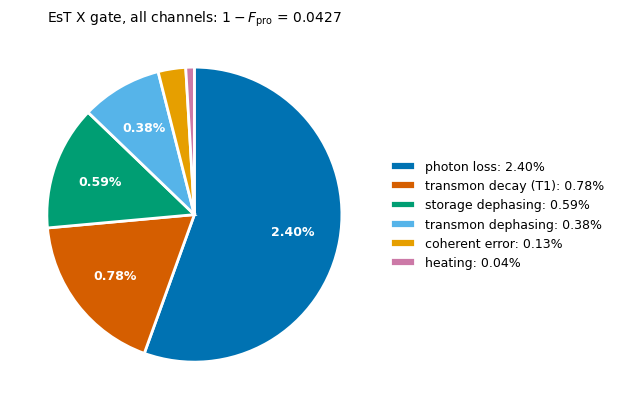

In [2]:
# Section 2.1: the EsT gate's infidelity, one error channel at a time (gate at n_c 24, readout cut to one level)
EST_U = np.load(EST_PULSE)
_, T1, W1 = process_targets("X", N_CMP, 1)
CHANNELS = [  # (slice, jump operators kept, dephasing on, heating on); names from DGRAPE.model.collapse_ops
    ("photon loss", {"a"}, False, False),
    ("transmon decay (T1)", {"s_ge", "s_ef"}, False, False),
    ("storage dephasing", {"phi_a"}, True, False),
    ("transmon dephasing", {"phi_e", "phi_f"}, True, False),
    ("heating", {"up_q", "up_a"}, False, True),
    ("readout decay", {"r"}, False, False),
]


def est_output(keep, dephasing=False, heating=False):
    return ft.gate_output(EST_U, N_CMP, 1, keep, True, dephasing, heating)


F_CLOSED = ft.fidelity_from_outputs(est_output(set()), T1, W1)
F_ALL = ft.fidelity_from_outputs(est_output(None, True, True), T1, W1)
budget = {"coherent error": 1 - F_CLOSED}
for name, keep, deph, heat in CHANNELS:      # what this channel alone adds to the closed gate's error
    budget[name] = F_CLOSED - ft.fidelity_from_outputs(est_output(keep, deph, heat), T1, W1)
BUDGET = pd.Series(budget)
OVERLAP = (1 - F_ALL) - BUDGET.sum()
for name, v in BUDGET.items():
    print(f"{name:22s} {v:7.2%}")
print(f"{'sum of the slices':22s} {BUDGET.sum():7.2%}")
print(f"{'all channels together':22s} {1 - F_ALL:7.2%}  (overlap {OVERLAP:+.2%})")

PIE_COLORS = {"photon loss": OKABE[0], "transmon decay (T1)": OKABE[4], "storage dephasing": OKABE[2],
              "transmon dephasing": OKABE[5], "coherent error": OKABE[1], "heating": OKABE[3]}
shown = BUDGET[list(PIE_COLORS)]                    # readout decay is zero (inert during the gate): not drawn
fig, ax = plt.subplots(figsize=(8.0, 4.2))
wedges, _ = ax.pie(shown.values, colors=list(PIE_COLORS.values()), startangle=90, counterclock=False,
                   wedgeprops=dict(edgecolor="white", linewidth=2))
for w, v in zip(wedges, shown.values):              # numbers on the wedges large enough to hold them
    if v / shown.sum() > 0.08:
        ang = np.deg2rad((w.theta1 + w.theta2) / 2)
        ax.text(0.68 * np.cos(ang), 0.68 * np.sin(ang), f"{v:.2%}", ha="center", va="center",
                fontsize=9, color="white", fontweight="bold")
ax.legend(wedges, [f"{k}: {v:.2%}" for k, v in shown.items()], loc="center left", bbox_to_anchor=(1.0, 0.5),
          frameon=False, fontsize=9)
ax.set_title(f"EsT X gate, all channels: $1 - F_{{\\rm pro}}$ = {1 - F_ALL:.4f}", fontsize=10)
ax.set_aspect("equal")
fig.tight_layout()
fig.savefig("figures/fwm_tails_est_infidelity_pie.png", dpi=150)
plt.show()

**Figure 1. Where the EsT gate's infidelity comes from,** all channels on: $1 - F_{\rm pro} = 0.0427$. Each slice is
the fidelity lost when only that channel is on, on top of the closed gate; *coherent error* is the closed gate's own
$1 - F_{\rm pro}$. Readout decay costs nothing (the readout stays empty during the gate) and is not drawn. The slices
add up to 4.33 %, 0.06 % more than the total, because the channels overlap: a branch hit by two errors is counted
twice.
*Symbols:* % = percentage points of $F_{\rm pro}$; transmon decay = $|f\rangle \to |e\rangle \to |g\rangle$;
dephasing = a random phase on the storage photon number or on the transmon level; heating = a photon or an excitation
added by the warm environment.

**What it shows.** Photon loss is more than half of the error (2.40 of 4.27 %), and it is the only part the combs can
act on.

- The rest is out of a tail's reach: transmon decay 0.78 %, dephasing 0.97 % (storage 0.59 %, transmon 0.38 %),
  the coherent error of the closed gate 0.13 %, heating 0.04 %.
- The decay set used in training (photon loss, readout and transmon decay) gives 3.29 % of the 4.27 %; dephasing and
  heating, the other 1 %, appear only in held-out scoring (§6.5).

**The best an instant repair can do.** The upper limit is the **ideal repair** (`ft.ideal_repair_kraus`), applied
*instantly* at $T_g$, so it ignores the cost of the tail's own time: every error state $|n,g\rangle$ ($n$ even)
becomes $e^{i\phi_n}|n{+}1,g\rangle$, with the phases $\phi_n$ optimized. It is a perfect parity correction for one
photon loss: what perfect, instant combs could do. Each row keeps one set of channels.

In [3]:
EVEN_G = [index(n, G, 0, N_CMP, 1) for n in range(0, N_CMP, 2)]   # even n, transmon in g: what the repair acts on
TABLE1_ROWS = [("closed (no dissipation)", set(), False, False),
               ("storage photon loss only", {"a"}, False, False),
               ("transmon T1 only", {"s_ge", "s_ef"}, False, False),
               ("storage dephasing only", {"phi_a"}, True, False),
               ("transmon dephasing only", {"phi_e", "phi_f"}, True, False),
               ("heating only", {"up_q", "up_a"}, False, True),
               ("all decay (training model)", None, False, False),
               ("all channels", None, True, True)]
lim_rows = {}
for label, keep, deph, heat in TABLE1_ROWS:
    R = est_output(keep, deph, heat)
    rep = ft.ideal_repair_fidelity(R, T1, W1, N_CMP, 1)
    p_even = np.mean([np.real(np.diag(R[b]))[EVEN_G].sum() for b in (0, 1)])   # mean over |0_L>, |1_L>
    lim_rows[label] = {"gate alone": ft.fidelity_from_outputs(R, T1, W1), "+ ideal FWM repair": rep["F"],
                       "P(even, g) at T_g": p_even}
    if keep == {"a"}:
        PHASES_LOSS = rep["phases"]
    if keep is None and not deph:
        rep_135 = ft.ideal_repair_fidelity(R, T1, W1, N_CMP, 1, starts=(0, 2, 4))
LIMITS = pd.DataFrame(lim_rows).T
LIMITS.insert(2, "gain of the ideal repair", LIMITS["+ ideal FWM repair"] - LIMITS["gate alone"])
LIMITS["gain per unit P(even, g) at T_g"] = LIMITS["gain of the ideal repair"] / LIMITS["P(even, g) at T_g"]
F_DISS = LIMITS.loc["all decay (training model)", "gate alone"]
GAIN_IDEAL = LIMITS.loc["all decay (training model)", "gain of the ideal repair"]
display(LIMITS.style.format({"gate alone": "{:.5f}", "+ ideal FWM repair": "{:.5f}", "gain of the ideal repair": "{:+.3%}",
                             "P(even, g) at T_g": "{:.5f}", "gain per unit P(even, g) at T_g": "{:.2f}"})
        .set_caption("Table 1. Fidelity limits at the end of the EsT gate"))
print(f"ideal repair with only the teeth n = 1, 3, 5 (all decay): F = {rep_135['F']:.5f}")

,gate alone,+ ideal FWM repair,gain of the ideal repair,"P(even, g) at T_g","gain per unit P(even, g) at T_g"
closed (no dissipation),0.99869,0.99873,+0.004%,0.00030,0.13
storage photon loss only,0.97467,0.99443,+1.976%,0.02168,0.91
transmon T1 only,0.99089,0.99135,+0.046%,0.00268,0.17
storage dephasing only,0.99279,0.99406,+0.126%,0.00332,0.38
transmon dephasing only,0.99486,0.99505,+0.019%,0.00125,0.15
heating only,0.99829,0.99834,+0.005%,0.00050,0.09
all decay (training model),0.96706,0.98699,+1.993%,0.02389,0.83
all channels,0.95733,0.97838,+2.104%,0.02777,0.76


ideal repair with only the teeth n = 1, 3, 5 (all decay): F = 0.98699


**Table 1. Fidelity limits at the end of the EsT gate.** One row per set of error channels (all decay = photon loss,
readout and transmon decay; all channels adds dephasing and heating).
*Symbols:* $F_{\rm pro}$ at $T_g$ alone and after the ideal repair; gain = (+ ideal repair) − (gate alone);
P(even, g) at $T_g$ = population at even photon number with the transmon in $g$, mean over $|0_L\rangle$ and
$|1_L\rangle$: the only states the repair acts on; gain per unit P(even, g) = gain / P(even, g), roughly the
conditional $F_{\rm pro}$ of a repaired branch of that kind.

**What it shows.** A perfect, instant repair is worth +1.99 % after the EsT gate (0.9671 → 0.9870, decay set), almost
all of it on photon loss.

- Photon loss costs the gate 2.40 %; the ideal repair wins back 1.98 % of it, about four fifths. The rest is the
  kitten limit and the part of each loss the gate scrambles (§2.2).
- The other channels gain little: closed 0.004 %, transmon decay 0.05 %, storage dephasing 0.13 %, transmon
  dephasing 0.02 %, heating 0.005 %.
- **Why they gain at all.** The repair acts on the state at $T_g$, not on the error: any population at even $n$ with
  the transmon in $g$ gets a photon added, whatever put it there. A transmon or dephasing jump mid-gate is followed by
  the rest of the gate, which was not designed for it and leaves part of that branch at even $n$ (P(even, g)
  column; even the closed gate leaves 0.03 %). Per unit of that population a photon-loss branch is repaired to about
  0.9, the others only to 0.1–0.4: adding a photon is the right fix only for a loss. Table 1b breaks this down.
- Most of the transmon-decay and dephasing cost is out of reach: it stays at odd $n$ (right parity, wrong state) or
  leaves the transmon in $e$ or $f$, which the repair leaves alone.
- With all channels the repair gains +2.10 % (0.9573 → 0.9784); the extra 0.1 % over the decay set is mostly
  storage dephasing.
- Only the teeth $n = 1, 3, 5$ matter: restricted to them, the repair gives the same 0.98699 (printed).

In [4]:
# Table 1b: where the even population sits at T_g, per row of Table 1 and per logical input
B_CODE = embedded_basis(N_CMP, 1)                          # columns |0_L>, |1_L>, transmon in g
A_OP = operators(N_CMP, 1)["a"]
X_OUT = {0: B_CODE[:, 1], 1: B_CODE[:, 0]}                 # the X gate's target for input |0_L>, |1_L>
ERR_WORD = {b: A_OP @ v / np.linalg.norm(A_OP @ v) for b, v in X_OUT.items()}   # a X|b>, normalized
IN_LABEL = {0: "|0_L> (error word |2>)", 1: "|1_L> (error word (|0>+√5|4>)/√6)"}
N_BINS = [("n = 0", [0]), ("n = 2", [1]), ("n = 4", [2]), ("n = 6", [3]), ("n ≥ 8", list(range(4, len(EVEN_G))))]
even_rows = {}
for label, keep, deph, heat in TABLE1_ROWS:
    R = est_output(keep, deph, heat)
    blocks = {b: R[b][np.ix_(EVEN_G, EVEN_G)] for b in (0, 1)}       # even n, transmon g, per input
    p_b = {b: np.real(np.trace(blocks[b])) for b in (0, 1)}
    rho = {b: blocks[b] / p_b[b] for b in (0, 1)}                    # normalized even states
    overlap = np.real(np.trace(rho[0] @ rho[1])) / np.sqrt(np.real(np.trace(rho[0] @ rho[0]) *
                                                                   np.trace(rho[1] @ rho[1])))
    for b in (0, 1):
        r = R[b]
        on = lambda v: np.real(np.vdot(v, r @ v)) / p_b[b]           # noqa: E731
        occ = np.real(np.diag(rho[b]))
        even_rows[(label, IN_LABEL[b])] = {
            "P(even, g)": p_b[b], **{k: occ[idx].sum() for k, idx in N_BINS},
            "on the right error word": on(ERR_WORD[b]), "on the wrong error word": on(ERR_WORD[1 - b]),
            "overlap of the two inputs": overlap if b == 0 else np.nan,
            "gain per unit (Table 1)": LIMITS.loc[label, "gain per unit P(even, g) at T_g"] if b == 0 else np.nan}
EVEN_TAB = pd.DataFrame(even_rows).T
assert np.allclose(EVEN_TAB[[k for k, _ in N_BINS]].sum(axis=1), 1.0)
assert np.allclose(EVEN_TAB["P(even, g)"].groupby(level=0, sort=False).mean(), LIMITS["P(even, g) at T_g"])
# The numbers are written out as Table 1b in the markdown cell below (in %): update that table if
# this cell's numbers change. Nothing is printed here.

**Table 1b. Where the even population sits at $T_g$,** for each row of Table 1 and each logical input $\lvert b\rangle$
(computed in the cell above, `EVEN_TAB`).

| channel | input $\lvert b\rangle$ | $P_{\rm even}$ (%) | $n = 0$ | $n = 2$ | $n = 4$ | $n = 6$ | $n \ge 8$ | on $\hat a X\lvert b\rangle$ | wrong error word | overlap | gain per unit |
|:---|:---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| *ideal: loss after a perfect gate* | $\lvert 0_L\rangle$ | | 0 | **100** | 0 | 0 | 0 | 100 | 0 | 0 | 0.94 |
| | $\lvert 1_L\rangle$ | | **17** | 0 | **83** | 0 | 0 | 100 | 0 | | |
| closed (no dissipation) | $\lvert 0_L\rangle$ | 0.04 | 71 | **3** | 7 | 9 | 11 | 3 | 6 | 0.25 | 0.13 |
| | $\lvert 1_L\rangle$ | 0.02 | **26** | 31 | **15** | 11 | 17 | 6 | 31 | | |
| storage photon loss only | $\lvert 0_L\rangle$ | 2.26 | 2 | **94** | 1 | 4 | 0 | 94 | 0 | 0.01 | 0.91 |
| | $\lvert 1_L\rangle$ | 2.08 | **22** | 1 | **76** | 1 | 0 | 96 | 1 | | |
| transmon T1 only | $\lvert 0_L\rangle$ | 0.26 | 29 | **25** | 25 | 18 | 3 | 25 | 25 | 0.70 | 0.17 |
| | $\lvert 1_L\rangle$ | 0.28 | **12** | 34 | **32** | 20 | 2 | 23 | 34 | | |
| storage dephasing only | $\lvert 0_L\rangle$ | 0.32 | 10 | **41** | 43 | 4 | 2 | 41 | 37 | 0.71 | 0.38 |
| | $\lvert 1_L\rangle$ | 0.34 | **11** | 28 | **30** | 29 | 1 | 38 | 28 | | |
| transmon dephasing only | $\lvert 0_L\rangle$ | 0.12 | 33 | **16** | 26 | 18 | 6 | 16 | 23 | 0.72 | 0.15 |
| | $\lvert 1_L\rangle$ | 0.13 | **17** | 32 | **26** | 22 | 3 | 15 | 32 | | |
| heating only | $\lvert 0_L\rangle$ | 0.06 | 49 | **4** | 31 | 8 | 8 | 4 | 27 | 0.31 | 0.09 |
| | $\lvert 1_L\rangle$ | 0.04 | **15** | 38 | **11** | 27 | 8 | 6 | 38 | | |
| all decay (training model) | $\lvert 0_L\rangle$ | 2.46 | 4 | **88** | 3 | 5 | 0 | 88 | 3 | 0.08 | 0.83 |
| | $\lvert 1_L\rangle$ | 2.32 | **21** | 4 | **71** | 3 | 0 | 88 | 4 | | |
| all channels | $\lvert 0_L\rangle$ | 2.81 | 4 | **82** | 9 | 5 | 0 | 82 | 8 | 0.20 | 0.76 |
| | $\lvert 1_L\rangle$ | 2.74 | **20** | 9 | **64** | 7 | 0 | 79 | 9 | | |

*Symbols:* $P_{\rm even}$ = population of input $\lvert b\rangle$ at even $n$ with the transmon in $g$, in % (Table 1's
P(even, g) is the mean of the two inputs). $n = 0$ … $n \ge 8$ = how that population is shared among photon numbers,
in % of $P_{\rm even}$ (each row adds up to 100, up to rounding). 

**Bold** = the photon numbers of the right error word: $\hat a X\lvert 0_L\rangle \propto \lvert 2\rangle$ and $\hat a X\lvert 1_L\rangle \propto (\lvert 0\rangle +\sqrt5\lvert 4\rangle)/\sqrt6$. On $\hat a X\lvert b\rangle$ = share on the right error word, in % of $P_{\rm even}$: the state the repair turns back into the right code word. 

Wrong error word = share on the other input's error word, which the repair turns into the wrong code word. Overlap = ${\rm Tr}(\rho_0\rho_1)/\sqrt{{\rm Tr}\,\rho_0^2\,{\rm Tr}\,\rho_1^2}$ of the two inputs' normalized even states, one per channel (0: they can be told apart; 1:identical). 

Gain per unit = Table 1's last column. The *ideal* rows are a photon lost right after a perfect gate; their gain per unit is the kitten limit, 0.935.

**Why the gain per unit varies.** The repair adds one photon, with one phase per photon number. That restores the
right code word only from the right error word (the *ideal* rows). The gain per unit follows the share on the right
error word, mean of the two inputs: photon loss 95 % → 0.91, storage dephasing 40 % → 0.38, transmon decay 24 % →
0.17, transmon dephasing 16 % → 0.15.

- **Photon loss lands on the error words.** 94 % of the $\lvert 0_L\rangle$ branch sits at $n = 2$; the
  $\lvert 1_L\rangle$ branch splits 22 : 76 over $n = 0$ and 4, close to the ideal 17 : 83, and 96 % of it is on its
  error word. At most 1 % is on the wrong one.
- **The other channels smear it.** After transmon decay or dephasing the even population spreads over $n = 0$ to 6,
  and only 15–41 % is on the right error word.
- **… and forget which input it came from.** For photon loss the two inputs' even states barely overlap (0.01): the
  branch still holds the logical information. For transmon decay and dephasing the overlap is about 0.7, and the
  wrong error word gets as much as the right one, or more (transmon decay: 25 % against 25 % for
  $\lvert 0_L\rangle$, 34 % against 23 % for $\lvert 1_L\rangle$). No recovery of any kind can return information
  the state no longer holds: this is the Knill–Laflamme condition behind $\Delta_{\rm QEC}$ (§3.1).
- **Storage dephasing does best of the rest** (0.38): its even population is the most concentrated on $n = 2$ and 4
  (41 % and 43 % for $\lvert 0_L\rangle$). Its jump operator $\hat n = \hat a^\dagger \hat a$ contains an $\hat a$,
  which may be why (not tested).
- **Caveats.** Photon loss reaches 0.91, not 1, because of the kitten limit (0.935). The overlap shows lost
  information but is not a strict bound. The closed and heating rows hold very little population (at most 0.06 %), so
  their shares are rough guides.

## 2.2 Which losses can be repaired

A photon lost mid-gate is followed by the rest of the gate. `ft.loss_time_profile` follows each single-loss branch,
$\hat K_t = \sqrt{\kappa_a\,dt}\;\hat U(T_g, t)\,\hat a\,\hat U(t, 0)$ (one loss at time $t$; $\hat U$ = evolution with
no jump), and scores it at $T_g$ with and without the ideal repair (the photon-loss phases of Table 1).

In [5]:
loss_prof = ft.loss_time_profile(PHASES_LOSS, N_CMP, pulse=EST_U)
tot = loss_prof["p"].sum()
edges = [0.0, 0.2, 0.4, 0.6, 0.8, 0.9, 1.0, 1.1]
timing_rows = []
for lo, hi in zip(edges[:-1], edges[1:]):
    sel = (loss_prof["t"] >= lo - 1e-9) & (loss_prof["t"] < hi - 1e-9)
    pw = loss_prof["p"][sel]
    timing_rows.append({"loss time (μs)": f"{lo:.1f}-{hi:.1f}", "share of losses": pw.sum() / tot,
                 "F after ideal repair": np.sum(pw * loss_prof["f_repaired"][sel]) / pw.sum(),
                 "F without repair": np.sum(pw * loss_prof["f_unrepaired"][sel]) / pw.sum()})
# binned into time windows for Table C1

expected photon losses per gate (first order): 0.0268
average over all losses: F after ideal repair 0.851, without 0.121
losses in the first 0.4 μs: 0.818 after the ideal repair; in the last 0.1 μs: 0.927
kitten limit (a loss right after a perfect gate, best ideal repair): 0.9353
if every loss repaired to the kitten limit: gain 0.0218 instead of 0.0195


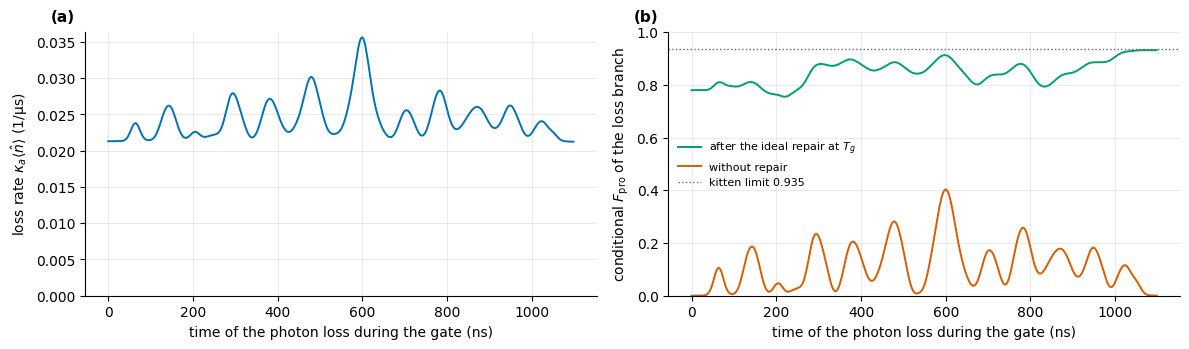

In [6]:
f_rep_mean = np.sum(loss_prof["p"] * loss_prof["f_repaired"]) / tot
f_none_mean = np.sum(loss_prof["p"] * loss_prof["f_unrepaired"]) / tot
late = loss_prof["t"] >= 1.0
f_late = np.sum(loss_prof["p"][late] * loss_prof["f_repaired"][late]) / loss_prof["p"][late].sum()
early = loss_prof["t"] < 0.4
f_early = np.sum(loss_prof["p"][early] * loss_prof["f_repaired"][early]) / loss_prof["p"][early].sum()
print(f"expected photon losses per gate (first order): {tot:.4f}")
print(f"average over all losses: F after ideal repair {f_rep_mean:.3f}, without {f_none_mean:.3f}")
print(f"losses in the first 0.4 μs: {f_early:.3f} after the ideal repair; in the last 0.1 μs: {f_late:.3f}")
print(f"kitten limit (a loss right after a perfect gate, best ideal repair): {F_KITTEN:.4f}")
print(f"if every loss repaired to the kitten limit: gain {tot * (F_KITTEN - f_none_mean):.4f} instead of "
      f"{tot * (f_rep_mean - f_none_mean):.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
t_ns = loss_prof["t"] * 1e3
axes[0].plot(t_ns, loss_prof["p"] / DT, color=OKABE[0], lw=1.4)
axes[0].set_ylabel(r"loss rate $\kappa_a\langle\hat n\rangle$ (1/μs)")
axes[1].plot(t_ns, loss_prof["f_repaired"], color=OKABE[2], lw=1.4, label="after the ideal repair at $T_g$")
axes[1].plot(t_ns, loss_prof["f_unrepaired"], color=OKABE[4], lw=1.4, label="without repair")
axes[1].axhline(F_KITTEN, color="0.4", ls=":", lw=1, label="kitten limit 0.935")
axes[1].set_ylabel("conditional $F_{\\rm pro}$ of the loss branch")
axes[1].set_ylim(0, 1)
axes[1].legend(fontsize=8, frameon=False, loc="center left")
for ax in axes:
    ax.set_xlabel("time of the photon loss during the gate (ns)")
    tidy(ax)
axes[0].set_ylim(bottom=0)
for ax, k in zip(axes, "ab"):
    panel(ax, k)
fig.tight_layout()
fig.savefig("figures/fwm_tails_loss_timing.png", dpi=150)
plt.show()

**Figure 2. When the EsT gate loses photons, and how well each loss can be repaired.** (a) Photon-loss rate during
the gate. (b) Conditional $F_{\rm pro}$ at $T_g$ of a branch with one loss at time $t$, with (green) and without
(vermilion) the ideal repair. Dotted: the kitten limit. Binned values: Table C1.
*Symbols:* $\kappa_a\langle\hat n\rangle$ = losses per μs; conditional $F_{\rm pro}$ = the branch's fidelity.

**What it shows.** A loss at any time during the EsT gate can be repaired well, a late one best.

- On average a repaired loss scores 0.851 (0.121 unrepaired): Table 1's +1.98 %. A loss in the first 0.4 μs still
  repairs to 0.82, one in the last 0.1 μs to 0.93.
- The loss rate follows the photon number the gate passes through: 2.1 to 3.6 % per μs, 0.027 losses per gate.
- Unrepaired, a loss is lost: the branch scores 0 to 0.4, depending on where in its rotation the gate is.
- Even a loss right after a perfect gate repairs only to 0.935, the **kitten limit**: adding the photon back to
  $(|0\rangle + \sqrt5|4\rangle)/\sqrt6$ gives $(|1\rangle + \sqrt5|5\rangle)/\sqrt6$, and no comb can change the
  $1:\sqrt5$ ratio. If every loss were repaired to it, the repair would gain 0.022 instead of 0.020 (printed): the
  gate is already close to that limit.

**Where the population is at $T_g$.** Table 1 counts how much fidelity the repair wins back; this asks where the
whole state sits when the gate ends. For each input $|b\rangle = |0_L\rangle, |1_L\rangle$ the state at $T_g$ is split
into

- transmon in $g$, odd $n$: the **right code word** $X|b\rangle$, the **wrong code word**, and the rest, **outside the
  code** (for example $(|1\rangle - |5\rangle)/\sqrt2$ or $|7\rangle$);
- transmon in $g$, even $n$: the **right error word** $\hat a X|b\rangle$, **correctable**: the repair turns it back
  into the right code word, up to the kitten limit; the **wrong error word**, which the repair turns into the wrong
  code word, a logical error; and the rest, **uncorrectable**: outside the error space, as $L$ in §3.1;
- transmon in $e$ or $f$: the repair does not act on it.

One bar per row of Table 1, so each channel of Figure 1 can be followed to where its population goes.

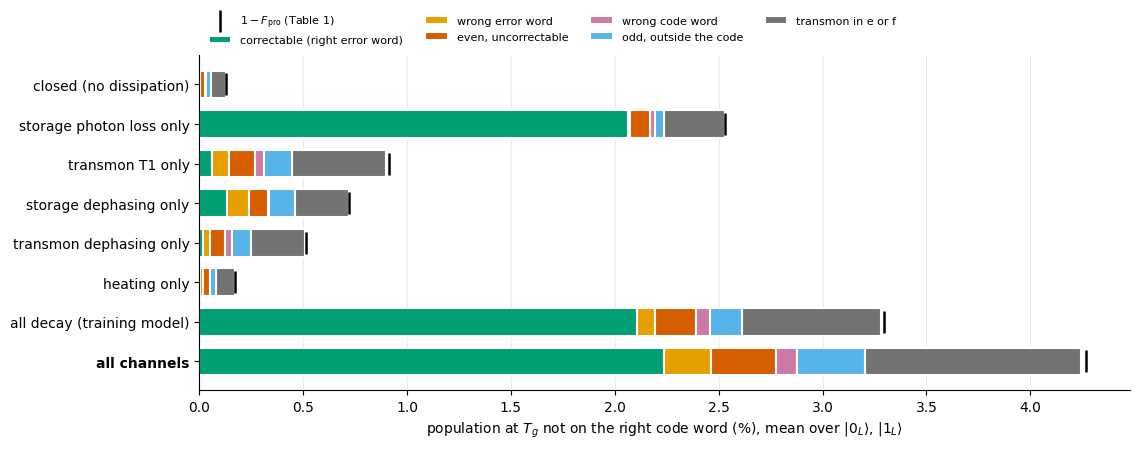

all channels: right code word 0.95755 (F_pro 0.95733); correctable 0.02235, x kitten limit 0.02091 (ideal-repair gain 0.02104)
correctable share of P(even, g): {'closed (no dissipation)': 0.04, 'storage photon loss only': 0.95, 'transmon T1 only': 0.24, 'storage dephasing only': 0.4, 'transmon dephasing only': 0.16, 'heating only': 0.05, 'all decay (training model)': 0.88, 'all channels': 0.8}


In [7]:
# Section 2.2: where the population is at T_g, for each row of Table 1 (EsT gate, n_c 24, readout cut to one level)
# X_OUT (targets) and ERR_WORD (error words) come from the Table 1b cell
ODD_G = [index(n, G, 0, N_CMP, 1) for n in range(1, N_CMP, 2)]
EXCITED = [index(n, j, 0, N_CMP, 1) for n in range(N_CMP) for j in (E, F)]
POP_COLS = ["right code word", "correctable (right error word)", "wrong error word", "even, uncorrectable",
            "wrong code word", "odd, outside the code", "transmon in e or f"]


def populations(R):
    """Mean over the inputs |0_L>, |1_L> of the population in each POP_COLS category."""
    out = np.zeros(len(POP_COLS))
    for b in (0, 1):
        r = R[b]
        diag = np.real(np.diag(r))
        on = lambda v: np.real(np.vdot(v, r @ v))         # noqa: E731
        right, wrong = on(X_OUT[b]), on(X_OUT[1 - b])
        ew_right, ew_wrong = on(ERR_WORD[b]), on(ERR_WORD[1 - b])
        even = diag[EVEN_G].sum()
        out += np.array([right, ew_right, ew_wrong, even - ew_right - ew_wrong, wrong,
                         diag[ODD_G].sum() - right - wrong, diag[EXCITED].sum()]) / 2
    return out


POP = pd.DataFrame({label: populations(est_output(keep, deph, heat)) for label, keep, deph, heat in TABLE1_ROWS},
                   index=POP_COLS).T
assert np.allclose(POP.sum(axis=1), 1.0, atol=1e-6), POP.sum(axis=1)
even_cols = ["correctable (right error word)", "wrong error word", "even, uncorrectable"]
assert np.allclose(POP[even_cols].sum(axis=1), LIMITS["P(even, g) at T_g"], atol=1e-9)

POP_COLORS = {"correctable (right error word)": OKABE[2], "wrong error word": OKABE[1],
              "even, uncorrectable": OKABE[4], "wrong code word": OKABE[3], "odd, outside the code": OKABE[5],
              "transmon in e or f": "0.45"}
order = list(POP.index)[::-1]                              # Table 1's order, top to bottom
fig, ax = plt.subplots(figsize=(11.5, 4.6))
left = np.zeros(len(order))
for col, colr in POP_COLORS.items():
    vals = POP.loc[order, col].values * 100
    ax.barh(range(len(order)), vals, left=left, color=colr, edgecolor="white", linewidth=1.5, height=0.7, label=col)
    left += vals
ax.scatter((1 - LIMITS.loc[order, "gate alone"].values) * 100, range(len(order)), marker="|", s=260, color="black",
           lw=1.8, zorder=3, label=r"$1 - F_{\rm pro}$ (Table 1)")
ax.set_yticks(range(len(order)))
ax.set_yticklabels(order)
for lab in ax.get_yticklabels():
    if lab.get_text() == "all channels":
        lab.set_fontweight("bold")
ax.set_xlabel("population at $T_g$ not on the right code word (%), mean over $|0_L\\rangle$, $|1_L\\rangle$")
ax.set_xlim(0, None)
ax.legend(fontsize=8, frameon=False, ncol=4, loc="lower left", bbox_to_anchor=(0.0, 1.0))
tidy(ax)
ax.grid(axis="y", visible=False)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig("figures/fwm_tails_est_population_Tg.png", dpi=150)
plt.show()
corr = POP.loc["all channels", "correctable (right error word)"]
print(f"all channels: right code word {POP.loc['all channels', 'right code word']:.5f} (F_pro {F_ALL:.5f}); "
      f"correctable {corr:.5f}, x kitten limit {corr * F_KITTEN:.5f} (ideal-repair gain "
      f"{LIMITS.loc['all channels', 'gain of the ideal repair']:.5f})")
print("correctable share of P(even, g):",
      {k: round(v, 2) for k, v in (POP["correctable (right error word)"] / POP[even_cols].sum(axis=1)).items()})

**Figure 3. Where the population is at $T_g$,** EsT X gate, one bar per row of Table 1. Only the part *not* on the
right code word is drawn; black tick: $1 - F_{\rm pro}$ from Table 1. Numbers: Table C10.
*Symbols:* mean over the inputs $|0_L\rangle$, $|1_L\rangle$; right code word = $X|b\rangle$; error word =
$\hat a X|b\rangle$ normalized, $|2\rangle$ or $(|0\rangle + \sqrt5|4\rangle)/\sqrt6$; correctable = on the right
error word; wrong error word = on the other one; even uncorrectable = the rest of even $n$ with the transmon in $g$;
odd outside the code = the rest of odd $n$ with the transmon in $g$; transmon in e or f = any photon number.

**What it shows.** With all channels, 4.2 % of the population is not on the right code word, and about half of it
(2.24 %) is correctable.

- **The bars match Table 1.** Each bar ends close to its tick, so the populations miss almost nothing: right code
  word 0.9576 against $F_{\rm pro}$ 0.9573. The 0.02 % gap is phase error, which populations cannot see. The green,
  orange and vermilion parts add up to Table 1's P(even, g).
- **The correctable part is the repair's gain.** 2.24 % on the right error word × the kitten limit 0.935 = 2.09 %,
  against Table 1's +2.10 %.
- **Photon loss feeds almost only the correctable part** (2.06 of its 2.53 %; 95 % of its even population).
  Transmon decay and dephasing spread over every category, so only 16–40 % of their even population is correctable
  (heating 5 %): this is Table 1's low gain per unit.
- **The largest uncorrectable part is the transmon left in $e$:** 1.0 % with all channels; 0.29 % with photon loss
  alone (closed: 0.07 %), 0.45 % with transmon decay alone. Combs cannot reach it; a transmon reset could.
- **2.0 % cannot be fixed by a photon-adding repair** (everything except green), and 0.23 % is worse than that: the
  wrong error word, which the repair turns into a logical error.

## 2.3 The cost of the tail's own time

The EsT gate followed by an idle tail (no pumps), and by the QEC teeth held on for the whole tail (PReSPA as
published). The idle rows separate the Kerr phase (closed), photon loss, and the decay set with the Kerr and $\chi'$
terms off in the tail.

In [8]:
T2, W2 = ft.tail_targets(N_C, 2)
idle_rows = {}
for label, keep, hot in [("idle, all decay", None, True), ("idle, closed (Kerr and chi' only)", set(), True),
                         ("idle, photon loss only", {"a"}, True),
                         ("idle, all decay, Kerr and chi' off in the tail", None, False)]:
    tm = ft.tail_model(N_C, 2, include_higher_order=hot, keep=keep)
    R = ft.tail_input(EST_U, N_C, 2, gate_n_c=N_CMP, keep=keep)    # gate at n_c 24, cut to the tail's n_c 16
    row = {"0 (gate alone)": ft.fidelity_from_outputs(R, T2, W2)}
    n_prev = 0
    for T in TAIL_LENGTHS:                      # eta = 0 is time independent: chain the segments
        n = ft.n_steps(T)
        R, _ = ft.propagate(tm, np.zeros((n - n_prev, 2)), R)
        n_prev = n
        row[f"{T:g} μs"] = ft.fidelity_from_outputs(R, T2, W2)
    idle_rows[label] = row
# the QEC teeth held on for the whole tail (no band filter, no ramp), all decay
base = pd.DataFrame(ft.baselines(TAIL_LENGTHS, N_C, pulse=EST_U, gate_n_c=N_CMP, label="gate")
                    ).rename(columns={"change_vs_d2": "change_vs_gate"})
teeth = base[base.case == "gate + Table II teeth"]          # the label ft.baselines writes
idle_rows["QEC teeth, all decay"] = {"0 (gate alone)": idle_rows["idle, all decay"]["0 (gate alone)"],
                                          **{f"{T:g} μs": F for T, F in zip(teeth.tail_us, teeth.F_pro)}}
idle = pd.DataFrame(idle_rows).T
idle = idle.loc[["idle, all decay", "QEC teeth, all decay"] + [k for k in idle.index if k.startswith("idle, ")
                                                                    and k != "idle, all decay"]]
display(idle.style.format("{:.5f}")
        .set_caption("Table 2. The EsT gate followed by a fixed tail"))
KERR_PHASE = {n: -(dev.K_a / 2) * n * (n - 1) for n in (1, 3, 5)}       # rad/us, transmon in g
print("Kerr phase per μs on |1>, |3>, |5> (rad):", {n: round(v, 4) + 0.0 for n, v in KERR_PHASE.items()})
dphi = abs(KERR_PHASE[5] - KERR_PHASE[1])
print(f"relative phase |5> vs |1>: {dphi * ft.TAIL_US:.3f} rad after {ft.TAIL_US:g} μs, "
      f"{dphi * 3:.3f} rad after 3 μs")

,0 (gate alone),0.5 μs,1 μs,2 μs,3 μs
"idle, all decay",0.96706,0.95500,0.94039,0.90402,0.85917
"QEC teeth, all decay",0.96706,0.95334,0.93693,0.90449,0.86565
"idle, closed (Kerr and chi' only)",0.99869,0.99710,0.99262,0.97517,0.94684
"idle, photon loss only",0.97467,0.96245,0.94766,0.91088,0.86554
"idle, all decay, Kerr and chi' off in the tail",0.96706,0.95648,0.94603,0.92551,0.90548


Kerr phase per μs on |1>, |3>, |5> (rad): {1: 0.0, 3: -0.0622, 5: -0.2073}
relative phase |5> vs |1>: 0.207 rad after 1 μs, 0.622 rad after 3 μs


**Table 2. The EsT gate followed by a fixed tail.** Columns: tail length.
*Symbols:* $F_{\rm pro}$ at the end of the tail; $\chi'$ = second-order dispersive shift; the tail at $n_c = 16$ (the
gate at 24, cut), two readout levels, readout traced out.

**What it shows.** Waiting is expensive: an idle 1 μs costs 2.7 % (0.9671 → 0.9404), 3 μs costs 10.8 %.

- The Kerr phase alone (closed) costs 0.6 % at 1 μs and 5.2 % at 3 μs: $|5\rangle$ turns against $|1\rangle$ by
  0.21 rad per μs (printed). There is no free rotation, so the tail must cancel this phase itself.
- Photon loss adds about 2.1 % per μs, close to $\bar n\kappa_a$.
- The QEC teeth do worse than idling up to 1 μs, break even at 2 μs and win only at 3 μs (+0.65 %): held constant,
  they need about 2.8 μs per correction (`fwm_grape.ipynb` Table 2) and do nothing about the Kerr phase.

# 3. A gate that keeps losses repairable

## 3.1 Error-semitransparent gates

A tail repairs a loss by adding the photon back. That works only if, at $T_g$, the loss branch holds the right answer
with one photon missing: an error word. d2 scrambles a mid-gate loss: ideally repaired it scores 0.46 on
average, against 0.85 after the EsT gate (§2.2, Table 3).

An **error-semitransparent (EsT)** gate (Roy, Wetherbee & Fatemi, arXiv:2603.15356; `EST/`) is trained with one more
goal: at every moment, the error words move the way the code words move. A loss at any time then ends as a clean error
word, repairable up to the kitten limit. Only *semi*: the storage Kerr term treats code and error words differently.
The paper's three measures (Eqs. 6–8, `EST/diagnostics.py`), on the lossless trajectories, are 0 for a perfect gate:

| measure | what it asks | range |
|---|---|---|
| $\Delta_{\rm QEC}(t)$ | Could the moving code words still be corrected after one loss? (Knill–Laflamme violation for $\{\hat 1, \hat a\}$.) | 0 = correctable |
| $L(t)$ | How much of the moving error state has left ${\rm span}\{\hat a\lvert 0_L(t)\rangle, \hat a\lvert 1_L(t)\rangle\}$? | 0 to 1 |
| $\eta_{\rm ET}(t)$ | How far has the error state's Bloch vector drifted from the code state's? (mean over six states) | 0 to 2 |

($\eta_{\rm ET}$ is EST's $\eta(t)$, renamed to keep it apart from the comb waveforms. $F_{\rm ET}$, printed below,
is EST's error-transparency fidelity.)

## 3.2 The three gates compared

EsT and Ord share d2's chip, duration, grid, drive limits and smooth start shape. EsT uses EST's two-stage cost plus
$C_{\rm err}$ in stage 1 (seed 24); Ord the same stages with the transparency terms off (seed 42), so it differs in seed
as well as cost (Appendix B.3). The closed-trained gates reach photon number 13 (EsT) and 17 (Ord), so every gate is
scored at $n_c = 24$ (held out: 28) with the decay set. EST's tiers (*closed*, *open*, *parked*) are in Appendix B.3.

X_ord_closed: after stage 1 F1 0.9997, F_ET 0.331; after stage 2 F1 0.99987, F_ET 0.331 (tier: closed); max |eps| 25.0 / 25.0 rad/μs; 2.0% of x at the box; 28 min
   closed F1 by n_c: {'16': 0.98406, '18': 0.99883, '20': 0.99987, '24': 0.99981, '28': 0.99981}
X_est_err_closed_s24: after stage 1 F1 0.5279, F_ET 0.898; after stage 2 F1 0.99871, F_ET 0.800 (tier: open); max |eps| 25.0 / 25.0 rad/μs; 0.5% of x at the box; 89 min
   closed F1 by n_c: {'16': 0.99839, '18': 0.99869, '20': 0.99871, '24': 0.99871, '28': 0.99871}


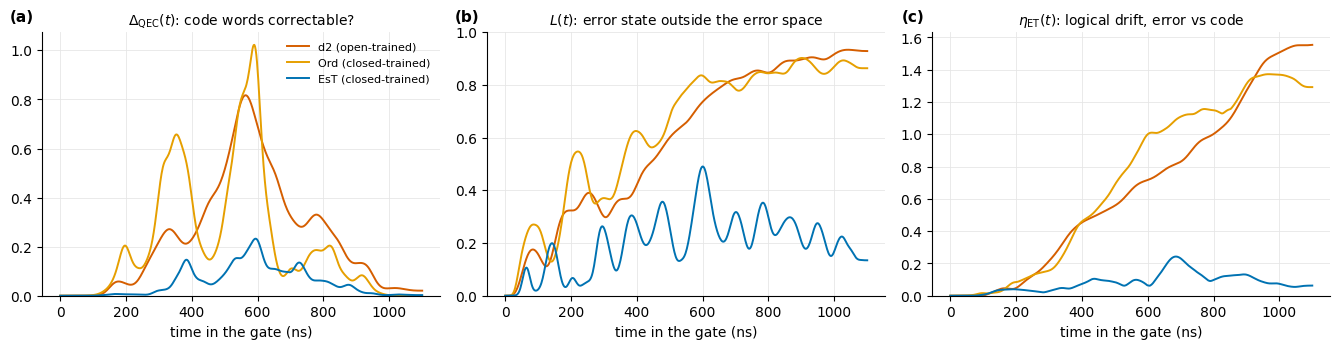

In [9]:
GATES = {"d2 (open-trained)": ft.d2_pulse(),
         "Ord (closed-trained)": np.load("pulses/dgrape/u_X_ord_closed.npy"),
         "EsT (closed-trained)": np.load(EST_PULSE)}
COLORS = {"d2 (open-trained)": OKABE[4], "Ord (closed-trained)": OKABE[1], "EsT (closed-trained)": OKABE[0]}
for tag in ("X_ord_closed", "X_est_err_closed_s24"):
    info = json.load(open(f"pulses/dgrape/{tag}.json"))
    s1, s2 = (st["end"] for st in info["stages"])
    print(f"{tag}: after stage 1 F1 {s1['F1']:.4f}, F_ET {s1['F_ET']:.3f}; after stage 2 F1 {s2['F1']:.5f}, "
          f"F_ET {s2['F_ET']:.3f} (tier: {info['tier']}); max |eps| {info['max_drive_modulus']['cav']:.1f} / "
          f"{info['max_drive_modulus']['tra']:.1f} rad/μs; {info['frac_preimage_pinned']:.1%} of x at the box; "
          f"{info['wall_s'] / 60:.0f} min")
    print("   closed F1 by n_c:", {k: round(v, 5) for k, v in info["trunc_scan"].items()})

et = {name: eg.metrics(u, N_CMP) for name, u in GATES.items()}   # closed trajectories
fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.6))
for name, m in et.items():
    for ax, key in zip(axes, ("delta_qec", "leakage", "eta_avg")):
        ax.plot(m["t"] * 1e3, m[key], color=COLORS[name], lw=1.4, label=name)
for ax, lab in zip(axes, (r"$\Delta_{\rm QEC}(t)$: code words correctable?",
                          r"$L(t)$: error state outside the error space",
                          r"$\eta_{\rm ET}(t)$: logical drift, error vs code")):
    ax.set_xlabel("time in the gate (ns)")
    ax.set_title(lab, fontsize=10)
    ax.set_ylim(bottom=0)
    tidy(ax)
axes[1].set_ylim(0, 1)
for ax, k in zip(axes, "abc"):
    panel(ax, k)
axes[0].legend(fontsize=8, frameon=False)
fig.tight_layout()
fig.savefig("figures/fwm_tails_et_metrics.png", dpi=150)
plt.show()

**Figure 4. How transparent each gate is over time.** (a) $\Delta_{\rm QEC}$, (b) $L$, (c) $\eta_{\rm ET}$, on the
lossless trajectories at $n_c = 24$. Lower is more transparent.
*Symbols:* the measures of §3.1.

In [10]:
_, T24, W24 = process_targets("X", N_CMP, 1)
N_T = ft.n_steps(ft.TAIL_US)                               # the default tail
eta_teeth = ft.eta_from_teeth(fwm.beta_table2(ft.REPAIR_PATHS), N_T, DT, N_CMP)
cmp_rows = []
for name, u in GATES.items():
    s = eg.summary(et[name])
    scan = eg.truncation_scan(u)
    R1 = ft.gate_output(u, N_CMP, 1)                       # decay set, readout cut to one level (exact)
    F_alone = ft.fidelity_from_outputs(R1, T24, W24)
    rep = ft.ideal_repair_fidelity(R1, T24, W24, N_CMP, 1)
    ph = ft.ideal_repair_fidelity(ft.gate_output(u, N_CMP, 1, {"a"}), T24, W24, N_CMP, 1)["phases"]
    gate_prof = ft.loss_time_profile(ph, N_CMP, pulse=u)
    p = gate_prof["p"]
    sc = lambda eta, **kw: ft.score(eta, pulse=u, **{"n_c": N_CMP, **kw})["F_pro"]    # noqa: E731
    vals = [
        ("closed (no loss)", "closed fidelity F1, six states", s["F1"], "{:.5f}"),
        ("closed (no loss)", "F1 at n_c 24 minus F1 at n_c 16", scan[24] - scan[16], "{:+.1e}"),
        ("closed (no loss)", "highest photon level used", s["max_active_fock"], "{:.0f}"),
        ("closed (no loss)", "mean Δ_QEC", s["delta_qec_mean"], "{:.3f}"),
        ("closed (no loss)", "mean L", s["leakage_mean"], "{:.3f}"),
        ("closed (no loss)", "L at the end of the gate", s["leakage_T"], "{:.3f}"),
        ("closed (no loss)", "mean η_ET", s["eta_mean"], "{:.3f}"),
        ("open, gate alone", "F_pro, decay set", F_alone, "{:.5f}"),
        ("open, gate alone", "F_pro, n_c 28 (held out)", sc(np.zeros((0, 2)), n_c=28), "{:.5f}"),
        ("open, gate alone", "F_pro, all channels", sc(np.zeros((0, 2)), dephasing=True, heating=True), "{:.5f}"),
        ("open, gate alone", "photon losses per gate", p.sum(), "{:.4f}"),
        ("open, with a tail", "a loss during the gate, after the ideal repair",
         np.sum(p * gate_prof["f_repaired"]) / p.sum(), "{:.3f}"),
        ("open, with a tail", "+ ideal repair at T_g", rep["F"], "{:.5f}"),
        ("open, with a tail", "gain of the ideal repair", rep["F"] - F_alone, "{:+.2%}"),
        ("open, with a tail", f"+ idle tail, {ft.TAIL_US:g} μs", sc(np.zeros((N_T, 2))), "{:.5f}"),
        ("open, with a tail", f"+ QEC teeth, {ft.TAIL_US:g} μs", sc(eta_teeth), "{:.5f}"),
    ]
    cmp_rows.append((name, vals))
idx = pd.MultiIndex.from_tuples([(g, k) for g, k, _, _ in cmp_rows[0][1]])
cmp_txt = pd.DataFrame({name: [f.format(v) for _, _, v, f in vals] for name, vals in cmp_rows}, index=idx)
MAIN_ROWS = {"closed fidelity F1, six states", "highest photon level used", "mean Δ_QEC", "mean L",
             "L at the end of the gate", "mean η_ET", "F_pro, decay set", "F_pro, all channels",
             "a loss during the gate, after the ideal repair", "gain of the ideal repair"}
display(cmp_txt[[k in MAIN_ROWS for _, k in cmp_txt.index]].style
        .set_caption("Table 3. The three gates compared"))

**Table 3. The three gates compared.** Closed: transparency and closed fidelity. Open: the gate alone. With a tail:
what an instant repair could add. Every row: Table C3.
*Symbols:* F1 = closed fidelity over six states; $\Delta_{\rm QEC}$, $L$, $\eta_{\rm ET}$ = §3.1; $F_{\rm pro}$ with
the decay set unless "all channels"; "a loss during the gate, after the ideal repair" = mean conditional $F_{\rm pro}$
of a single-loss branch, as in Figure 2b.

**What it shows.** The EsT gate keeps losses repairable, and it is also the best gate on its own.

- **Transparent on all three measures:** mean $\Delta_{\rm QEC}$ 0.054 (d2 0.235, Ord 0.217); mean $L$ 0.20 (0.59,
  0.63; at $T_g$ 0.13 against 0.93, 0.86); mean $\eta_{\rm ET}$ 0.079 (0.68, 0.72).
- **Repairable.** A loss during the EsT gate, ideally repaired, scores 0.851 on average (d2 0.461, Ord 0.558), close to
  the kitten limit. The ideal repair gains +1.99 % (d2 +0.96 %, Ord +1.07 %).
- **Better alone.** EsT 0.967 > Ord 0.964 > d2 0.956 (all channels: 0.957, 0.949, 0.945). One training run each, so
  read the gaps as indications. d2 has a 0.9 % coherent error (F1 0.991).
- **Caveats.** EsT closes only to F1 0.99871 (EST's tier *open*) and drives at the amplitude cap (0.5 % of its
  pre-image at the box).

## 3.3 What a tail could gain: an estimate

A rough upper estimate for an optimized tail of length $T$, against the gate alone:

$$
\Delta F \lesssim \underbrace{G}_{\text{the gate's losses repaired}}
- \underbrace{\bar n\kappa_a\,\min(T, \tau)}_{\text{losses too late to repair}}
- \underbrace{\bar n\kappa_a\,(T - \tau)_+\,(1 - 0.935)}_{\text{repaired losses, kitten limit}} .
$$

$G$ is the gate's ideal-repair gain (Table 3). A loss in the last $\tau \approx 0.3$ μs comes too late to repair
($\pi/\chi_{gf} = 0.24$ μs to tell even from odd, plus a comb-2 swap); earlier losses are repaired to the kitten limit;
$(x)_+ = \max(x, 0)$. The estimate is **optimistic**: it assumes the Kerr phase is cancelled exactly and every repair is
perfect once started, and ignores transmon decay and dephasing. Terms for EsT: Table C2; §6.4 compares with training.

In [11]:
# Section 3.3's estimate after each gate, with that gate's ideal-repair gain
gate_est = {}
for name, vals in cmp_rows:
    g_rep = {k: v for _, k, v, _ in vals}["gain of the ideal repair"]
    gate_est[name] = {"G (ideal repair)": g_rep, **{f"{T:g} μs": tail_estimate(g_rep, T)[3] for T in TAIL_LENGTHS}}
display(pd.DataFrame(gate_est).T.style.format("{:+.2%}")
        .set_caption("Table 4. Estimated gain of a tail over the gate alone"))

,G (ideal repair),0.5 μs,1 μs,2 μs,3 μs
d2 (open-trained),+0.96%,+0.27%,+0.20%,+0.06%,-0.08%
Ord (closed-trained),+1.07%,+0.38%,+0.31%,+0.16%,+0.02%
EsT (closed-trained),+1.99%,+1.30%,+1.23%,+1.09%,+0.95%


**Table 4. Estimated gain of a tail over the gate alone.**
*Symbols:* $G$ = the ideal-repair gain at $T_g$; the other columns = the estimate $\Delta F$ for that tail length.

**What it shows.** After d2 even a perfect tail gains little; after EsT there is room.

- After d2 the estimate stays small (+0.27 % at 0.5 μs, +0.20 % at 1 μs); after Ord it is a little larger (+0.38 %,
  +0.31 %).
- After EsT it is +1.23 % at 1 μs and above +0.9 % up to 3 μs: the gate to beat.
- It falls with length, as late and kitten-limited losses grow. This set the default tail to 1 μs.

# 4. Method

## 4.1 The controls and an exact rotating frame

The tail's controls are two complex waveforms, $\eta_1(t)$ and $\eta_2(t)$, one per comb. In the frame below, one
matrix exponential per 2 ns step is the **exact** solution: a rotating frame, but **no RWA**.

**The pumps.** Each comb drives one move:

```
 |n−1, g, 0⟩ ──comb 1──▶ |n, f, 0⟩ ──comb 2──▶ |n, g, 1⟩ ──κ_r──▶ |n, g, 0⟩
  photon lost             photon back           transmon reset,      readout photon
  (error state)           transmon in f         error in readout     leaks (0.27 μs)
```

From the fourth-order junction expansion (`fwm_tuning.ipynb` §1), keeping the resonant terms:

$$
\hat H_{\rm pump} = g_1\xi_1\hat A_1 + g_2\xi_2\hat A_2 + {\rm h.c.} - \big(|\xi_1|^2 + |\xi_2|^2\big)\hat S,
\qquad \hat A_1 = \hat a^\dagger\hat q^{\dagger 2},\quad \hat A_2 = \hat q^2\hat r^\dagger ,
$$

with $\xi_c$ the pump displacement of the transmon, $g_1 = \sqrt{\alpha\chi_{ge}}$, $g_2 = \sqrt{\alpha\chi_{qr}}$ (both
≈ 2π · 12.3 MHz; at $|\xi| = 0.1$ comb 1 swaps $|2,g\rangle \leftrightarrow |3,f\rangle$ at 2π · 3.0 MHz, comb 2 at
2π · 1.7 MHz) and $\hat S$ the Stark shift. This expansion is the only approximation; every step below is exact.

**The fast phase.** DGRAPE's frame turns each mode at its linear frequency, which places $|f\rangle$ at $2\omega_q$;
the real $|f\rangle$ sits lower, $E_{n,f} - E_{n-1,g} \approx -(\alpha + n\chi_{gf})$. So the tooth for photon number
$n$ carries $e^{+i\Delta_{1,n}t}$ with $\Delta_{1,n} \approx 2\pi\cdot 140$ MHz, 1.8 rad per step: a control constant
over a step does not give a constant Hamiltonian, and `fwm_grape` needed CF4 (four exponentials per step).

**The frame.** Pull out the carrier of one reference tooth, comb 1's $n = 3$:

$$
\xi_1 = \eta_1 e^{+i\Delta_{\rm ref}t}, \qquad \xi_2 = \eta_2 e^{-i\Delta_{\rm ref}t},
\qquad \Delta_{\rm ref} = \Delta_{1,3} = 2\pi\cdot 140.485\ {\rm MHz},
$$

($t$ from the start of the tail) and rotate the $|f\rangle$ level alone to match, $\hat\rho' = \hat V^\dagger\hat\rho\hat V$
with $\hat V = e^{i\Delta_{\rm ref}t\hat P_f}$. This lifts $|f\rangle$ by $\Delta_{\rm ref}$ and gives $\hat A_1$, $\hat A_2$
phases that cancel the carriers:

$$
\hat H' = \hat H_d + \Delta_{\rm ref}\hat P_f + \big(\eta_1 g_1\hat A_1 + \eta_2 g_2\hat A_2 + {\rm h.c.}\big)
- \big(|\eta_1|^2 + |\eta_2|^2\big)\hat S \;\big[+\,\eta_1\eta_2\hat M + {\rm h.c.}\big],
$$

($\hat M = \hat a^\dagger\hat r^\dagger$, pump mixing, held-out scoring only). With $\eta$ constant over a step,
$\hat H'$ is constant over the step: **one exponential per step is exact.** A constant $\eta_1$ is exactly tooth 3;
tooth $n$ sits at $(n-3)\chi_{gf}$ inside $\eta_1$, comb 2 is the mirror image (Table 5). Odd teeth repair; even teeth
start from a code word and would pump it out, so the waveform must avoid them. $|\eta_c| = |\xi_c|$, so the cap 0.1 is
`fwm_grape`'s comb cap.

**Why nothing is lost.** Rotating one level is exact when every term touching it gets its phase cancelled or touches it
only on the diagonal:

| term | effect of the rotation |
|---|---|
| $\hat H_d$, $\hat S$ (diagonal), $\hat M$ (no transmon) | none |
| $\hat A_1$, $\hat A_2$ | a phase that cancels the pump carrier |
| jumps $\hat a$, $\hat r$, $\lvert g\rangle\langle e\rvert$ | none (they commute with $\hat P_f$) |
| jump $\lvert e\rangle\langle f\rvert$ | an overall phase, which drops out of $\hat L\hat\rho\hat L^\dagger$ |
| start of the tail, and the targets (transmon in $\lvert g\rangle$) | none: $\hat V = 1$ there |
| cavity drive $\hat a^\dagger$ | none; it would keep the frame exact |
| **transmon drive** $\hat q^\dagger$ | its $\lvert f\rangle\langle e\rvert$ part turns at 140 MHz: **breaks the frame** |

So the tail runs with the transmon drive off. Appendix A checks the frame against DGRAPE's idle and against CF4.

## 4.2 Where the teeth sit

In [12]:
off = ft.tooth_offsets(N_C, ft.N_REF, fwm.FULL_PATHS)
band = ft.ETA_BAND
tab = pd.DataFrame({
    "tooth n": off["paths"],
    "repair": [f"{n - 1} -> {n}" for n in off["paths"]],
    "starts from": ["error state (even n-1)" if n % 2 else "code word (odd n-1)" for n in off["paths"]],
    "comb 1 offset (MHz)": mhz(off["comb1"]),
    "comb 2 offset (MHz)": mhz(off["comb2"]),
})
tab["inside the band"] = [(band[0] < a < band[1]) and (band[0] < b < band[1])
                          for a, b in zip(tab["comb 1 offset (MHz)"], tab["comb 2 offset (MHz)"])]
display(tab.style.hide(axis="index").format({"comb 1 offset (MHz)": "{:+.3f}", "comb 2 offset (MHz)": "{:+.3f}"})
        .set_caption("Table 5. Where each tooth sits inside the comb waveforms"))
tm16 = ft.tail_model(N_C)
print(f"Delta_ref / 2pi = {mhz(tm16.delta_ref):.3f} MHz (alpha/2pi = {mhz(dev.alpha_q):.2f}, "
      f"3 chi_gf/2pi = {3 * mhz(dev.chi_gf):.2f})")
print(f"Stark shift of every comb-1 line at |eta_1| = 0.1: {mhz(4 * dev.alpha_q + dev.chi_ge) * 0.01:.2f} MHz; "
      f"comb-2 lines: {mhz(4 * dev.alpha_q - dev.chi_qr) * 0.01:.2f} MHz")
print(f"drift spread (half width) of the tail model: {mhz(tm16.model.half_width_d):.1f} MHz, "
      f"DGRAPE frame: {mhz(Model(N_C, 2, include_higher_order=True).half_width_d):.1f} MHz")

tooth n,repair,starts from,comb 1 offset (MHz),comb 2 offset (MHz),inside the band
1,0 -> 1,error state (even n-1),-4.135,+4.135,True
2,1 -> 2,code word (odd n-1),-2.066,+2.069,True
3,2 -> 3,error state (even n-1),+0.000,+0.007,True
4,3 -> 4,code word (odd n-1),+2.062,-2.052,True
5,4 -> 5,error state (even n-1),+4.120,-4.107,True
6,5 -> 6,code word (odd n-1),+6.174,-6.158,True
7,6 -> 7,error state (even n-1),+8.225,-8.205,True
8,7 -> 8,code word (odd n-1),+10.271,-10.248,True
9,8 -> 9,error state (even n-1),+12.314,-12.288,False


Delta_ref / 2pi = 140.485 MHz (alpha/2pi = 134.28, 3 chi_gf/2pi = 6.21)
Stark shift of every comb-1 line at |eta_1| = 0.1: 5.38 MHz; comb-2 lines: 5.36 MHz
drift spread (half width) of the tail model: 15.5 MHz, DGRAPE frame: 82.6 MHz


**Table 5. Where each tooth sits inside the comb waveforms,** as offsets from the reference tooth $n = 3$.
*Symbols:* tooth $n$ drives $n{-}1 \to n$; "starts from" = whether the photon number before the repair is an error
state (even) or a code word (odd); band = the ±12 MHz filter on $\eta_c$.

**What it shows.** Each comb is a ladder, one rung per photon number, 2.06 MHz apart.

- In comb 1 the repair teeth $n = 1, 3, 5$ sit at −4.1, 0 and +4.1 MHz; comb 2 is almost its mirror. Between them sit
  teeth that would pump code words out; the band cannot exclude them, so the waveform must avoid them.
- The Stark shift moves all teeth of a comb together, by 5.4 MHz at the cap (printed); the ±12 MHz band leaves room.
- The QEC teeth, as one waveform per comb, are a pulse train that beats every 242 ns (Figure C1).

## 4.3 Cost, constraints and baselines

The optimizer changes the pre-image $x$, shape $(N, 4)$; the waveforms are $\eta = {\rm ramp}({\rm band}(x))/250$,
columns $(\eta_1^I, \eta_1^Q, \eta_2^I, \eta_2^Q)$, $\eta_c = \eta_c^I - i\eta_c^Q$.

$$
C(x) = 1 - F_{\rm pro}\big(\text{gate} + \text{tail}(\eta)\big)
+ \lambda_{a}\sum_{t,c}\big(|\eta_c(t)| - 0.1\big)_+^2
+ \lambda_{d}\sum_{t}|\eta(t + dt) - \eta(t)|^2,
$$

$$
F_{\rm pro} = \frac14\sum_b w_b\,{\rm Re}\,{\rm Tr}\Big[\big(\hat T_b \otimes \mathbb 1_r\big)^\dagger\,
\Phi_{\rm tail}\big(\Phi_{\rm gate}(\hat E_b)\big)\Big], \qquad w = (1, 1, 2).
$$

- **Constraints.** Box $|x| \le 25$; cap $|\eta_c| \le 0.1$ per comb (penalty $\lambda_a = 5.0$); band ±12 MHz on each
  comb; 48 ns ramp at both ends; $\lambda_d = 0.625$. Weights are `fwm_grape`'s, not tuned.
- **The cap.** 0.1 is `fwm_grape` §2.5's limit: the fourth-order model still holds there, and the comb-1 Stark shift
  (5.4 MHz) fits inside the band, so the waveform can follow it. It is not `fwm_tuning`'s steady-tone limit
  ($\beta \approx 0.003$–0.014 for one selective tone): a shaped pulse sets its photon-number selectivity by the
  frequencies it contains, and any crosstalk is charged in $F_{\rm pro}$. Every $\beta$ carries Eq. C9's factor-$\sqrt2$
  uncertainty (`fwm_tuning` §1.2); rates in MHz are the safer numbers.
- **Target.** $\hat E_b$ = the process inputs $|0_L\rangle\langle 0_L|$, $|1_L\rangle\langle 1_L|$,
  $|0_L\rangle\langle 1_L|$; $\hat T_b$ = the **ideal X** applied to each, transmon in $|g\rangle$. **No free
  rotation**: the tail must cancel the Kerr phase itself.
- **Readout traced out.** A readout photon at the end is the dumped error. The stricter "readout empty" score is also
  reported.
- **Gate fixed.** $\Phi_{\rm gate}(\hat E_b)$ is computed once (`ft.gate_output`); training propagates only the tail.
- **Baseline.** Always the gate alone; the idle tail and QEC teeth (Table 2) show what a tail must beat to pay for
  its time.

In [13]:
lib = ft.start_library(ft.TAIL_US, n_c=N_C)                # candidate training starts (Table C4)
N_tail = ft.n_steps(ft.TAIL_US)
bins = int(make_band_mask(N_tail, DT, *ft.ETA_BAND).sum())
print(f"{ft.TAIL_US:g} μs tail: N = {N_tail} steps, frequency spacing {1 / ft.TAIL_US:.2f} MHz, the band keeps {bins} bins per comb "
      f"-> {2 * bins * 2} real degrees of freedom")
print("penalty weights:", {k: round(v, 4) for k, v in ft.TAIL_PENALTIES.items()}, f"  scale x = {ft.S_ETA:.0f} eta")

1 μs tail: N = 500 steps, frequency spacing 1.00 MHz, the band keeps 25 bins per comb -> 100 real degrees of freedom
penalty weights: {'amp': 5.0, 'deriv': 0.625, 'forbid': 0.0, 'transmon': 0.0}   scale x = 250 eta


# 5. Training

The protocol was fixed before the runs (2026-10-20, adjusted 2026-10-21 and, for the EsT gate, 2026-10-31). Machine,
timing and commands: Appendix B.2.

1. **Runs.** Two starts: the QEC teeth (tag `t2`) and zero plus a little noise (tag `z`, 5 % of the cap).
   - **d2 and Ord:** tails of 0.5, 1 and 2 μs, 300 L-BFGS-B iterations (d2: QEC-teeth start only). The five still
     climbing ran 300 more from their best point.
   - **EsT:** tails of 0.5, 0.8, 1, 1.4 and 2 μs, both starts, 600 iterations in one leg.
2. **Truncation.** The gate runs at $n_c = 24$; its output is cut to photon numbers 0–15 for a tail at $n_c = 16$
   (at most $2\times10^{-5}$ dropped; cut and uncut start fidelities agree to $3\times10^{-16}$).
3. **Settings.** Two readout levels, decay set, higher-order terms on, readout traced out, `gtol` $10^{-12}$; the best
   point seen is kept if the last one is worse.
4. **Held-out scoring** (`DGRAPE/fwm_tail_score.py`). Gate and tail re-run without the cut at $n_c$ 24 and 28 (d2: 18
   and 20); three readout levels; all channels; couplings $g/\sqrt2$; pump mixing $s$ = 1, 2; Stark shift off;
   $\eta \times 0.9$, $\times 1.1$; readout required empty.

Tags: `X_tail_<gate>_T<05|08|1|14|2>_<t2|z>`, `<gate>` = `d2`, `ord` or `estg` (resumed runs add `_r`), in
`pulses/dgrape/`; logs in `logs/`.

# 6. Results

Numbers come from the run files (`pulses/dgrape/X_tail_*.json`, `eta_X_tail_*.npy`) and the held-out tables
(`tables/fwm_tail_heldout.csv` for d2 and Ord, `tables/fwm_tail_heldout_good.csv` for EsT); Figures 6 and 7 propagate
the trained tails again. Every gain is against **the same gate alone, in the same condition**. Training values use
$n_c = 16$ (gate at 24, cut, §5). For each gate and length the better of the two starts is shown.

In [14]:
TAIL_T = (0.5, 1.0, 2.0)                                  # the lengths trained after every gate
EST_T = (0.5, 0.8, 1.0, 1.4, 2.0)                         # the EsT gate also has 0.8 and 1.4 us
SHOT_T = (0.8, 1.0, 1.4, 2.0)                             # EsT lengths that build a repair shot (0.5 us stays off)
TAIL_GATES = {"d2": None, "Ord": "pulses/dgrape/u_X_ord_closed.npy", "EsT": EST_PULSE}
GATE_T = {"d2": TAIL_T, "Ord": TAIL_T, "EsT": EST_T}
TAIL_GATE_NC = {"d2": None, "Ord": 24, "EsT": 24}
GATE_LONG = {"d2": "d2 (open-trained)", "Ord": "Ord (closed-trained)", "EsT": "EsT (closed-trained)"}
GCOL = {g: COLORS[GATE_LONG[g]] for g in TAIL_GATES}
STARTS = {"t2": "QEC teeth", "z": "zero + noise"}
T_MARK = {0.5: "o", 0.8: "v", 1.0: "s", 1.4: "D", 2.0: "^"}
HELD_NC = {"d2": (18, 20), "Ord": (24, 28), "EsT": (24, 28)}
T_TAG = {0.5: "05", 0.8: "08", 1.0: "1", 1.4: "14", 2.0: "2"}
TAG_GATE = {"d2": "d2", "Ord": "ord", "EsT": "estg"}       # estg = the tails after the (good) EsT gate


def tail_tag(g, T, s):
    return f"X_tail_{TAG_GATE[g]}_T{T_TAG[T]}_{s}"


# one color per tail length, for figures whose panels are already one gate each (Paul Tol's muted teal, sand, wine,
# cyan, indigo: distinct under all three color-vision deficiencies, and none of them a gate color)
T_COL = {0.5: "#44AA99", 0.8: "#DDCC77", 1.0: "#AA3377", 1.4: "#88CCEE", 2.0: "#222255"}


def load_run(tag):
    with open(f"pulses/dgrape/{tag}.json") as f:
        return json.load(f), np.load(f"pulses/dgrape/eta_{tag}.npy")


RUNS = {}                          # a resumed run (<tag>_r, started from <tag>'s best pre-image) replaces its first
for g in TAIL_GATES:               # part; the history is joined so the iterations count on from the first run
    for T in GATE_T[g]:
        for s in (("t2",) if g == "d2" else ("t2", "z")):
            tag = tail_tag(g, T, s)
            info, eta = load_run(tag)
            F300 = next((e["F_pro"] for e in info["history"] if e["it"] >= 300), info["F_pro"])
            r = {"tag": tag, "info": info, "eta": eta, "F_300": F300 if info["nit"] > 300 else info["F_pro"],
                 "resumed": False}
            if os.path.exists(f"pulses/dgrape/{tag}_r.json"):
                ir, eta_r = load_run(f"{tag}_r")
                hist = info["history"] + [{**e, "it": e["it"] + info["nit"]} for e in ir["history"]]
                r.update(tag=f"{tag}_r", eta=eta_r, resumed=True,
                         info={**ir, "history": hist, "F_pro_start": info["F_pro_start"],
                               "nit": info["nit"] + ir["nit"], "wall_s": info["wall_s"] + ir["wall_s"]})
            RUNS[(g, T, s)] = r
# held-out scores: d2 and Ord from the first campaign, the EsT gate from its own table
HELD = pd.concat([pd.read_csv("tables/fwm_tail_heldout.csv").query("gate != 'EsT'"),
                  pd.read_csv("tables/fwm_tail_heldout_good.csv").assign(gate="EsT")], ignore_index=True)


def held(kind, g, cond="train", T=None, tag=None):
    q = (HELD.kind == kind) & (HELD.gate == g) & (HELD.condition == cond)
    if T is not None:
        q &= np.isclose(HELD.tail_us, T)
    if tag is not None:
        q &= HELD.tag == tag
    return HELD[q].iloc[0]


F_ALONE = {g: held("alone", g).F_pro for g in TAIL_GATES}
F_IDLE = {(g, T): held("idle", g, T=T).F_pro for g in TAIL_GATES for T in GATE_T[g]}
F_TEETH = {(g, T): held("teeth", g, T=T).F_pro for g in TAIL_GATES for T in GATE_T[g]}

run_rows = []
for (g, T, s), r in RUNS.items():
    i, h = r["info"], r["info"]["history"]
    Fh = np.array([e["F_pro"] for e in h])
    run_rows.append({"gate": g, "tail (us)": T, "start": STARTS[s], "F at start": i["F_pro_start"],
                     "F at 300 it": r["F_300"], "resumed": r["resumed"],
                     "F trained": i["F_pro"], "vs gate alone": i["F_pro"] - F_ALONE[g],
                     "vs idle tail": i["F_pro"] - F_IDLE[(g, T)],
                     "gain, last 50 it": Fh[-1] - Fh[max(len(Fh) - 51, 0)],
                     "max |eta_1|": i["max_eta_1"], "max |eta_2|": i["max_eta_2"],
                     "x pinned": i["frac_preimage_pinned"], "iterations": i["nit"],
                     "hours": i["wall_s"] / 3600, "returned": i["returned"], "tag": r["tag"]})
RUN_TAB = pd.DataFrame(run_rows)
RUN_TAB.to_csv("tables/fwm_tail_runs.csv", index=False)
BEST = {}                                                  # (gate, T) -> start with the higher trained F
for (g, T), grp in RUN_TAB.groupby(["gate", "tail (us)"]):
    BEST[(g, T)] = {v: k for k, v in STARTS.items()}[grp.loc[grp["F trained"].idxmax(), "start"]]

G_SHOT = "EsT"                                             # the gate whose tails build a shot (sections 6.2-6.4)
U_SHOT = np.load(TAIL_GATES[G_SHOT])


def best_eta(T):
    return RUNS[(G_SHOT, T, BEST[(G_SHOT, T)])]["eta"]


def tail_run(g, T):
    """The run shown for gate g and length T, the better start. Returns the run, its held-out table (indexed by
    condition), the gate-alone held-out table and a label for the start."""
    s = BEST[(g, T)]
    r = RUNS[(g, T, s)]
    alone = HELD[(HELD.kind == "alone") & (HELD.gate == g)]
    return r, HELD[HELD.tag == r["tag"]].set_index("condition"), alone.set_index("condition"), STARTS[s]


GAIN_REPAIR = {g: dict((k, v) for _, k, v, _ in dict(cmp_rows)[GATE_LONG[g]])["gain of the ideal repair"]
               for g in TAIL_GATES}
COND_LABEL = {"train": "training (n_c 16, cut)", "nc_a": "n_c 18 (d2) / 24 (EsT, Ord)", "nc_b": "n_c 20 (d2) / 28 (EsT, Ord)",
              "nr3": "n_r = 3", "all_ch": "+ dephasing and heating", "g/sqrt2": "couplings g/√2",
              "eta_x0.9": "η × 0.9", "eta_x1.1": "η × 1.1", "stark_off": "Stark shift off",
              "mix1": "pump mixing s = 1", "mix2": "pump mixing s = 2", "closed": "closed system",
              "loss_only": "photon loss only", "no_loss": "all but photon loss"}
conds = list(COND_LABEL)
print("gate alone, n_c 16 (cut):", {g: round(float(v), 6) for g, v in F_ALONE.items()})

gate alone, n_c 16 (cut): {'d2': 0.955554, 'Ord': 0.963802, 'EsT': 0.967059}


## 6.1 The trained tails

In [15]:
head_rows = []
for g in TAIL_GATES:
    for T in GATE_T[g]:
        r, tr, _, start = tail_run(g, T)
        gain_ho = tr.loc["nc_b", "gain_vs_alone"]
        cap = max(r["info"]["max_eta_1"], r["info"]["max_eta_2"])
        head_rows.append({"gate": g, "tail (μs)": T, "start": start, "F_pro": r["info"]["F_pro"],
                          "vs gate alone": r["info"]["F_pro"] - F_ALONE[g],
                          "vs gate alone, held-out n_c": gain_ho, "vs idle tail": r["info"]["F_pro"] - F_IDLE[(g, T)],
                          "§3.3 estimate": tail_estimate(GAIN_REPAIR[g], T)[3],
                          "max |η_c|": cap})
HEAD = pd.DataFrame(head_rows)
pct = ["vs gate alone", "vs gate alone, held-out n_c", "vs idle tail", "§3.3 estimate"]
display(HEAD.style.hide(axis="index")
        .format({"tail (μs)": "{:g}", "F_pro": "{:.5f}", "max |η_c|": "{:.3f}", **{c: "{:+.5f}" for c in pct}})
        .set_caption("Table 6. The trained tails: gain over the same gate alone"))

gate,tail (μs),start,F_pro,vs gate alone,"vs gate alone, held-out n_c",vs idle tail,§3.3 estimate,max |η_c|
d2,0.5,QEC teeth,0.94482,-0.01074,-0.01074,+0.00119,+0.00273,0.012
d2,1,QEC teeth,0.94885,-0.00671,-0.00671,+0.01968,+0.00202,0.098
d2,2,QEC teeth,0.94496,-0.01059,-0.01059,+0.05178,+0.00059,0.093
Ord,0.5,QEC teeth,0.95304,-0.01076,-0.01076,+0.00116,+0.00376,0.012
Ord,1,zero + noise,0.95801,-0.00579,-0.00579,+0.02059,+0.00305,0.099
Ord,2,QEC teeth,0.95428,-0.00952,-0.00952,+0.05288,+0.00162,0.094
EsT,0.5,QEC teeth,0.95623,-0.01083,-0.01083,+0.00123,+0.01303,0.013
EsT,0.8,QEC teeth,0.97027,+0.00321,+0.00321,+0.02374,+0.01260,0.101
EsT,1,zero + noise,0.96985,+0.00279,+0.00279,+0.02946,+0.01231,0.100
EsT,1.4,zero + noise,0.96843,+0.00137,+0.00137,+0.04148,+0.01174,0.099


**Table 6. The trained tails.** One row per gate and tail length, better start. Every run, both starts: Tables C5–C7;
training curves: Figure C2.
*Symbols:* $F_{\rm pro}$ = process fidelity of gate + tail compared to the ideal X gate (§4.3) $n_c = 16$, two readout levels. "vs gate alone" = this $F_{\rm pro}$ minus the same gate's $F_{\rm pro}$ alone
(Table 3), a plain difference in $F_{\rm pro}$ (no %); "vs gate alone, held-out $n_c$" = the same gain re-scored at $n_c$ = 20 (d2) or 28
(EsT, Ord) without the cut.

**What it shows.** Only the EsT gate gains, and most with the 0.8 μs tail.

- **EsT + 0.8 μs: +0.00321,** the largest gain. Its two starts end 0.00003 apart (0.97027, 0.97024). Its peak
  $|\eta_2|$ 0.101 sits 1 % above the cap, which a penalty enforces (§4.3).
- **EsT at other lengths:** +0.00279 (1 μs), +0.00137 (1.4 μs), −0.00064 (2 μs). At 0.5 μs the tail stays nearly
  off ($\max|\eta_c|$ 0.013) and only pays for its time (−0.01083).
- **After d2 and Ord every tail loses,** at best −0.00671 and −0.00579 (1 μs), although they beat an idle tail of the
  same length by about 0.020 (1 μs) and 0.052 (2 μs): they repair, but not enough to pay for their time.
- **Held out** without the cut at the higher $n_c$, no gain moves by more than $4\times10^{-6}$ (Table C6).

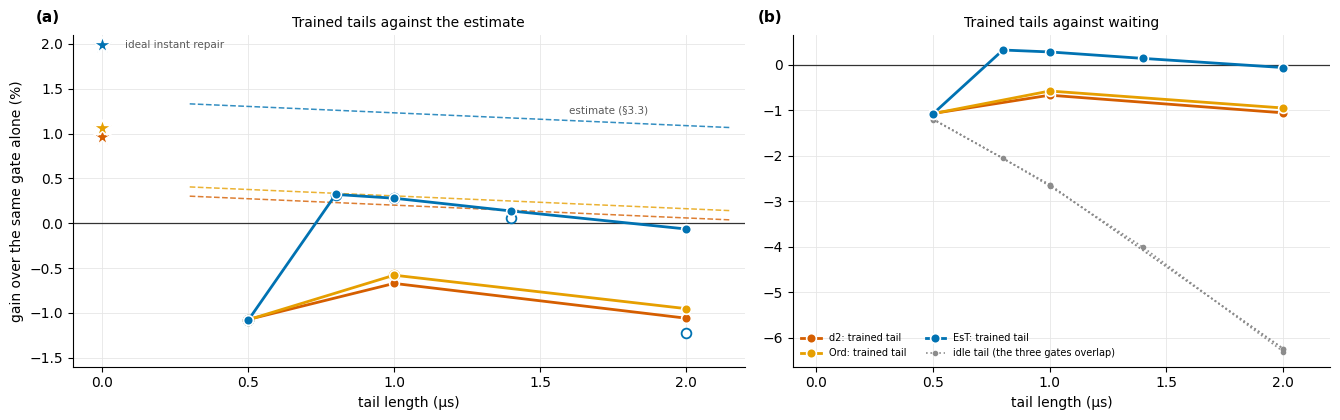

In [16]:
Tgrid = np.linspace(TAU_REPAIR, 2.15, 371)               # the estimate assumes no repair before tau
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.3), gridspec_kw={"width_ratios": [1.25, 1]})
for g in TAIL_GATES:
    c, rows = GCOL[g], HEAD[HEAD.gate == g]
    for ax in axes:
        ax.plot(rows["tail (μs)"], rows["vs gate alone"] * 100, color=c, lw=2.0, marker="o", ms=7, mec="white",
                mew=1.2, zorder=4, label=f"{g}: trained tail")
    ax = axes[0]
    ax.plot(0, GAIN_REPAIR[g] * 100, marker="*", ms=13, color=c, mec="white", mew=1.0, ls="none", zorder=5)
    ax.plot(Tgrid, [tail_estimate(GAIN_REPAIR[g], T)[3] * 100 for T in Tgrid], color=c, ls="--", lw=1.1, alpha=0.8)
    for (gg, T, s), r in RUNS.items():                    # the other start, where it differs
        if gg == g and s != BEST[(g, T)]:
            ax.plot(T, (r["info"]["F_pro"] - F_ALONE[g]) * 100, marker="o", ms=7, mfc="white", mec=c, mew=1.3,
                    ls="none", zorder=3)
    axes[1].plot(GATE_T[g], [(F_IDLE[(g, T)] - F_ALONE[g]) * 100 for T in GATE_T[g]], color="0.55", ls=":", lw=1.2,
                 marker=".", label="idle tail (the three gates overlap)" if g == "EsT" else None)
for ax in axes:
    ax.axhline(0, color="0.2", lw=0.9)
    ax.set_xlabel("tail length (μs)")
    ax.set_xlim(-0.1, 2.2)
    tidy(ax)
axes[0].text(0.08, GAIN_REPAIR["EsT"] * 100, "ideal instant repair", fontsize=7.5, color="0.35", va="center")
axes[0].text(1.6, tail_estimate(GAIN_REPAIR["EsT"], 1.6)[3] * 100 + 0.08, "estimate (§3.3)", fontsize=7.5,
             color="0.35")
axes[0].set_ylim(-1.6, 2.1)
axes[0].set_ylabel("gain over the same gate alone (%)")
axes[0].set_title("Trained tails against the estimate", fontsize=10)
axes[1].set_title("Trained tails against waiting", fontsize=10)
axes[1].legend(fontsize=7, frameon=False, loc="lower left", ncol=2)
for ax, k in zip(axes, "ab"):
    panel(ax, k)
fig.tight_layout()
fig.savefig("figures/fwm_tails_main_comparison.png", dpi=150)
plt.show()

**Figure 5. Gain over the gate alone against tail length.** Colour = gate. (a) Trained tails (filled: better start;
open: the other start, where it differs), the ideal instant repair at $T_g$ (star) and the §3.3 estimate (dashed).
(b) The same on a wider scale, with an idle tail of the same length (dotted).
*Symbols:* gain = $F_{\rm pro}$(gate + tail) − $F_{\rm pro}$(gate alone), $n_c = 16$.

**What it shows.** Every gate's curve has the same shape; the gate sets its height.

- **Shape:** from −1.1 % at 0.5 μs to a best at 0.8–1 μs, then down. A repair shot needs about 600 ns (§6.2); every μs
  beyond costs photon loss.
- **Height:** from 0.8 μs on, EsT sits about 0.9 % above d2 and Ord, close to the gap in ideal-repair gain (+1.99 %
  against +0.96 % and +1.07 %; stars).
- **Far below the estimate** (+0.28 % against +1.23 % at 1 μs; §6.4) and **far above waiting** (an idle tail costs
  2.7 % at 1 μs and 6.3 % at 2 μs).

## 6.2 One repair, at the end of the tail

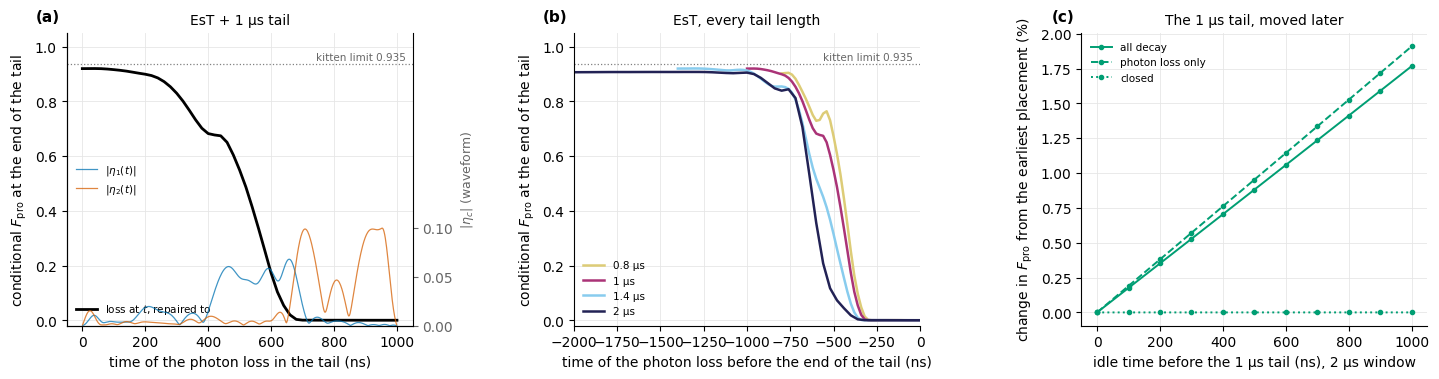

1 μs tail, gain per μs later: all decay +1.77%, photon loss only +1.91%, closed +0.00%
last 1.1 μs of the 2 μs tail, gain per μs later: all decay +1.85%, photon loss only +1.88%, closed +0.00%
expected if every loss before the shot were repaired to the kitten limit: 2.06% per μs
0.5 μs tail: repairs no loss (max branch F 1.7e-04)


In [17]:
# Why the shot sits at the end of the tail (EsT gate). Two tests, cached in tables/fwm_tail_shot_timing_good.csv:
#  loss time: one photon lost at time t in the tail, gate and tail otherwise closed; the conditional F_pro of
#             that branch at the end of the tail says whether the tail repairs a loss at t;
#  slide:     the whole trained 1 us tail (quiet start + shot) placed in a 2 us window, idle before and after, scored with all decay,
#             photon loss only, and closed. Delete the CSV to recompute (several minutes with 8 jobs).
SHOT_CSV = "tables/fwm_tail_shot_timing_good.csv"     # the (good) EsT gate
W_SLIDE = ft.n_steps(2.0)
SLIDE_COND = {"all decay": {}, "photon loss only": {"keep": {"a"}}, "closed": {"keep": set()}}


def loss_branch_profile(eta, stride):
    tm = ft.tail_model(N_C, 2, keep=set())
    Tt, Wt = ft.tail_targets(N_C, 2)
    R = ft.tail_input(U_SHOT, N_C, 2, TAIL_GATE_NC[G_SHOT], keep=set())
    a = operators(N_C, 2)["a"]
    rows = []
    for k in range(0, len(eta) + 1, stride):
        Rb = np.einsum("ij,bjk,lk->bil", a, R, a.conj())                # one photon lost at t_k
        p = np.mean([np.real(np.trace(Rb[b])) for b in (0, 1)])         # branch weight / (kappa_a dt)
        Rend = ft.propagate(tm, eta[k:], Rb)[0] if k < len(eta) else Rb
        rows.append({"t_ns": k * DT * 1e3, "f_branch": ft.fidelity_from_outputs(Rend, Tt, Wt) / p})
        if k < len(eta):
            R = ft.propagate(tm, eta[k:k + stride], R)[0]
    return rows


def slide_score(label, shot, d, cond):
    eta = np.zeros((W_SLIDE, 2), complex)
    eta[d:d + len(shot)] = shot
    F_ = ft.score(eta, n_c=N_C, pulse=U_SHOT, gate_n_c=TAIL_GATE_NC[G_SHOT], **SLIDE_COND[cond])["F_pro"]
    return {"test": "slide", "shot": label, "delay_ns": d * DT * 1e3, "condition": cond, "F_pro": F_}


SHOTS = {"1 μs tail": best_eta(1.0), "last 1.1 μs of the 2 μs tail": best_eta(2.0)[-ft.n_steps(1.1):]}
if not os.path.exists(SHOT_CSV):
    from joblib import Parallel, delayed
    LT = ((0.5, 10), (0.8, 10), (1.0, 10), (1.4, 10), (2.0, 20))     # (tail length, stride in steps)
    prof = Parallel(n_jobs=5)(delayed(loss_branch_profile)(best_eta(T), s) for T, s in LT)
    rows = [{"test": "loss time", "tail_us": T, **r} for (T, _), p in zip(LT, prof) for r in p]
    jobs = [(lab, sh, d, c) for lab, sh in SHOTS.items() for d in range(0, W_SLIDE - len(sh) + 1, 50)
            for c in SLIDE_COND]
    rows += Parallel(n_jobs=8)(delayed(slide_score)(*j) for j in jobs)
    pd.DataFrame(rows).to_csv(SHOT_CSV, index=False)
SHOT = pd.read_csv(SHOT_CSV)
LP, SL = SHOT[SHOT.test == "loss time"], SHOT[SHOT.test == "slide"]


fig, axes = plt.subplots(1, 3, figsize=(14.5, 3.9))
ax = axes[0]                                              # (a) the EsT 1 us tail: waveform and which losses it repairs
g_ = LP[np.isclose(LP.tail_us, 1.0)]
eta = best_eta(1.0)
t_ns = (np.arange(len(eta)) + 0.5) * DT * 1e3
ax2 = ax.twinx()
for c, col in ((0, OKABE[0]), (1, OKABE[4])):
    ax2.plot(t_ns, np.abs(eta[:, c]), color=col, lw=0.9, alpha=0.75, label=fr"$|\eta_{c + 1}(t)|$")
ax2.set_ylim(0, 0.3)
ax2.set_yticks([0, 0.05, 0.1])
ax2.set_ylabel(r"$|\eta_c|$ (waveform)", fontsize=9, color="0.4")
ax2.tick_params(axis="y", colors="0.4")
ax2.spines["top"].set_visible(False)
ax2.legend(fontsize=7.5, frameon=False, loc="center left")
ax.plot(g_.t_ns, g_.f_branch, color="k", lw=2.0, label="loss at $t$, repaired to")
ax.set_xlabel("time of the photon loss in the tail (ns)")
ax.set_ylabel(r"conditional $F_{\rm pro}$ at the end of the tail")
ax.set_title("EsT + 1 μs tail", fontsize=10)
ax.legend(fontsize=7.5, frameon=False, loc="lower left")
ax = axes[1]                                              # (b) every EsT length, aligned at the end
for T in SHOT_T:
    g_ = LP[np.isclose(LP.tail_us, T)]
    ax.plot(g_.t_ns - T * 1e3, g_.f_branch, color=T_COL[T], lw=1.8, label=f"{T:g} μs")
ax.set_xlim(-2000, 0)
ax.set_xlabel("time of the photon loss before the end of the tail (ns)")
ax.set_title("EsT, every tail length", fontsize=10)
ax.set_ylabel(r"conditional $F_{\rm pro}$ at the end of the tail")
ax.legend(fontsize=7.5, frameon=False, loc="lower left")
for ax in axes[:2]:
    ax.axhline(F_KITTEN, color="0.5", ls=":", lw=0.9)
    ax.text(0.98, F_KITTEN + 0.015, f"kitten limit {F_KITTEN:.3f}", fontsize=7.5, color="0.4", ha="right",
            transform=ax.get_yaxis_transform())
    ax.set_ylim(-0.02, 1.05)
ax = axes[2]                                              # (c) the 1 us tail slid through a 2 us window
for cond, ls in zip(SLIDE_COND, ("-", "--", ":")):
    g_ = SL[(SL.shot == "1 μs tail") & (SL.condition == cond)]
    ax.plot(g_.delay_ns, (g_.F_pro - g_.F_pro.iloc[0]) * 100, color=OKABE[2], ls=ls, marker="o", ms=3, lw=1.4,
            label=cond)
ax.set_xlabel("idle time before the 1 μs tail (ns), 2 μs window")
ax.set_ylabel(r"change in $F_{\rm pro}$ from the earliest placement (%)")
ax.set_title("The 1 μs tail, moved later", fontsize=10)
ax.legend(fontsize=7.5, frameon=False, loc="upper left")
for ax, k in zip(axes, "abc"):
    tidy(ax)
    panel(ax, k)
fig.tight_layout(w_pad=3.0)
fig.savefig("figures/fwm_tails_shot_timing.png", dpi=150)
plt.show()

for lab in SHOTS:
    g_ = SL[SL.shot == lab]
    slopes = {c: np.polyfit(gc.delay_ns / 1e3, gc.F_pro, 1)[0] for c, gc in g_.groupby("condition")}
    print(f"{lab}, gain per μs later: " + ", ".join(f"{c} {slopes[c]:+.2%}" for c in SLIDE_COND))
print(f"expected if every loss before the shot were repaired to the kitten limit: {LOSS_RATE * F_KITTEN:.2%} per μs")
print("0.5 μs tail: repairs no loss (max branch F "
      f"{LP[np.isclose(LP.tail_us, 0.5)].f_branch.max():.1e})")

**Figure 6. Every trained tail ends in one repair shot, and repairs only the losses before it.** (a) The EsT 1 μs
tail: $|\eta_1|$ (blue), $|\eta_2|$ (vermilion), right axis; black, the conditional $F_{\rm pro}$ at the end of the
tail of a branch with one photon loss at time $t$. (b) The same for every EsT length that builds a shot, aligned at
the end. (c) The whole 1 μs tail moved later in a 2 μs window, scored with all decay (solid), photon loss only
(dashed) and closed (dotted). In (a, b) the gate output is cut to $n_c = 16$ and the evolution is otherwise closed.
Waveforms of every gate and length: Figures C3–C5. Cached in `tables/fwm_tail_shot_timing_good.csv`.

**What it shows.** Each tail waits, then fires a single shot that repairs every loss before it and none after it.

- **(a)** For about 400 ns the waveforms stay small; comb 1 rises at 400–700 ns, then comb 2 at the cap in two lobes
  (700–1000 ns). A loss before the shot repairs to 0.92, near the kitten limit; one after about 700 ns not at all.
- **(b)** Aligned at the end, the 0.8–2 μs repair curves nearly coincide: a longer tail only waits longer. The 0.5 μs
  tail repairs nothing (printed).
- **(c)** Moving the tail later gains +1.77 % per μs (all decay), +1.91 % (photon loss only), nothing closed, close
  to $\bar n\kappa_a \times 0.935 = 2.06$ % per μs. So the shot belongs at the very end, and what limits the tail is
  the part of the shot during which losses cannot be repaired (Table 7).

In [18]:
UNPROT, win_rows = {}, []                                 # tail length -> weighted unrepaired window (us)
for T in SHOT_T:
    g_ = LP[np.isclose(LP.tail_us, T)]
    f0, f = g_.f_branch.iloc[0], g_.f_branch.values
    step_us = np.diff(g_.t_ns).mean() / 1e3
    UNPROT[T] = np.sum(1 - f[:-1] / f0) * step_us
    win_rows.append({"tail (μs)": T, "a loss before the shot, repaired to": f0,
                     "repair below half from (ns before the end)": T * 1e3 - g_.t_ns.values[np.argmax(f < f0 / 2)],
                     "unrepaired window (ns)": UNPROT[T] * 1e3, "its cost": LOSS_RATE * f0 * UNPROT[T],
                     "F_pro": HEAD[(HEAD.gate == G_SHOT) & np.isclose(HEAD["tail (μs)"], T)].F_pro.item()})
display(pd.DataFrame(win_rows).style.hide(axis="index")
        .format({"tail (μs)": "{:g}", "a loss before the shot, repaired to": "{:.3f}",
                 "repair below half from (ns before the end)": "{:.0f}", "unrepaired window (ns)": "{:.0f}",
                 "its cost": "{:.2%}", "F_pro": "{:.5f}"})
        .set_caption("Table 7. The repair window of each EsT tail"))

tail (μs),"a loss before the shot, repaired to",repair below half from (ns before the end),unrepaired window (ns),its cost,F_pro
0.8,0.902,440,458,0.91%,0.97027
1,0.920,460,498,1.01%,0.96985
1.4,0.920,560,573,1.16%,0.96843
2,0.907,600,604,1.21%,0.96642


**Table 7. The repair window of each EsT tail.**
*Symbols:* "repaired to" = conditional $F_{\rm pro}$ of a loss early in the tail; unrepaired window =
$\int (1 - f(t)/f(0))\,dt$, the time weighted by how badly a loss there is repaired; its cost = window ×
$\bar n\kappa_a$ × $f(0)$; $F_{\rm pro}$ as in Table 6.

**What it shows.** Every tail ends with about half a microsecond in which losses are not repaired, costing about 1 %.

- The window is 458 ns (0.8 μs), 498 ns (1 μs) and 573–604 ns (1.4, 2 μs), longer than the 300 ns the §3.3 estimate
  assumed; longer tails build a slightly slower shot (Figure C5).
- It costs 0.91–1.21 %, three to four times the best net gain: the biggest term in Table 9, and a faster shot the
  biggest lever.

## 6.3 A real repair

In [19]:
mech_rows = []
for (g, T), s in BEST.items():
    tag = RUNS[(g, T, s)]["tag"]
    tr = lambda cond: held("trained", g, cond, tag=tag)                       # noqa: E731
    al = lambda cond: held("alone", g, cond)                                  # noqa: E731
    idl = lambda cond: held("idle", g, cond, T=T)                             # noqa: E731
    mech_rows.append({"gate": g, "tail (us)": T,
                      "gain, all decay": tr("train").gain_vs_alone,
                      "gain, closed": tr("closed").gain_vs_alone,
                      "gain, photon loss only": tr("loss_only").gain_vs_alone,
                      "gain, all but photon loss": tr("no_loss").gain_vs_alone,
                      "gain, Stark off": tr("stark_off").gain_vs_alone,
                      "loss cost: gate alone": al("no_loss").F_pro - al("train").F_pro,
                      "loss cost: + idle": idl("no_loss").F_pro - idl("train").F_pro,
                      "loss cost: + trained": tr("no_loss").F_pro - tr("train").F_pro})
MECH = pd.DataFrame(mech_rows).sort_values(["gate", "tail (us)"])

mech_main = []                                            # the 1 us tails of every gate, and EsT 0.8 and 1.4 us
for g, T in [(g, 1.0) for g in TAIL_GATES] + [(G_SHOT, T) for T in (0.8, 1.4)]:
    r, tr, al, _ = tail_run(g, T)
    idl = HELD[(HELD.kind == "idle") & (HELD.gate == g) & np.isclose(HELD.tail_us, T)].set_index("condition")
    mech_main.append({"gate": g, "tail (μs)": T,
                      "gain, all decay": tr.loc["train", "gain_vs_alone"],
                      "gain, closed": tr.loc["closed", "gain_vs_alone"],
                      "gain, photon loss only": tr.loc["loss_only", "gain_vs_alone"],
                      "gain, all but photon loss": tr.loc["no_loss", "gain_vs_alone"],
                      "loss cost: gate alone": al.loc["no_loss", "F_pro"] - al.loc["train", "F_pro"],
                      "loss cost: + idle": idl.loc["no_loss", "F_pro"] - idl.loc["train", "F_pro"],
                      "loss cost: + trained": tr.loc["no_loss", "F_pro"] - tr.loc["train", "F_pro"]})
MECH_MAIN = pd.DataFrame(mech_main)
display(MECH_MAIN.style.hide(axis="index")
        .format({**{c: "{:+.2%}" for c in MECH_MAIN.columns[2:]}, "tail (μs)": "{:g}"})
        .set_caption("Table 8. Where the gain comes from: the channel split"))

gate,tail (μs),"gain, all decay","gain, closed","gain, photon loss only","gain, all but photon loss",loss cost: gate alone,loss cost: + idle,loss cost: + trained
d2,1,-0.67%,-0.01%,-0.35%,-0.21%,+2.37%,+4.43%,+2.83%
Ord,1,-0.58%,-0.01%,-0.24%,-0.22%,+2.39%,+4.46%,+2.75%
EsT,1,+0.28%,-0.01%,+0.70%,-0.25%,+2.38%,+4.46%,+1.85%
EsT,0.8,+0.32%,-0.01%,+0.77%,-0.27%,+2.38%,+4.05%,+1.80%
EsT,1.4,+0.14%,-0.01%,+0.47%,-0.21%,+2.38%,+5.25%,+2.03%


**Table 8. Where the gain comes from,** for the 1 μs tails of every gate and the EsT 0.8 and 1.4 μs tails (every
length: Table C8). Entries are differences of $F_{\rm pro}$ in percentage points, against the gate alone with the same
channels on.
*Symbols:* closed = no jumps; all but photon loss = the decay set without storage photon loss; loss cost =
$F$(all but photon loss) − $F$(all decay), for the gate alone, gate + idle tail and gate + trained tail.

**What it shows.** The gain is a real repair of photon loss, paid for by transmon decay.

- **Nothing coherent:** closed, every tail is within 0.01 % of its gate alone.
- **Photon loss is repaired:** with photon loss alone the EsT tails gain +0.77 % (0.8 μs), +0.70 % (1 μs), +0.47 %
  (1.4 μs). The EsT loss cost falls from 2.38 % to 1.80–2.03 % (an idle tail would raise it to 4.05–5.25 %). After d2
  and Ord the same shape gains nothing net on photon loss (−0.35 %, −0.24 %).
- **The price is the same for every gate:** the non-loss channels cost 0.21–0.27 %, mostly transmon decay while the
  shot holds population in $|f\rangle$ (Figure 7c).

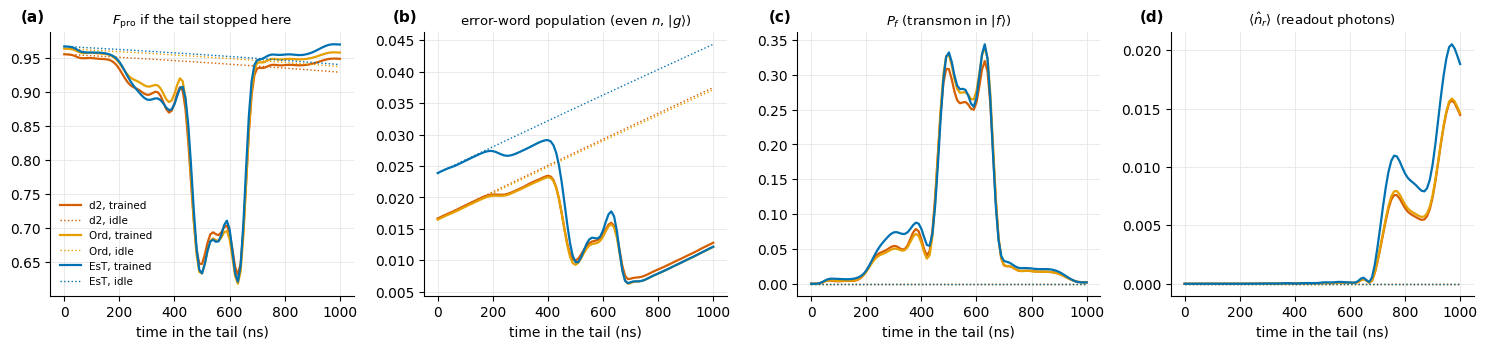

In [20]:
def tail_trace(g, eta, chunk=5):
    # Observables over the tail, every chunk * 2 ns, averaged over the code inputs |0_L>, |1_L>; F_pro if the
    # tail stopped there. Chunking is exact: the frame has no carriers, so nothing depends on absolute time.
    pulse = None if TAIL_GATES[g] is None else np.load(TAIL_GATES[g])
    R = ft.tail_input(pulse, N_C, 2, TAIL_GATE_NC[g])
    tm = ft.tail_model(N_C, 2)
    Tt, Wt = ft.tail_targets(N_C, 2)
    o = operators(N_C, 2)
    d = tm.model.d
    n_of, j_of = np.arange(d) // 6, (np.arange(d) // 2) % 3
    err_g = ((n_of % 2 == 0) & (j_of == G)).astype(float)                    # even photon number, transmon g
    pe, pf, nr = (np.real(np.diag(o[k])) for k in ("Pe", "Pf", "n_r"))

    def obs(R, k):
        dg = np.real(np.einsum("bii->bi", R[:2])).mean(0)
        return {"t_ns": k * DT * 1e3, "F": ft.fidelity_from_outputs(R, Tt, Wt), "P_err": dg @ err_g,
                "P_e": dg @ pe, "P_f": dg @ pf, "n_r": dg @ nr}
    rows = [obs(R, 0)]
    for k in range(0, len(eta), chunk):
        R, _ = ft.propagate(tm, eta[k:k + chunk], R)
        rows.append(obs(R, min(k + chunk, len(eta))))
    return pd.DataFrame(rows)


T_SHOW = 1.0
traces = {}
for g in TAIL_GATES:
    eta = RUNS[(g, T_SHOW, BEST[(g, T_SHOW)])]["eta"]
    traces[(g, "trained")] = tail_trace(g, eta)
    traces[(g, "idle")] = tail_trace(g, np.zeros_like(eta))
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for (g, kind), tr in traces.items():
    for ax, key in zip(axes, ("F", "P_err", "P_f", "n_r")):
        ax.plot(tr.t_ns, tr[key], color=GCOL[g], lw=1.6 if kind == "trained" else 1.0,
                ls="-" if kind == "trained" else ":", label=f"{g}, {kind}")
for ax, lab in zip(axes, (r"$F_{\rm pro}$ if the tail stopped here",
                          "error-word population (even $n$, $|g\\rangle$)",
                          r"$P_f$ (transmon in $|f\rangle$)", r"$\langle\hat n_r\rangle$ (readout photons)")):
    ax.set_title(lab, fontsize=9.5)
    ax.set_xlabel("time in the tail (ns)")
    tidy(ax)
axes[0].legend(fontsize=7.5, frameon=False)
for ax, k in zip(axes, "abcd"):
    panel(ax, k)
fig.tight_layout()
fig.savefig("figures/fwm_tails_traces.png", dpi=150)
plt.show()

**Figure 7. Inside the 1 μs tail:** each gate's trained tail (solid) against an idle tail (dotted), mean over the two
code inputs. (a) $F_{\rm pro}$ if the tail stopped there; (b) population in error words (even photon number,
transmon in $|g\rangle$); (c) $P_f$; (d) readout photons.
*Symbols:* $P_f$ = transmon population in $|f\rangle$; $\langle\hat n_r\rangle$ = mean readout photon number.

**What it shows.** The shot moves the error words up through $|f\rangle$ into the readout, for every gate alike.

- **(b)** EsT starts with more population in error words (0.024 against 0.017): its losses are still clean error
  words. During the shot (400–700 ns) every gate drops to about 0.007; with an idle tail EsT climbs to 0.044.
- **(c, d)** Up to 0.34 of the population passes through $|f\rangle$, where it can decay; the dumped excitation ends in
  the readout (0.019 photons for EsT, which empties on its own).
- **(a)** Mid-shot the fidelity dips to 0.62, then recovers. Only after EsT does it end above the gate alone (0.9699
  against 0.9671).

## 6.4 Why the gain is a quarter of the estimate

In [21]:
# Section 3.3's estimate against the trained EsT 1 us tail: a rough budget built from numbers measured above
g, T = "EsT", 1.0
est_total = tail_estimate(GAIN_REPAIR[g], T)[3]
mrow = MECH[(MECH.gate == g) & np.isclose(MECH["tail (us)"], T)].iloc[0]
slow = -LOSS_RATE * F_KITTEN * (UNPROT[T] - TAU_REPAIR)      # losses in the extra window: lost instead of repaired
other = mrow["gain, all but photon loss"]
measured = mrow["gain, all decay"]
budget = pd.DataFrame({"step": [
    "§3.3 estimate (τ = 0.3 μs, perfect repair, no transmon decay)",
    f"the shot leaves {UNPROT[T] * 1e3:.0f} ns unprotected, not {TAU_REPAIR * 1e3:.0f} ns",
    "transmon decay and the other non-loss channels",
    "remainder: the gate's losses repaired less well than ideally, overlaps",
    "measured gain (Table 6)"],
    "change in F_pro": [est_total, slow, other, measured - est_total - slow - other, measured]})
display(budget.style.hide(axis="index").format({"change in F_pro": "{:+.2%}"})
        .set_caption("Table 9. From the §3.3 estimate to the measured gain, EsT gate, 1 μs tail"))

step,change in F_pro
"§3.3 estimate (τ = 0.3 μs, perfect repair, no transmon decay)",+1.23%
"the shot leaves 498 ns unprotected, not 300 ns",-0.41%
transmon decay and the other non-loss channels,-0.25%
"remainder: the gate's losses repaired less well than ideally, overlaps",-0.29%
measured gain (Table 6),+0.28%


**Table 9. From the §3.3 estimate to the measured gain** (EsT gate, 1 μs tail). A rough budget: rows overlap, and the
remainder holds what is left.
*Symbols:* $\tau$ = the repair time the estimate assumed (0.3 μs); unprotected = Table 7's window, costed at
$\bar n\kappa_a \times 0.935$ per μs beyond $\tau$; non-loss = "gain, all but photon loss" of Table 8.

**What it shows.** Of the +1.23 % the estimate allows, the slow shot and transmon decay take about half: the slow shot
−0.41 % (498 ns unprotected instead of 300 ns), non-loss channels −0.25 %, and a remainder −0.29 % (losses repaired
less well than ideal: 0.92 before the shot, 0.851 during the gate; plus overlaps). What is left is the measured
+0.28 %.

## 6.5 Robustness

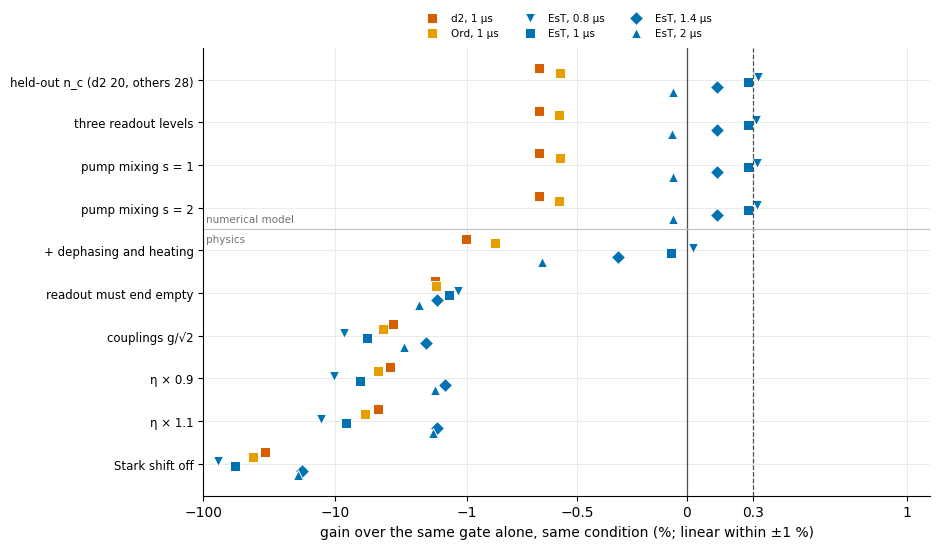

In [22]:
ROB = {"nc_b": "held-out n_c (d2 20, others 28)", "nr3": "three readout levels", "mix1": "pump mixing s = 1",
       "mix2": "pump mixing s = 2", "all_ch": "+ dephasing and heating", "empty": "readout must end empty",
       "g/sqrt2": "couplings g/√2", "eta_x0.9": "η × 0.9", "eta_x1.1": "η × 1.1", "stark_off": "Stark shift off"}
N_NUMERIC = 4                                             # the first four rows change only the numerical model
SHOW = [("d2", 1.0, "s"), ("Ord", 1.0, "s"), ("EsT", 0.8, "v"), ("EsT", 1.0, "s"), ("EsT", 1.4, "D"), ("EsT", 2.0, "^")]
fig, ax = plt.subplots(figsize=(9.5, 5.6))
for k, (g, T, mk) in enumerate(SHOW):
    r, tr, al, _ = tail_run(g, T)
    gain = {c: tr.loc[c, "gain_vs_alone"] for c in ROB if c != "empty"}
    gain["empty"] = tr.loc["train", "F_empty"] - al.loc["train", "F_empty"]
    y = np.arange(len(ROB)) + 0.11 * (k - (len(SHOW) - 1) / 2)
    ax.plot([gain[c] * 100 for c in ROB], y, ls="none", marker=mk, ms=7, color=GCOL[g], mec="white", mew=0.7,
            label=f"{g}, {T:g} μs")
ax.set_xscale("symlog", linthresh=1.0, linscale=1.5)
ax.set_xlim(-100, 1.5)
ax.set_xticks([-100, -10, -1, -0.5, 0, 0.3, 1])
ax.set_xticklabels(["−100", "−10", "−1", "−0.5", "0", "0.3", "1"])
ax.axvline(0, color="0.3", lw=0.9)
ax.axvline(0.3, color="0.3", lw=0.9, ls="--")
ax.axhline(N_NUMERIC - 0.5, color="0.75", lw=0.8)
ax.text(-95, N_NUMERIC - 0.62, "numerical model", fontsize=7.5, color="0.45", va="bottom")
ax.text(-95, N_NUMERIC - 0.38, "physics", fontsize=7.5, color="0.45", va="top")
ax.set_yticks(np.arange(len(ROB)))
ax.set_yticklabels(list(ROB.values()), fontsize=8.5)
ax.invert_yaxis()
ax.set_xlabel("gain over the same gate alone, same condition (%; linear within ±1 %)")
ax.legend(fontsize=7.5, frameon=False, ncol=3, loc="lower center", bbox_to_anchor=(0.5, 1.0))
tidy(ax)
fig.tight_layout()
fig.savefig("figures/fwm_tails_heldout.png", dpi=150)
plt.show()

**Figure 8. Gain over the gate alone under held-out conditions,** for the 1 μs tails of d2 and Ord and every EsT tail
that builds a shot; the gate alone is scored the same way. Above the line: numerical changes only; below: physics.
Every condition and run: Table C8; end state: Table C9.
*Symbols:* $g/\sqrt2$ = both pump couplings divided by $\sqrt2$; $s$ = pump-mixing strength; $\eta \times 0.9$,
$\times 1.1$ = both pump amplitudes scaled; readout must end empty = $F_{\rm empty}$; the axis is linear within ±1 %
and logarithmic beyond.

**What it shows.** The numerics hold; the physics does not forgive.

- **Numerical model:** $n_c$ 28, three readout levels and pump mixing move no gain by more than 0.01 %.
- **Dephasing and heating remove the gain:** +0.03 % (0.8 μs), −0.07 % (1 μs), −0.31 % (1.4 μs).
- **A readout that must end empty** costs 1.2–2.3 %: the repaired losses sit in the readout, which would empty within
  $1/\kappa_r$ = 0.27 μs (Table C9).
- **Pump calibration is critical.** A 10 % amplitude error costs the 0.8 μs tail 10.3 % (× 0.9) and 12.8 % (× 1.1),
  the 1 μs tail 6.5 % and 8.2 %; Stark shift off costs 77 % and 58 %. The best tail (0.8 μs) is the most fragile; the 1.4 μs zero
  start is the least (−1.5 %, −1.7 %, −18 %).

## 6.6 The tails alone: repair without changing the code

§6.1–§6.5 score every tail after the gate, so a gain mixes two things: how well the tail repairs photon loss, and how
much it disturbs the states that need no repair. Here each EsT tail runs with **no gate in front**, on ideal inputs,
and is scored against the identity (I). A good tail fixes damage without changing the logical information.

- **Code words:** the code's process inputs, as in every $F_{\rm pro}$ here. A perfect tail leaves them alone: $F = 1$.
- **One-loss error words:** the same inputs with one photon removed, $\hat a\hat\rho\hat a^\dagger/3$ (both code words
  hold $\bar n = 3$ photons). With no repair $F = 0$; the best photon-adding repair reaches the kitten limit 0.935
  (§2.2), so the **repaired fraction** is $F/0.935$.
- **An equal mix of the two** needs no extra run: $F_{\rm pro}$ is linear in the input, and both error words have the
  same norm, so $F_{50/50} = (F_{\rm code} + F_{\rm err})/2$ exactly (tested). The same two numbers give the
  **break-even loss probability** $p^*$. With a fraction $p$ of error words the tail scores
  $(1-p)F_{\rm code} + pF_{\rm err}$ and doing nothing scores $1-p$, so the tail wins when
  $p > p^* = (1-F_{\rm code})/(1-F_{\rm code}+F_{\rm err})$.

Closed (no jumps) asks whether the tail changes the logical information. Open (decay set) adds the tail's own photon
losses, which it can also repair, and its transmon and readout decay. $n_c = 16$, two readout levels, readout traced,
no free rotation (the best logical Z rotation is computed too). An idle tail of each length is the reference. The
tails are §6.1's EsT tails, both starts; the figure and tables show the better start of Table 6.

**Two limits of this test.** A clean error word is a photon lost right at the end of a perfect gate. A loss inside the
gate arrives changed by the gate and repairs less well even ideally (0.851 on average instead of 0.935, §2.2), so
$F_{\rm err}$ is an upper bound for the real gate output. And the ideal inputs carry none of the gate's other errors
(transmon excitation, coherent error; Figure 3).

**Code.** `DGRAPE/fwm_tail_code.py` (forward only, ~2 min with 8 jobs) → `tables/fwm_tail_code_lengths.csv`, with
one decay channel at a time as well; the scoring is `fwm_tail.code_word_scores`, also behind Table 16.

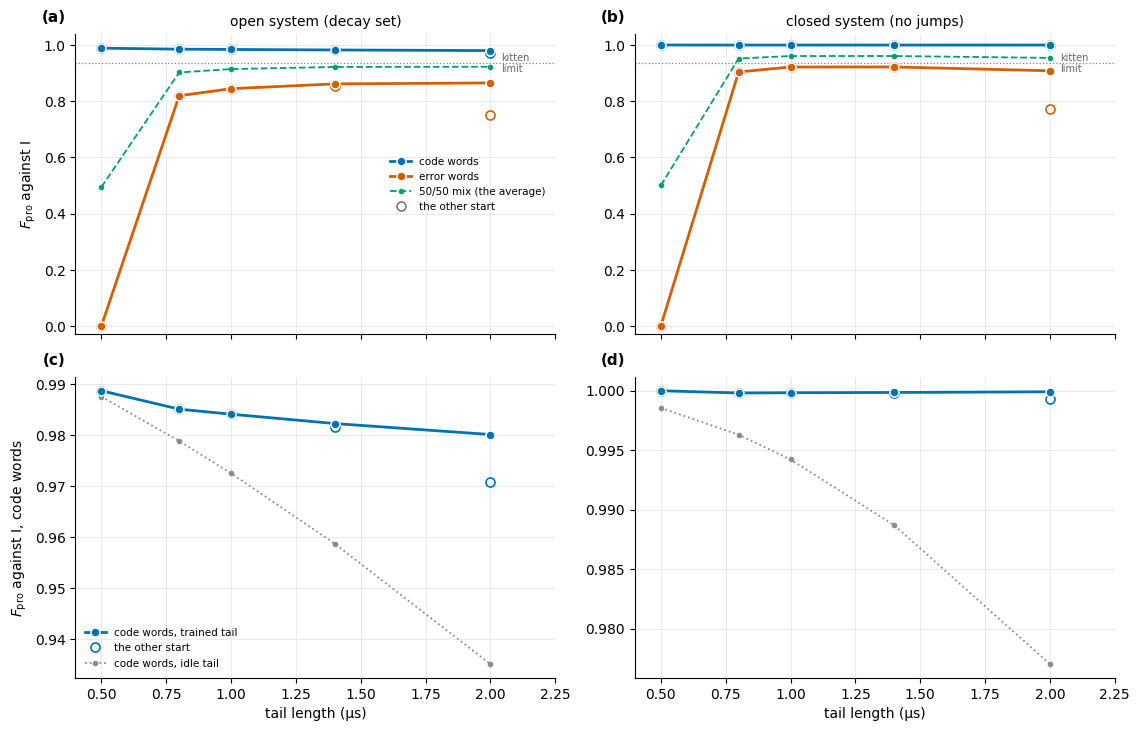

In [23]:
# Section 6.6: the EsT tails with no gate in front (DGRAPE/fwm_tail_code.py; forward only, cached).
# Recompute: delete the CSV, or run  python3 DGRAPE/fwm_tail_code.py --n-jobs 8   (~2 min)
ALONE_CSV = "tables/fwm_tail_code_lengths.csv"
if not os.path.exists(ALONE_CSV):
    import subprocess
    subprocess.run([sys.executable, "DGRAPE/fwm_tail_code.py", "--n-jobs", "8"], check=True)
ALONE = pd.read_csv(ALONE_CSV).fillna({"start": ""})
CHAN = {"photon loss only": "photon loss", "transmon decay only": "transmon decay",
        "readout decay only": "readout decay"}
OTHER = {"t2": "z", "z": "t2"}


def alone_F(tail, T, system, start="", col="F_vs_I"):
    """{input: F} for one tail ("X tail" or "idle"), length, system and start."""
    d = ALONE[(ALONE["tail"] == tail) & np.isclose(ALONE.tail_us, T) & (ALONE.system == system)
              & (ALONE.start == start)]
    return d.set_index("input")[col]


alone_rows = []
for T in EST_T:
    s = BEST[("EsT", T)]
    for system in ("open", "closed"):
        F, Fz = alone_F("X tail", T, system, s), alone_F("X tail", T, system, s, "F_best_Rz")
        Fc, Fe = F["code words"], F["one-loss error words"]
        alone_rows.append({"tail (μs)": T, "start": STARTS[s], "system": system, "code words": Fc,
                           "idle: code words": alone_F("idle", T, system)["code words"], "error words": Fe,
                           "repaired fraction": Fe / F_KITTEN, "50/50 mix": 0.5 * (Fc + Fe),
                           "break-even p*": (1 - Fc) / (1 - Fc + Fe),
                           "free Z adds": max(Fz["code words"] - Fc, Fz["one-loss error words"] - Fe)})
ALONE_TAB = pd.DataFrame(alone_rows)

IN_COL = {"code words": OKABE[0], "error words": OKABE[4], "50/50 mix": OKABE[2]}
IN_KEY = {"code words": "code words", "error words": "one-loss error words"}
fig, axes = plt.subplots(2, 2, figsize=(11.5, 7.4), sharex=True)
for col, system in enumerate(("open", "closed")):
    d = ALONE_TAB[ALONE_TAB.system == system]
    other = {T: alone_F("X tail", T, system, OTHER[BEST[("EsT", T)]]) for T in EST_T}
    ax = axes[0, col]
    for key in ("code words", "error words"):
        ax.plot(d["tail (μs)"], d[key], color=IN_COL[key], lw=2.0, marker="o", ms=6.5, mec="white", mew=1.1,
                zorder=4, label=key)
        ax.plot(EST_T, [other[T][IN_KEY[key]] for T in EST_T], marker="o", ms=6.5, mfc="white", mec=IN_COL[key],
                mew=1.2, ls="none", zorder=3)
    ax.plot(d["tail (μs)"], d["50/50 mix"], color=IN_COL["50/50 mix"], lw=1.3, ls="--", marker=".", ms=6,
            label="50/50 mix (the average)")
    ax.plot([], [], marker="o", ms=6.5, mfc="white", mec="0.4", ls="none", label="the other start")
    ax.axhline(F_KITTEN, color="0.5", ls=":", lw=0.9)
    ax.text(2.04, F_KITTEN, "kitten\nlimit", fontsize=7, color="0.4", va="center")
    ax.set_ylim(-0.03, 1.04)
    ax.set_title(f"{system} system ({'decay set' if system == 'open' else 'no jumps'})", fontsize=10)
    ax = axes[1, col]
    ax.plot(d["tail (μs)"], d["code words"], color=IN_COL["code words"], lw=2.0, marker="o", ms=6.5, mec="white",
            mew=1.1, zorder=4, label="code words, trained tail")
    ax.plot(EST_T, [other[T]["code words"] for T in EST_T], marker="o", ms=6.5, mfc="white",
            mec=IN_COL["code words"], mew=1.2, ls="none", zorder=3, label="the other start")
    ax.plot(d["tail (μs)"], d["idle: code words"], color="0.55", ls=":", lw=1.3, marker=".",
            label="code words, idle tail")
    ax.set_xlabel("tail length (μs)")
for ax, k in zip(axes.flat, "abcd"):
    ax.set_xlim(0.4, 2.25)
    tidy(ax)
    panel(ax, k)
axes[0, 0].set_ylabel(r"$F_{\rm pro}$ against I")
axes[1, 0].set_ylabel(r"$F_{\rm pro}$ against I, code words")
axes[0, 0].legend(fontsize=7.5, frameon=False, loc="center right")
axes[1, 0].legend(fontsize=7.5, frameon=False, loc="lower left")
fig.tight_layout()
fig.savefig("figures/fwm_tails_alone_lengths.png", dpi=150)
plt.show()

**Figure 9. The EsT tails with no gate in front, against tail length.** Columns: (a, c) open system, decay set;
(b, d) closed, no jumps. Top: code words (blue), one-loss error words (vermilion) and their 50/50 mix (green dashed,
the exact average); filled = the better start (Table 6), open circles = the other start; dotted line: the kitten
limit. Bottom: the code words close up, with an idle tail of the same length (grey dotted). Numbers: Table 10.
*Symbols:* $F_{\rm pro}$ against I = process fidelity of the tail alone against the identity on the code, readout
traced, no free rotation, $n_c = 16$; error words = $\hat a\hat\rho\hat a^\dagger/3$ of the code's process inputs.

**What it shows.** Every tail leaves the code alone; every tail that builds a shot repairs most of a clean error word,
and the open system takes a slice of that repair that shrinks as the tail gets longer.

- **The code words are left alone.** Closed, every tail keeps them at 0.9998–1.0000, while an idle wait loses 0.15 %
  (0.5 μs) to 2.3 % (2 μs) to the storage Kerr phase. Even the 0.5 μs tail, which repairs nothing
  ($\max|\eta_c|$ 0.013), cancels that phase. A free logical Z rotation adds at most 0.002 anywhere (Table 10): the
  tails leave no logical rotation behind.
- **Closed, a clean error word is repaired almost to the kitten limit:** 0.904 (0.8 μs), 0.922 (1 and 1.4 μs), 0.908
  (2 μs), 97–99 % of 0.935. The 0.5 μs tail repairs nothing (0.0001).
- **Open, the repair drops by 8.5 points at 0.8 μs and 4.3 at 2 μs** (0.820 to 0.865, 88–92 % of the kitten limit).
  Table 11 says where it goes.
- **Open, the code words pay for the tail's time, minus what it repairs:** 0.985 at 0.8 μs against 0.979 idle, 0.980
  at 2 μs against 0.935 idle.
- **The two starts agree** to 0.003 up to 1 μs. At 2 μs the zero start, much the worse one after the gate (0.9548
  against 0.9664), repairs a clean error word only to 0.773 (closed).

In [24]:
fmt = {"tail (μs)": "{:g}", "repaired fraction": "{:.1%}", "break-even p*": "{:.2%}", "free Z adds": "{:.5f}",
       **{c: "{:.5f}" for c in ("code words", "idle: code words", "error words", "50/50 mix")}}
display(ALONE_TAB.style.hide(axis="index").format(fmt)
        .set_caption("Table 10. The EsT tails with no gate in front"))

tail (μs),start,system,code words,idle: code words,error words,repaired fraction,50/50 mix,break-even p*,free Z adds
0.5,QEC teeth,open,0.98877,0.98761,0.00013,0.0%,0.49445,98.86%,0.00000
0.5,QEC teeth,closed,0.99999,0.99855,0.00015,0.0%,0.50007,6.30%,0.00000
0.8,QEC teeth,open,0.98515,0.97889,0.81952,87.6%,0.90234,1.78%,0.00202
0.8,QEC teeth,closed,0.99980,0.99629,0.90414,96.7%,0.95197,0.02%,0.00080
1,zero + noise,open,0.98416,0.97256,0.84455,90.3%,0.91436,1.84%,0.00189
1,zero + noise,closed,0.99982,0.99421,0.92172,98.6%,0.96077,0.02%,0.00077
1.4,zero + noise,open,0.98232,0.95871,0.86164,92.1%,0.92198,2.01%,0.00084
1.4,zero + noise,closed,0.99985,0.98868,0.92184,98.6%,0.96084,0.02%,0.00011
2,QEC teeth,open,0.98017,0.93507,0.86506,92.5%,0.92261,2.24%,0.00020
2,QEC teeth,closed,0.99990,0.97701,0.90832,97.1%,0.95411,0.01%,0.00012


**Table 10. The EsT tails with no gate in front,** better start, open and closed.
*Symbols:* code words, error words = $F_{\rm pro}$ against I of the tail alone on each input (Figure 9); idle: code
words = the same for an idle tail of that length; repaired fraction = error words / 0.935 (the kitten limit); 50/50 mix
= the average of the two; break-even $p^*$ = $(1-F_{\rm code})/(1-F_{\rm code}+F_{\rm err})$, the fraction of error
words above which the tail beats doing nothing; free Z adds = the most a free logical Z rotation adds, over both inputs.

**What it shows.**

- **Closed, $p^*$ is 0.01–0.02 %:** without decay the tail is worth running for almost any error fraction, because it
  costs the code words almost nothing.
- **Open, $p^*$ is 1.8 % (0.8 μs) to 2.2 % (2 μs),** against the EsT gate's 2.68 % photon losses (Table 12). The gate
  loses only a little more than that, one reason the gains of Table 6 are small (Table 12).
- **At 0.5 μs** the tail never pays ($p^*$ 99 % open): it repairs nothing and only spends time.

In [25]:
chan_rows = []
for T in SHOT_T:
    s = BEST[("EsT", T)]
    F_cl = alone_F("X tail", T, "closed", s)
    row = {"tail (μs)": T, "start": STARTS[s]}
    for inp, short in (("code words", "code"), ("one-loss error words", "error")):
        for system, name in CHAN.items():
            row[f"{short}: {name}"] = F_cl[inp] - alone_F("X tail", T, system, s)[inp]
            if short == "code" and system == "photon loss only":       # an idle wait repairs nothing
                row["code: photon loss, idle"] = alone_F("idle", T, "closed")[inp] - alone_F("idle", T, "open")[inp]
        row[f"{short}: decay set"] = F_cl[inp] - alone_F("X tail", T, "open", s)[inp]
    chan_rows.append(row)
CHAN_TAB = pd.DataFrame(chan_rows)
display(CHAN_TAB.style.hide(axis="index")
        .format({"tail (μs)": "{:g}", **{c: "{:.2%}" for c in CHAN_TAB.columns[2:]}})
        .set_caption("Table 11. Where the open-system cost of the tails alone goes"))

tail (μs),start,code: photon loss,"code: photon loss, idle",code: transmon decay,code: readout decay,code: decay set,error: photon loss,error: transmon decay,error: readout decay,error: decay set
0.8,QEC teeth,1.13%,1.74%,0.25%,0.03%,1.47%,1.56%,0.93%,6.18%,8.46%
1,zero + noise,1.23%,2.16%,0.25%,0.03%,1.57%,1.93%,1.04%,4.95%,7.72%
1.4,zero + noise,1.45%,3.00%,0.21%,0.03%,1.75%,2.62%,1.24%,2.33%,6.02%
2,QEC teeth,1.69%,4.19%,0.22%,0.04%,1.97%,3.52%,1.30%,-0.43%,4.33%


**Table 11. Where the open-system cost of the tails alone goes,** one decay channel at a time, for the tails that
build a shot (better start).
*Symbols:* each entry = $F_{\rm pro}$ closed − $F_{\rm pro}$ with only that channel (photon loss $\hat a$; transmon decay
$g\leftarrow e\leftarrow f$; readout decay $\hat r$), against I; decay set = all three together (closed − open in
Table 10); code: photon loss, idle = the same for an idle tail (its only cost: the transmon stays in $g$, the readout
empty).

**What it shows.** The channels add up to the decay-set cost to within 0.25 %.

- **Code words: the tail repairs part of its own photon losses.** Photon loss costs the code words 1.13 % over 0.8 μs
  against 1.74 % for an idle wait, and 1.69 % against 4.19 % over 2 μs: losses before the shot are repaired (§6.2),
  about a third of them at 0.8 μs and 60 % at 2 μs. Transmon decay costs the code words 0.2–0.25 %, so the pumps also
  excite the transmon briefly from the code words (closed, it all comes back).
- **Error words: readout decay is the largest cost of a short repair,** 6.2 % at 0.8 μs and 5.0 % at 1 μs, falling to
  2.3 % at 1.4 μs and −0.4 % at 2 μs (there readout decay helps a little). The repair hands the photon to the readout
  (comb 2, $|n, f, 0\rangle \to |n+1, g, 1\rangle$); why decay of that photon hurts the fast shots and not the slow
  one is not yet separated. §9 saw the same effect on early losses (0.83 → 0.77).
- **Second photon losses grow with the tail** (1.6 % → 3.5 % on error words), and transmon decay costs about 1 %
  at every length.

In [26]:
base = pd.read_csv("tables/fwm_tail_H_baselines.csv").dropna(subset=["loss_prob"]).set_index("gate").loc["EsT-X"]
P_LOSS, F_MID = base.loss_prob, base.mid_gate_repaired          # photon losses per gate; a mid-gate loss, ideally repaired
est_rows = []
for T in SHOT_T:
    r = ALONE_TAB[(ALONE_TAB.system == "open") & np.isclose(ALONE_TAB["tail (μs)"], T)].iloc[0]
    cost = (1 - P_LOSS) * (1 - r["code words"])
    dressed = P_LOSS * r["error words"] * F_MID / F_KITTEN - cost
    measured = HEAD[(HEAD.gate == "EsT") & np.isclose(HEAD["tail (μs)"], T)]["vs gate alone"].iloc[0]
    est_rows.append({"tail (μs)": T, "break-even p*": r["break-even p*"], "repair, clean": P_LOSS * r["error words"],
                     "cost on the rest": -cost, "estimate, clean losses": P_LOSS * r["error words"] - cost,
                     "estimate, losses inside the gate": dressed, "measured (Table 6)": measured,
                     "remainder": measured - dressed})
EST_TAB = pd.DataFrame(est_rows)
display(EST_TAB.style.hide(axis="index")
        .format({"tail (μs)": "{:g}", "break-even p*": "{:.2%}", **{c: "{:+.5f}" for c in EST_TAB.columns[2:]}})
        .set_caption("Table 12. From the tail alone to the tail after the gate"))
print(f"EsT gate: photon losses per gate p = {P_LOSS:.4f}; a mid-gate loss, ideally repaired: {F_MID:.3f} "
      f"(a loss right after a perfect gate: {F_KITTEN:.3f})")

tail (μs),break-even p*,"repair, clean",cost on the rest,"estimate, clean losses","estimate, losses inside the gate",measured (Table 6),remainder
0.8,1.78%,+0.02193,-0.01445,+0.00748,+0.00549,+0.00321,-0.00228
1,1.84%,+0.02260,-0.01541,+0.00718,+0.00513,+0.00279,-0.00234
1.4,2.01%,+0.02305,-0.01720,+0.00585,+0.00376,+0.00137,-0.00239
2,2.24%,+0.02315,-0.01930,+0.00384,+0.00175,-0.00064,-0.00239


EsT gate: photon losses per gate p = 0.0268; a mid-gate loss, ideally repaired: 0.850 (a loss right after a perfect gate: 0.935)


**Table 12. From the tail alone to the tail after the gate** (EsT gate, open system). A linear estimate of Table 6's
gain from Table 10: a fraction $p$ of the gate's output is one-loss error words, which the tail repairs, and the rest
is code words, which pay the tail's cost.
*Symbols:* $p$ = 2.68 %, the gate's photon losses (printed); repair, clean = $p\,F_{\rm err}$; cost on the rest =
$-(1-p)(1-F_{\rm code})$; estimate, clean losses = their sum; estimate, losses inside the gate = the same with the
repair scaled by 0.851/0.935 (§2.2: a loss inside the gate repairs less well, even ideally); remainder = measured −
that estimate. Plain differences in $F_{\rm pro}$.

**What it shows.** The tail-alone numbers explain all but a constant 0.23–0.24 % of the measured gain.

- **Clean losses would give +0.75 % at 0.8 μs;** scaled for losses inside the gate, +0.55 %; measured +0.32 %.
- **The remainder is the same at every length** (−0.23 % to −0.24 %), close to Table 9's non-loss term (−0.25 % at
  1 μs): what the tail does to the gate's other errors, which the ideal inputs do not carry.
- **Every μs of tail costs the code words, and the repair gains little after 1 μs** (Table 10), so the estimate falls
  from 0.8 μs on, like the measured gain.

**What this says.** The tails do what a corrector should: closed, they leave the code words alone (≥ 0.9998) and
repair clean error words to 97–99 % of the kitten limit. The gains after the gate are small for three reasons: the
gate loses only 2.7 % photons, just above the 1.8–2.2 % break-even; the open-system repair loses 4–9 points, at
0.8–1 μs mostly to readout decay; and a constant 0.23 % that the ideal inputs do not explain.

# 7. Tails after the H gate

§6 trains tails after an X gate only. Does the idea carry over to another logical gate? This section takes the EsT
**H gate** (Hadamard) picked in `est_gate_selection.ipynb` §7: seed 17 of the same $C_{\rm err}$ cost, closed-system
F1 0.99968, `pulses/dgrape/u_H_est_err_closed_T2_s17.npy`. It had to be **2 μs** long to be transparent on this chip,
against 1.1 μs for the X gate, so it loses more photons. Three questions:

1. **Does a QEC tail work after the H gate?** A 0.8 μs tail is trained for it from a cold start (§7.2).
2. **How does that H tail differ from the X tail?** (§7.3)
3. **Does the X tail, put unchanged after the H gate, correct errors the same way?** And the H tail after the X gate?
   (§7.4)

**What runs.** The recipe of §5, unchanged except for the gate and its target: the H gate is propagated at
$n_c = 24$, its output cut to $n_c = 16$ (it ends with $2\times10^{-7}$ above Fock 16), then the 0.8 μs tail, scored
against the ideal H (readout traced, decay set, no free rotation). Two cold starts, as everywhere in this notebook:
the QEC teeth (`t2`) and zero + noise (`z`, noise 0.005, seed 1), 600 iterations each; the better one is kept. The
X tail is the best tail of §6 (`X_tail_estg_T08_t2`, +0.32 %). "X gate" here is the EsT X gate of §3–§6.

**Code.** `DGRAPE/fwm_tail_hgate.py` (fixed-tail scores, loss-time profiles, the tails with no gate in front, and the
swapped runs for the held-out scorer); training with `DGRAPE/train_fwm_tail.py --target H`; held-out scores with
`DGRAPE/fwm_tail_score.py`.

In [27]:
# Section 7: tails after the EsT H gate (DGRAPE/fwm_tail_hgate.py; forward only, cached in four CSVs).
# Recompute: delete the CSVs and run (OPENBLAS_NUM_THREADS=1 on the PC)
#   python DGRAPE/fwm_tail_hgate.py baselines --n-jobs 8       (Table 13, ~3 min)
#   python DGRAPE/fwm_tail_hgate.py profiles --n-jobs 6        (Figures 10c and 11, ~5 min)
#   python DGRAPE/fwm_tail_hgate.py code --n-jobs 5            (Table 16, ~1 min)
#   python DGRAPE/fwm_tail_hgate.py cross-json --indir ~/fwm_runs/tails_H/score
#   python DGRAPE/fwm_tail_score.py --tags H_tail_esth_T08_t2 H_tail_esth_T08_z H_xtail_T08 X_htail_T08 \
#       --indir ~/fwm_runs/tails_H/score --out tables/fwm_tail_heldout_H.csv --n-jobs 12     (Tables 14-15)
from DGRAPE import fwm_tail_hgate as fh

HG = {"EsT-X": "X", "EsT-H": "H"}                          # gate label -> target
HCOL = {"EsT-X": OKABE[0], "EsT-H": OKABE[3]}              # X: the EsT blue; H: reddish purple
TCOL = {"X tail": OKABE[0], "H tail": OKABE[3], "idle": "0.6"}
HB = pd.read_csv("tables/fwm_tail_H_baselines.csv")
HPROF = pd.read_csv("tables/fwm_tail_H_profiles.csv")
HCODE = pd.read_csv("tables/fwm_tail_H_code.csv")
_hx = pd.read_csv("tables/fwm_tail_heldout_good.csv")
_hx = _hx[((_hx.kind == "trained") & _hx.tag.isin([tail_tag("EsT", 0.8, s) for s in STARTS]))
          | ((_hx.kind != "trained") & _hx.tail_us.isin([0.0, 0.8]))]
HHELD = pd.concat([pd.read_csv("tables/fwm_tail_heldout_H.csv"), _hx], ignore_index=True)
HHELD["gate"] = HHELD.gate.replace({"EsT-good": "EsT-X"})
# the H table re-scores the X gate's references (for the H tail after X); they must agree with the X table, then keep one
_key = ["gate", "kind", "tag", "tail_us", "condition"]
_dup = HHELD[HHELD.duplicated(_key, keep=False)].groupby(_key).F_pro
print(f"X-gate references scored twice: {_dup.ngroups}, largest disagreement {(_dup.max() - _dup.min()).max():.1e}")
HHELD = HHELD.drop_duplicates(_key).reset_index(drop=True)


def hheld(gate, kind, tag=None):
    """Held-out rows of one gate and kind (trained: one tag), indexed by condition."""
    q = (HHELD.gate == gate) & (HHELD.kind == kind)
    if tag is not None:
        q &= HHELD.tag == tag
    if kind in ("idle", "teeth"):
        q &= np.isclose(HHELD.tail_us, 0.8)
    return HHELD[q].set_index("condition")


H_RUNS = {s: load_run(f"H_tail_esth_T08_{s}") for s in STARTS}           # start -> (info, eta)
X_RUNS = {s: load_run(tail_tag("EsT", 0.8, s)) for s in STARTS}
H_BEST = max(H_RUNS, key=lambda s: H_RUNS[s][0]["F_pro"])
X_BEST = BEST[("EsT", 0.8)]
H_TAG, X_TAG = f"H_tail_esth_T08_{H_BEST}", tail_tag("EsT", 0.8, X_BEST)
assert H_TAG == fh.best_h_tail()[0] and X_TAG == fh.X_TAIL
ETA_H, ETA_X = H_RUNS[H_BEST][1], X_RUNS[X_BEST][1]

# checks against section 6: the X gate + its tail, and the X gate alone, as in Table 6 / Table 3
b = HB.set_index(["gate", "tail"])
print(f"checks: EsT-X + X tail {b.loc[('EsT-X', 'X tail'), 'F_pro']:.6f} (Table 6: "
      f"{RUNS[('EsT', 0.8, X_BEST)]['info']['F_pro']:.6f}); EsT-X alone {b.loc[('EsT-X', 'none'), 'F_pro']:.6f} "
      f"(section 6: {F_ALONE['EsT']:.6f}); EsT-H alone {b.loc[('EsT-H', 'none'), 'F_pro']:.6f}")
lp = LP[np.isclose(LP.tail_us, 0.8)].set_index("t_ns").f_branch
mine = HPROF[(HPROF.gate == "EsT-X") & (HPROF["tail"] == "X tail")].set_index("t_ns").f_branch
print(f"loss-time profile of the X tail, against section 6.2's cache: max difference {np.abs(mine - lp).max():.1e}")

X-gate references scored twice: 29, largest disagreement 0.0e+00
checks: EsT-X + X tail 0.970272 (Table 6: 0.970272); EsT-X alone 0.967059 (section 6: 0.967059); EsT-H alone 0.950135
loss-time profile of the X tail, against section 6.2's cache: max difference 1.3e-15


## 7.1 What the H gate leaves to repair

Before any training: the H gate against the X gate, alone, with the upper limit of §2.1 (an instant ideal repair at the
end of the gate), and with fixed 0.8 μs tails. The last two rows are the trained tails, for reference here; each is
used after both gates.

In [28]:
ceil = HB[HB["tail"].isna()].set_index("gate")
rows = {}
for g in HG:
    c = ceil.loc[g]
    r = {"gate length (μs)": c.T_gate_us, "F_pro alone": b.loc[(g, "none"), "F_pro"],
         "photon losses per gate": c.loss_prob, "a mid-gate loss, ideally repaired to": c.mid_gate_repaired,
         "ideal instant repair at T_g": c.ideal_repair_gain}
    for t, lab in (("idle", "+ idle 0.8 μs"), ("QEC teeth", "+ QEC teeth 0.8 μs"), ("X tail", "+ X tail (trained after X)"),
                   ("H tail", "+ H tail (trained after H)")):
        r[lab] = b.loc[(g, t), "gain_vs_alone"]
    rows[g] = r
GATE_TAB = pd.DataFrame(rows)
sty = GATE_TAB.style.format("{:+.2%}")
for row, f in {"gate length (μs)": "{:.1f}", "F_pro alone": "{:.5f}", "photon losses per gate": "{:.4f}",
               "a mid-gate loss, ideally repaired to": "{:.3f}"}.items():
    sty = sty.format(f, subset=pd.IndexSlice[[row], :])
display(sty.set_caption("Table 13. The EsT H gate against the EsT X gate, alone and with fixed 0.8 μs tails"))

,EsT-X,EsT-H
gate length (μs),1.1,2.0
F_pro alone,0.96706,0.95013
photon losses per gate,0.0268,0.0439
"a mid-gate loss, ideally repaired to",0.850,0.746
ideal instant repair at T_g,+1.99%,+3.09%
+ idle 0.8 μs,-2.05%,-2.00%
+ QEC teeth 0.8 μs,-2.22%,-2.15%
+ X tail (trained after X),+0.32%,+1.30%
+ H tail (trained after H),+0.13%,+1.19%


**Table 13. The EsT H gate against the EsT X gate, alone and with fixed 0.8 μs tails.** Gate at $n_c = 24$, tail at
16 (cut), decay set, readout traced. The H tail is the better start of §7.2.
*Symbols:* photon losses per gate = the probability of at least one storage photon loss during the gate (§2.2);
a mid-gate loss, ideally repaired to = the conditional $F_{\rm pro}$ of a loss in the middle of the gate after the
ideal repair (§2.2); ideal instant repair = the gain of an instant, perfect photon-add at $T_g$ (§2.1); the rows below
are gains over the same gate alone, in % of $F_{\rm pro}$.

**What it shows.**

- **The H gate has more to repair, and repairs less well.** Being 1.8 times longer, it loses a photon in 4.4 % of runs
  against 2.7 %, and ends at 0.9501 alone against 0.9671. Its losses are less repairable (0.75 against 0.85), but
  there are so many more that the ideal repair is worth more: +3.09 % against +1.99 %.
- **The fixed references cost the same after both gates:** an idle 0.8 μs tail −2.0 %, the QEC teeth −2.2 %. The
  tail's own time costs the same whatever came before.
- **The X tail, moved unchanged, already gains +1.30 % after the H gate,** four times its +0.32 % after the gate
  it was trained for, and 42 % of the H gate's ideal ceiling (16 % after X).

## 7.2 Training the H tail from a cold start

In [29]:
run_rows = []
for gate, runs, alone in (("EsT-H", H_RUNS, b.loc[("EsT-H", "none"), "F_pro"]),
                          ("EsT-X", X_RUNS, b.loc[("EsT-X", "none"), "F_pro"])):
    for s, (info, eta) in runs.items():
        tr = hheld(gate, "trained", info["tag"])
        Fh = np.array([e["F_pro"] for e in info["history"]])
        run_rows.append({"gate": gate, "start": STARTS[s], "F at start": info["F_pro_start"], "F trained": info["F_pro"],
                         "vs gate alone": info["F_pro"] - alone,
                         "vs idle tail": info["F_pro"] - b.loc[(gate, "idle"), "F_pro"],
                         "vs gate alone, n_c 28": tr.loc["nc_b", "gain_vs_alone"] if "nc_b" in tr.index else np.nan,
                         "gain, last 100 it": Fh[-1] - Fh[-101],
                         "max |η_1|": info["max_eta_1"], "max |η_2|": info["max_eta_2"],
                         "x pinned": info["frac_preimage_pinned"], "iterations": info["nit"],
                         "hours": info["wall_s"] / 3600, "returned": info["returned"]})
H_RUN_TAB = pd.DataFrame(run_rows)
gains = ["vs gate alone", "vs idle tail", "vs gate alone, n_c 28", "gain, last 100 it"]
display(H_RUN_TAB.style.hide(axis="index")
        .format({"F at start": "{:.5f}", "F trained": "{:.5f}", **{c: "{:+.2%}" for c in gains},
                 "max |η_1|": "{:.3f}", "max |η_2|": "{:.3f}", "x pinned": "{:.2%}", "hours": "{:.1f}"})
        .set_caption("Table 14. The 0.8 μs H tail, both cold starts, next to the X tail"))

gate,start,F at start,F trained,vs gate alone,vs idle tail,"vs gate alone, n_c 28","gain, last 100 it",max |η_1|,max |η_2|,x pinned,iterations,hours,returned
EsT-H,QEC teeth,0.92741,0.96200,+1.19%,+3.19%,+1.19%,-0.00%,0.074,0.099,0.00%,600,2.8,best_seen
EsT-H,zero + noise,0.92847,0.96197,+1.18%,+3.19%,+1.18%,-0.01%,0.073,0.100,0.00%,600,2.7,best_seen
EsT-X,QEC teeth,0.94370,0.97027,+0.32%,+2.37%,+0.32%,-0.00%,0.081,0.101,0.00%,600,8.1,best_seen
EsT-X,zero + noise,0.94488,0.97024,+0.32%,+2.37%,+0.32%,+0.01%,0.076,0.101,0.00%,600,7.9,final


**Table 14. The 0.8 μs H tail, both cold starts, next to the X tail** (§6). Both H runs: 600 iterations, two side by
side with two BLAS threads each, about 16 s per iteration.
*Symbols:* F at start = $F_{\rm pro}$ of the starting waveform; vs gate alone, vs idle tail = gain of the trained tail
over the same gate alone and over the gate + an idle 0.8 μs tail; $n_c$ 28 = the held-out truncation (gate and tail
both run there, no cut); gain, last 100 it = the change of $F_{\rm pro}$ over the last 100 iterations (negative: the
cost still falls through the derivative penalty); x pinned = share of the pre-image at its box; returned = the
iterate kept (the best seen).

**What it shows.**

- **Yes, a tail works after the H gate:** +1.19 % over the H gate alone (0.9501 → 0.9620), +3.19 % over an idle
  tail, the same at held-out $n_c = 28$.
- **Both cold starts end at the same place,** 0.96200 and 0.96197, within $3\times10^{-5}$, although they start from
  different waveforms; both had plateaued by iteration 300. Both stay under the cap with nothing pinned.
- **But both are worse than the X tail moved over unchanged** (+1.30 %, Table 13). The X tail is also better by the H
  tail's own training cost, $1 - F_{\rm pro}$ + the derivative penalty: 0.0404 against 0.0411, although its derivative
  penalty is the larger one (0.0036 against 0.0031). So training did not find the best tail for the H gate: both cold starts stop in a
  worse local optimum. §7.3 shows what that optimum is.

## 7.3 The H tail against the X tail

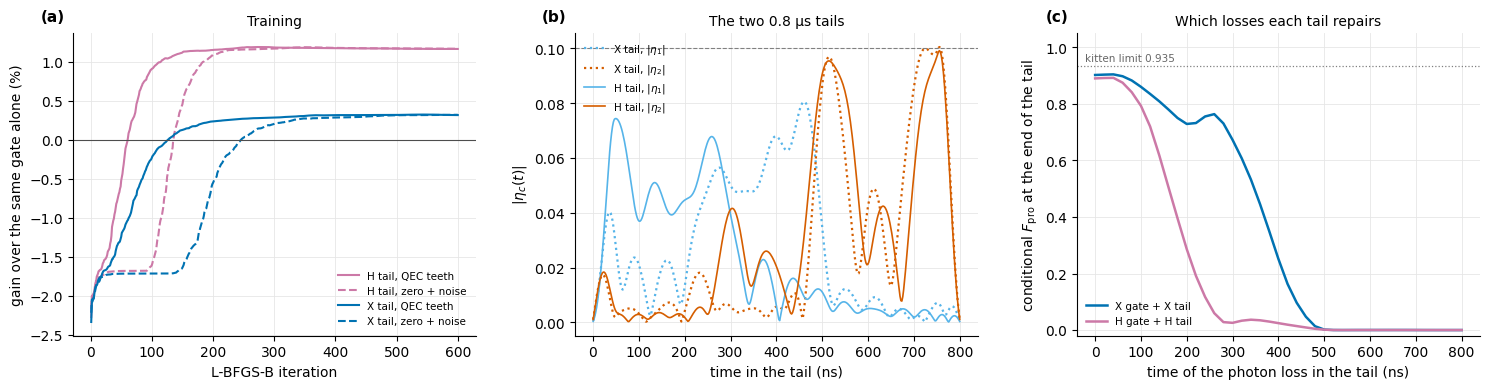

EsT-X + X tail: a loss at the start of the tail repaired to 0.902; below half from 440 ns before the end; unrepaired window 458 ns
EsT-H + H tail: a loss at the start of the tail repaired to 0.890; below half from 620 ns before the end; unrepaired window 613 ns
X tail: comb 1 peak 0.081 at 461 ns, comb 2 peak 0.101 at 755 ns; mean |eta_1|^2 + |eta_2|^2 = 3.21e-03
H tail: comb 1 peak 0.074 at 51 ns, comb 2 peak 0.099 at 755 ns; mean |eta_1|^2 + |eta_2|^2 = 3.00e-03
overlap of the two waveforms |<eta_X, eta_H>| / (|eta_X| |eta_H|) = 0.553, relative phase -0.04 rad; relative distance |eta_H - eta_X| / |eta_X| = 0.931


In [30]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.0))
ax = axes[0]                                              # (a) training, as gain over the same gate alone
for gate, runs in (("EsT-H", H_RUNS), ("EsT-X", X_RUNS)):
    alone = b.loc[(gate, "none"), "F_pro"]
    for s, (info, _) in runs.items():
        h = info["history"]
        ax.plot([e["it"] for e in h], [(e["F_pro"] - alone) * 100 for e in h], color=HCOL[gate],
                ls="-" if s == "t2" else "--", lw=1.5, label=f"{gate[-1]} tail, {STARTS[s]}")
ax.axhline(0, color="0.3", lw=0.8)
ax.set_xlabel("L-BFGS-B iteration")
ax.set_ylabel("gain over the same gate alone (%)")
ax.set_title("Training", fontsize=10)
ax.legend(fontsize=7.5, frameon=False, loc="lower right")
ax = axes[1]                                              # (b) the two waveforms
t_ns = (np.arange(len(ETA_H)) + 0.5) * DT * 1e3
for eta, lab, ls, lw in ((ETA_X, "X tail", ":", 1.6), (ETA_H, "H tail", "-", 1.2)):
    for c, col in ((0, OKABE[5]), (1, OKABE[4])):
        ax.plot(t_ns, np.abs(eta[:, c]), color=col, ls=ls, lw=lw, label=fr"{lab}, $|\eta_{c + 1}|$")
ax.axhline(ft.ETA_CAP, color="0.5", lw=0.8, ls="--")
ax.set_xlabel("time in the tail (ns)")
ax.set_ylabel(r"$|\eta_c(t)|$")
ax.set_title("The two 0.8 μs tails", fontsize=10)
ax.legend(fontsize=7.5, frameon=False, loc="upper left")
ax = axes[2]                                              # (c) which losses each tail repairs, after its own gate
for gate, tail in (("EsT-X", "X tail"), ("EsT-H", "H tail")):
    d = HPROF[(HPROF.gate == gate) & (HPROF["tail"] == tail)]
    ax.plot(d.t_ns, d.f_branch, color=HCOL[gate], lw=1.8, label=f"{gate[-1]} gate + {tail}")
ax.axhline(F_KITTEN, color="0.5", ls=":", lw=0.9)
ax.text(0.02, F_KITTEN + 0.015, f"kitten limit {F_KITTEN:.3f}", fontsize=7.5, color="0.4",
        transform=ax.get_yaxis_transform())
ax.set_ylim(-0.02, 1.05)
ax.set_xlabel("time of the photon loss in the tail (ns)")
ax.set_ylabel(r"conditional $F_{\rm pro}$ at the end of the tail")
ax.set_title("Which losses each tail repairs", fontsize=10)
ax.legend(fontsize=7.5, frameon=False, loc="lower left")
for ax, k in zip(axes, "abc"):
    tidy(ax)
    panel(ax, k)
fig.tight_layout(w_pad=2.5)
fig.savefig("figures/fwm_tails_H_vs_X.png", dpi=150)
plt.show()
for gate, tail in (("EsT-X", "X tail"), ("EsT-H", "H tail")):
    d = HPROF[(HPROF.gate == gate) & (HPROF["tail"] == tail)]
    f0, f = d.f_branch.iloc[0], d.f_branch.values
    step = np.diff(d.t_ns).mean() / 1e3
    win = np.sum(1 - f[:-1] / f0) * step
    print(f"{gate} + {tail}: a loss at the start of the tail repaired to {f0:.3f}; below half from "
          f"{800 - d.t_ns.values[np.argmax(f < f0 / 2)]:.0f} ns before the end; unrepaired window {win * 1e3:.0f} ns")
for lab, eta in (("X tail", ETA_X), ("H tail", ETA_H)):
    e1, e2 = np.abs(eta[:, 0]), np.abs(eta[:, 1])
    print(f"{lab}: comb 1 peak {e1.max():.3f} at {t_ns[e1.argmax()]:.0f} ns, comb 2 peak {e2.max():.3f} at "
          f"{t_ns[e2.argmax()]:.0f} ns; mean |eta_1|^2 + |eta_2|^2 = {np.mean(e1 ** 2 + e2 ** 2):.2e}")
num = np.vdot(ETA_X.ravel(), ETA_H.ravel())
print(f"overlap of the two waveforms |<eta_X, eta_H>| / (|eta_X| |eta_H|) = "
      f"{abs(num) / np.linalg.norm(ETA_X) / np.linalg.norm(ETA_H):.3f}, relative phase {np.angle(num):+.2f} rad; "
      f"relative distance |eta_H - eta_X| / |eta_X| = {np.linalg.norm(ETA_H - ETA_X) / np.linalg.norm(ETA_X):.3f}")

**Figure 10. The two 0.8 μs tails.** (a) Training, as the gain over the same gate alone: H tail (purple) and X tail
(blue, §6), solid = QEC teeth start, dashed = zero + noise. (b) The kept waveforms: $|\eta_1|$ (comb 1) and
$|\eta_2|$ (comb 2) of the X tail (dotted) and the H tail (solid); dashed grey, the cap. (c) Which photon losses each
tail repairs, after its own gate: one photon is lost by hand at time $t$ of the tail, the rest runs closed (§6.2),
and the line is the conditional $F_{\rm pro}$ at the end of the tail. Dotted grey: the kitten limit.
*Symbols:* $\eta_c(t)$ = the waveform of comb $c$ (§4.1); unrepaired window (printed) = $\int (1 - F(t)/F(0))\,dt$
over the tail, the time in which a loss is effectively not repaired (§6.2).

**What it shows.**

- **Same parts, different timing.** Both tails end with comb 2 at the cap, as every trained tail of §6 does. The X
  tail builds comb 1 up to its peak at 460 ns and fires comb 2 after it, in bursts from 510 to 760 ns: one late shot.
  The H tail puts comb 1 at the very start (peak at 50 ns, mostly off after 380 ns) and fires comb 2 in bursts from
  about 300 ns to the end: an early shot. The two waveforms overlap only 0.55 (the two X starts: 0.83).
- **The early shot repairs fewer of the tail's own losses.** A loss at the start of the tail is repaired to 0.89 by the
  H tail and 0.90 by the X tail, but the H tail stops repairing after about 180 ns, the X tail only after about 360 ns:
  the unrepaired window is 613 ns against 458 ns. Losses in the gate are repaired by both.
- **Why both cold starts chose it.** After the H gate most of the repairable losses happened in the gate (4.4 %
  against about 1.7 % in the tail), so an early shot already earns most of the gain, and the optimiser settles there.
  The X tail was trained after a gate with fewer losses, where only a late shot that also covers the tail pays.

## 7.4 The X tail after the H gate, and the H tail after the X gate

Each tail after each gate, scored against that gate's own target (X or H) under the held-out conditions of §6.5,
with the loss cost split of §6.3. The swapped cases are scored like trained runs (`fwm_tail_hgate.py cross-json`).

In [31]:
SWAP = {("EsT-X", "X tail"): X_TAG, ("EsT-X", "H tail"): "X_htail_T08",
        ("EsT-H", "H tail"): H_TAG, ("EsT-H", "X tail"): "H_xtail_T08"}
SW_COND = {"train": "all decay", "closed": "closed", "loss_only": "photon loss only", "no_loss": "all but photon loss",
           "nc_b": "n_c 28", "all_ch": "+ dephasing, heating", "eta_x0.9": "η × 0.9", "eta_x1.1": "η × 1.1"}
sw_rows = []
for (gate, tail), tag in SWAP.items():
    tr, al, idl = hheld(gate, "trained", tag), hheld(gate, "alone"), hheld(gate, "idle")
    r = {"gate": f"{gate[-1]} gate", "tail": tail, "F_pro": tr.loc["train", "F_pro"]}
    r.update({lab: tr.loc[c, "gain_vs_alone"] for c, lab in SW_COND.items()})
    r["loss cost: alone"] = al.loc["no_loss", "F_pro"] - al.loc["train", "F_pro"]
    r["loss cost: + idle"] = idl.loc["no_loss", "F_pro"] - idl.loc["train", "F_pro"]
    r["loss cost: + tail"] = tr.loc["no_loss", "F_pro"] - tr.loc["train", "F_pro"]
    sw_rows.append(r)
SWAP_TAB = pd.DataFrame(sw_rows)
display(SWAP_TAB.style.hide(axis="index")
        .format({"F_pro": "{:.5f}", **{c: "{:+.2%}" for c in SWAP_TAB.columns[3:]}})
        .set_caption("Table 15. Each gate with each tail: gain over the same gate alone, by condition"))

gate,tail,F_pro,all decay,closed,photon loss only,all but photon loss,n_c 28,"+ dephasing, heating",η × 0.9,η × 1.1,loss cost: alone,loss cost: + idle,loss cost: + tail
X gate,X tail,0.97027,+0.32%,-0.01%,+0.77%,-0.27%,+0.32%,+0.03%,-10.27%,-12.79%,+2.38%,+4.05%,+1.80%
X gate,H tail,0.96839,+0.13%,-0.01%,+0.45%,-0.31%,+0.13%,-0.15%,-7.10%,-8.53%,+2.38%,+4.05%,+1.94%
H gate,H tail,0.96200,+1.19%,-0.01%,+1.50%,-0.30%,+1.19%,+0.87%,-6.16%,-7.52%,+4.25%,+5.88%,+2.77%
H gate,X tail,0.96318,+1.30%,-0.02%,+1.82%,-0.26%,+1.30%,+0.98%,-9.36%,-11.79%,+4.25%,+5.88%,+2.69%


**Table 15. Each gate with each tail: gain over the same gate alone, by condition.** The tail kept for each gate is
its own better start; the swapped rows reuse them unchanged.
*Symbols:* all decay = the training condition; closed = no jumps at all; photon loss only, all but photon loss = the
channel split of §6.3; $n_c$ 28 = held out, no cut; + dephasing, heating = all channels; $\eta \times 0.9$, $\times 1.1$
= both pump amplitudes scaled; loss cost = $F_{\rm pro}$ with every channel but photon loss minus $F_{\rm pro}$
with all decay, i.e. what photon loss costs (smaller is better), for the gate alone (alone), the gate followed by
0.8 μs of idling (+ idle) and the gate followed by the tail (+ tail); + idle is the fair reference for + tail,
since both last the same time.

**What it shows.**

- **Every tail is a photon-loss repair after either gate.** Closed, every row is within 0.02 % of its gate alone;
  with photon loss only every row gains (+0.45 % to +1.82 %); with all but photon loss every row loses 0.26–0.31 %,
  the transmon decay paid for the shot. After the H gate a tail cuts the cost of photon loss from 5.88 % (with an idle
  tail) to 2.69 % (X tail) or 2.77 % (H tail); after the X gate from 4.05 % to 1.80 % (X tail) or 1.94 % (H tail).
- **The X tail is the better tail after both gates:** +0.32 % against +0.13 % after X, +1.30 % against +1.19 % after
  H.
- **After the H gate the gain survives dephasing and heating** (+0.98 % and +0.87 %, against +0.03 % after X): those
  channels cost the tail about the same in both cases, but after H the repair is four times larger.
- **The pump calibration is as critical as in §6.5,** and the gain is lost in every row: −6 % to −13 % for a 10 %
  amplitude error. The early H tail is somewhat less fragile than the X tail (−6.2 % and −7.5 % against −9.4 % and
  −11.8 % after H).

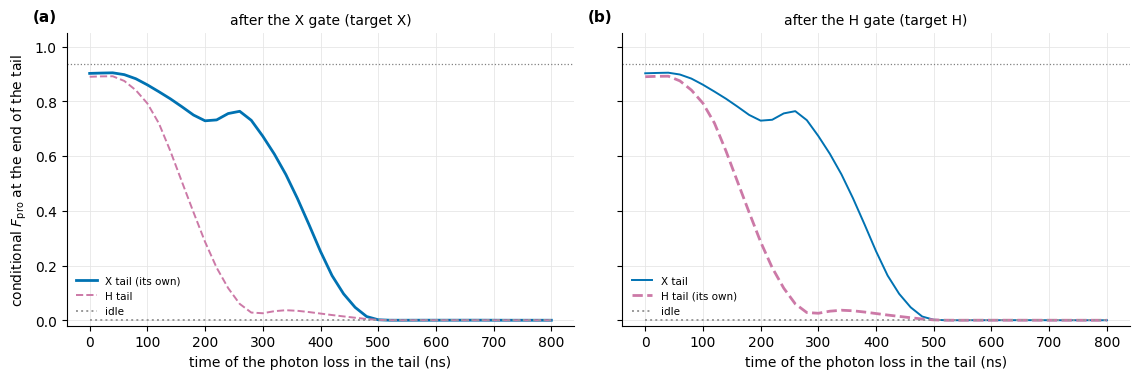

after the X gate, a loss at the start of the tail: X tail 0.902, H tail 0.890
after the H gate, a loss at the start of the tail: X tail 0.903, H tail 0.890


In [32]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.9), sharey=True)
for ax, gate in zip(axes, HG):
    for tail, ls in (("X tail", "-"), ("H tail", "--"), ("idle", ":")):
        d = HPROF[(HPROF.gate == gate) & (HPROF["tail"] == tail)]
        own = tail[0] == gate[-1]
        ax.plot(d.t_ns, d.f_branch, color=TCOL[tail], ls=ls, lw=2.0 if own else 1.4,
                label=tail + (" (its own)" if own else ""))
    ax.axhline(F_KITTEN, color="0.5", ls=":", lw=0.9)
    ax.set_title(f"after the {gate[-1]} gate (target {HG[gate]})", fontsize=10)
    ax.set_xlabel("time of the photon loss in the tail (ns)")
    ax.legend(fontsize=7.5, frameon=False, loc="lower left")
    tidy(ax)
axes[0].set_ylabel(r"conditional $F_{\rm pro}$ at the end of the tail")
axes[0].set_ylim(-0.02, 1.05)
for ax, k in zip(axes, "ab"):
    panel(ax, k)
fig.tight_layout()
fig.savefig("figures/fwm_tails_H_swap.png", dpi=150)
plt.show()
for gate in HG:
    f0 = {t: HPROF[(HPROF.gate == gate) & (HPROF["tail"] == t)].f_branch.iloc[0] for t in ("X tail", "H tail")}
    print(f"after the {gate[-1]} gate, a loss at the start of the tail: X tail {f0['X tail']:.3f}, "
          f"H tail {f0['H tail']:.3f}")

**Figure 11. Which photon losses each tail repairs, after each gate.** As Figure 10c, for each gate (panels) with the X
tail (blue), the H tail (purple, dashed) and an idle tail (grey, dotted). Thick: the tail trained after that gate.
*Symbols:* conditional $F_{\rm pro}$ = $F_{\rm pro}$ at the end of the tail of the branch with one photon lost at
time $t$, against that gate's target; dotted grey line: the kitten limit.

**What it shows.** **The repair does not depend on the gate in front.** Each tail's curve is the same after both gates
to within 0.001 (printed): a tail repairs a loss at a given time of the tail the same way, whatever gate came first.
An idle tail repairs nothing.

In [33]:
code_tab = HCODE[HCODE["tail"] != "none"].pivot(index="tail", columns="input", values=["F_vs_I", "F_best_Rz"])
code_tab = code_tab.reindex(["idle", "QEC teeth", "X tail", "H tail"])
code_tab.columns = [f"{inp}: {q}" for q, inp in code_tab.columns]
cols = [f"code words: {q}" for q in ("F_vs_I", "F_best_Rz")] + \
       [f"one-loss error words: {q}" for q in ("F_vs_I", "F_best_Rz")]
code_tab = code_tab[cols].rename(columns=lambda c: c.replace("F_vs_I", "F vs I").replace("F_best_Rz", "F, best Z rotation"))
display(code_tab.style.format("{:.4f}")
        .set_caption("Table 16. The tails with no gate in front (closed system)"))
print(f"kitten limit (best ideal repair of a clean error word): {F_KITTEN:.4f}")

,code words: F vs I,"code words: F, best Z rotation",one-loss error words: F vs I,"one-loss error words: F, best Z rotation"
tail,,,,
idle,0.9963,0.9966,0.0000,0.0000
QEC teeth,0.9940,0.9943,0.0183,0.0183
X tail,0.9998,0.9998,0.9041,0.9049
H tail,0.9999,0.9999,0.8916,0.8930


kitten limit (best ideal repair of a clean error word): 0.9353


**Table 16. The tails with no gate in front** (closed system, $n_c = 16$, readout traced). Code words: the code's
process inputs (as in every $F_{\rm pro}$ here), scored against doing nothing (the identity: I). One-loss error words: the same inputs with one photon removed ($\hat a\hat\rho\hat a^\dagger$, normalised), scored against I on the code, so a perfect repair scores the kitten limit.

*Symbols:* F vs I = process fidelity against the identity; F, best Z rotation = the same with the best logical Z
rotation $R_z(\theta)$ allowed for free.

Tail's job is to fix damage without changing the logical information. 

**What it shows.**

- **Both tails leave the code alone and repair clean error words,** like a passive corrector that does not know the
  gate: code words 0.9998 (X tail) and 0.9999 (H tail) against 0.996 for an idle wait and 0.994 for the QEC teeth;
  error words 0.904 and 0.892 against the kitten limit 0.935 (idle 0, teeth 0.02).
- **The X tail repairs a clean error word slightly better** (0.904 against 0.892), the same order as after either gate
  (Figure 11).
- **§6.6 gives the X tail at every length,** open and closed (Figure 9, Table 10).

## 7.5 What this says

- **The QEC tail works after the H gate,** and pays more there than after X: +1.19 % trained from a cold start,
  +1.30 % for the X tail moved over unchanged, against +0.32 % after X. The H gate is twice as long and loses more
  photons, so there is more to repair (ideal ceiling +3.09 % against +1.99 %), and the gain even survives dephasing
  and heating (+0.98 %).
- **The two tails differ in timing, not in kind.** Both are one comb 1 → comb 2 shot that repairs photon loss and
  nothing coherent. The H tail fires comb 1 early; the X tail fires late and so also covers the tail's own first
  360 ns (the H tail: 180 ns). The early shot is a worse local optimum: both cold starts found it, and the X tail beats it
  after both gates and by the H tail's own training cost.
- **Yes, the X tail corrects errors the same way after the H gate.** With no gate in front both tails repair clean
  error words (0.90 and 0.89) and leave the code words alone (0.9998), and the repair against the time of the loss is
  the same after both gates to 0.001. The tail is a gate-independent photon-loss corrector; the gate only sets how
  much it gets to repair. It inherits the same fragility to pump calibration.
- **Next:** start the H-gate training from the X tail (it is already better than both cold starts), and train one tail
  for both gates' outputs at once.

# 8. Repeated X gates

§6 scores one gate and one tail. A computation repeats gates. Here the EsT X gate runs up to 40 times, with the
0.8 μs tail placed in different ways:

| protocol | what runs | section |
|---|---|---|
| B1 | N gates back to back, then one tail | §8.2 |
| B2 | N (gate + tail) pairs | §8.3 |
| B3 | a tail after every k-th gate, k = 1–8, up to 40 gates | §8.4 |
| B3, retrained | the same, with the tail retrained for the state after k gates | §8.5 |

**What runs.** The EsT gate (labelled EsT-good in the run files) and, in B1 and B2, Ord, each with its own 0.8 μs tail
(better start, §6). Each tail was trained once, after one gate, and is reused unchanged (§8.5 retrains it). The target after N gates is
$X^N$: X for odd N, the identity for even N.

**References.** *Gates back to back:* the same N gates, no tail. *Memory:* the code just waiting, scored against the
identity, with the Kerr-corrected decoding of §8.1: plain idle; idle + one idle tail (B1; trained after one 1.1 μs
wait, `X_tail_idle_T08_t2`); idle with the QEC teeth held on, no tail. Memory is sampled so that it has
waited as long as the gated curve has run.

**The teeth are tuned to the pumps' Stark shift.** The pumps shift the lines they drive (§4.2). With the QEC
teeth on, the mean pump power is $\sum_k|\beta_k|^2 = 3.8\times10^{-4}$, and it moves every comb-1 line up by 204 kHz
and every comb-2 line down by 204 kHz. Comb 1 drives at only 57 kHz, so teeth set to the lines with no pump on mostly
miss them. An experiment tunes its tones with the pumps on, so here each tooth is moved by that mean shift
(`fwm_tail.teeth_stark_shifts`, `eta_from_teeth(stark_tuned=True)`); the teeth still beat against each other, so the
shift wobbles around its mean. Until 2026-11-09 the teeth sat at the no-pump lines, which keeps less: 0.613 against
0.654 for the tuned teeth after 38 μs (printed below Figure 13; rows `idle + Table II teeth, bare carriers` in
`tables/fwm_tail_repeat_kerr.csv`). The teeth of §2, §3 and §6 are left at the no-pump lines.

**How it is simulated** (`DGRAPE/fwm_repeat.py`). Forward only, $n_c = 24$, $n_r = 2$, the decay set (and closed),
the three process inputs. Gates run in the DGRAPE frame, tails in the frame that also rotates $|f\rangle$ (§4.1); after
each tail the state is rotated back, and each tail's carriers restart at its own $t = 0$. The readout is kept through
the gates. Checks (`validation/test_fwm_repeat.py`): N = 1 equals `fwm_tail.score` to $10^{-11}$; gate + zero tail +
gate equals one DGRAPE propagation (and fails without the frame hand-off); $n_r = 3$ moves no B2 curve by more than
0.1 %.

## 8.1 Kerr phase in memory, and the decoding that removes it

Waiting costs no energy, but the storage self-Kerr, $-\tfrac K2\hat n(\hat n-1)$ ($K/2\pi$ = 3.3 kHz), gives every
photon number its own phase. Uncorrected, it alone takes idle memory to $F_{\rm pro}$ = 0.16 after 20 waits. A
decoding that knows about it removes it for free (Gertler et al. 2021, Methods, Eq. 16).

**The phase.** A wait $t$ gives $|n\rangle$ the phase $\varphi_n = \tfrac K2 n(n-1)t$: 0, $3Kt$, $10Kt$ on $|1\rangle$,
$|3\rangle$, $|5\rangle$. It pulls $|0_L\rangle = (|1\rangle + |5\rangle)/\sqrt2$ apart, toward
$(|1\rangle - |5\rangle)/\sqrt2$ outside the code (0.23 rad per 1.1 μs wait), and turns $|1_L\rangle = |3\rangle$
against $|0_L\rangle$ (a logical Z). With no jumps $F_{\rm pro} = \big|(e^{-i\varphi_1} + e^{-i\varphi_5})/2 +
e^{-i\varphi_3}\big|^2/4$ = 0.993, 0.837, 0.481, 0.157 after 1, 5, 10, 20 waits: the uncorrected closed idle curve to
four digits. Gates and trained tails cancel their own phase (they were trained with $K$ in the model); plain waits do
not.

**The fix.** Two phases are free to remove: a global one, and one linear in $n$, $e^{-i\delta\hat n t}$, which is the
cavity seen in a frame that turns $\delta$ faster (a software phase update of the decoding pulse). The line through
$n = 1$ and $n = 5$ has slope $2.5Kt$; it misses the parabola only at $n = 3$:

| photon number $n$ | $1$ | $3$ | $5$ |
|---|---|---|---|
| part of | $0_L$ | $1_L$ | $0_L$ |
| Kerr phase $\varphi_n$ | $0$ | $3Kt$ | $10Kt$ |
| straight line $2.5Kt\,(n - 1)$ | $0$ | $5Kt$ | $10Kt$ |
| left over | $0$ | $-2Kt$ | $0$ |

What is left sits on $|3\rangle$, the whole of $|1_L\rangle$: exactly a logical Z, also free. So, on the code levels,

$$
C(t) = e^{-i\frac K2\hat n(\hat n-1)t}
= \underbrace{e^{-i\,2.5K\hat n t}}_{\text{cavity frame shift}}\;
\underbrace{\big(|0_L\rangle\langle 0_L| + e^{\,i\,2Kt}|1_L\rangle\langle 1_L|\big)}_{\text{logical Z by }2Kt} .
$$

`fwm_repeat.kerr_decode` applies $C(t)$ just before scoring (rows `decode = "kerr"`); open idle then decays only
through photon loss.

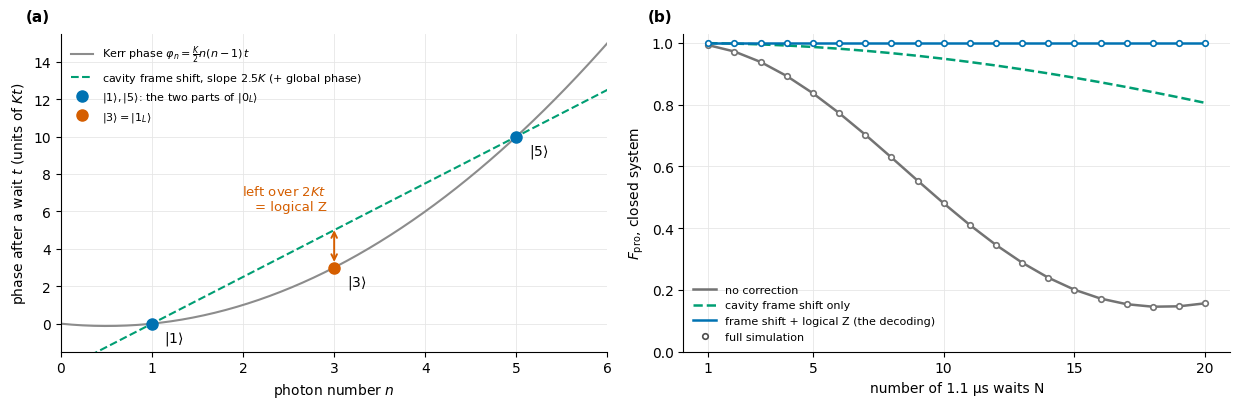

per 1.1 μs wait: |0_L> split 10Kt = 0.228 rad, logical Z 2Kt = 0.046 rad; frame shift 2.5K/2π = 8.25 kHz
closed F_pro after N = 1, 5, 10, 20 waits:
  no correction                           0.9930  0.8372  0.4808  0.1568
  cavity frame shift only                 0.9995  0.9871  0.9489  0.8060
  frame shift + logical Z (the decoding)  1.0000  1.0000  1.0000  1.0000


In [34]:
# Section 8.1: the idle Kerr phase on the code levels, and what the decoding removes (closed system, no jumps).
# Lines: the formula of the text; dots: the full simulation (tables/fwm_tail_repeat_kerr.csv, also read in 8.2).
T_WAIT = 1.1                                              # us, one wait = the gate's length
kerr_phase = lambda n: n * (n - 1) / 2                    # noqa: E731  Kerr phase in units of K t
frame_line = lambda n: 2.5 * (n - 1)                      # noqa: E731  frame shift through n = 1 and n = 5


def f_closed(th1, th3, th5):
    """F_pro of the idle code with phases th_n left on |n> (no jumps)."""
    return np.abs((np.exp(-1j * th1) + np.exp(-1j * th5)) / 2 + np.exp(-1j * th3)) ** 2 / 4


fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))
ax = axes[0]
n = np.linspace(0, 6, 200)
ax.plot(n, kerr_phase(n), color="0.55", lw=1.5, label=r"Kerr phase $\varphi_n = \frac{K}{2}n(n-1)\,t$")
ax.plot(n, frame_line(n), color=OKABE[2], lw=1.5, ls="--", label=r"cavity frame shift, slope $2.5K$ (+ global phase)")
ax.plot([1, 5], [kerr_phase(1), kerr_phase(5)], "o", color=OKABE[0], ms=8, zorder=3,
        label=r"$|1\rangle, |5\rangle$: the two parts of $|0_L\rangle$")
ax.plot([3], [kerr_phase(3)], "o", color=OKABE[4], ms=8, zorder=3, label=r"$|3\rangle = |1_L\rangle$")
for k in (1, 3, 5):
    ax.annotate(fr"$|{k}\rangle$", (k, kerr_phase(k)), xytext=(9, -13), textcoords="offset points", fontsize=10)
ax.annotate("", xy=(3, kerr_phase(3)), xytext=(3, frame_line(3)),
            arrowprops=dict(arrowstyle="<->", color=OKABE[4], lw=1.4, shrinkA=0, shrinkB=4))
ax.text(2.92, 6.7, r"left over $2Kt$" "\n" r"= logical Z", color=OKABE[4], fontsize=9.5, ha="right", va="center")
ax.set_xlim(0, 6)
ax.set_ylim(-1.5, 15.5)
ax.set_xlabel("photon number $n$")
ax.set_ylabel(r"phase after a wait $t$ (units of $Kt$)")
ax.legend(fontsize=8, frameon=False, loc="upper left")

ax = axes[1]
N = np.arange(1, 21)
Kt = dev.K_a * N * T_WAIT
th = {k: kerr_phase(k) * Kt for k in (1, 3, 5)}                    # after the wait
sh = {k: th[k] - 2.5 * k * Kt for k in (1, 3, 5)}                  # after the cavity frame shift
curves = [("no correction", f_closed(th[1], th[3], th[5]), "0.45", "-"),
          ("cavity frame shift only", f_closed(sh[1], sh[3], sh[5]), OKABE[2], "--"),
          ("frame shift + logical Z (the decoding)", f_closed(sh[1], sh[3] + 2 * Kt, sh[5]), OKABE[0], "-")]
for lab, F, col, ls in curves:
    ax.plot(N, F, color=col, lw=1.8, ls=ls, label=lab)
sim = pd.read_csv("tables/fwm_tail_repeat_kerr.csv")
sim = sim[(sim.protocol == "B1") & (sim.label == "idle") & (sim.system == "closed") & (sim["tail"] == "none")]
for dec, col in (("none", "0.45"), ("kerr", OKABE[0])):
    d = sim[sim.decode == dec].sort_values("N")
    ax.plot(d.N, d.F_pro, "o", color=col, ms=4, mfc="white", mew=1.2)
ax.plot([], [], "o", color="0.3", ms=4, mfc="white", mew=1.2, label="full simulation")
ax.set_xlabel("number of 1.1 μs waits N")
ax.set_ylabel(r"$F_{\rm pro}$, closed system")
ax.set_xticks([1, 5, 10, 15, 20])
ax.set_ylim(0, 1.03)
ax.legend(fontsize=8, frameon=False, loc="lower left")
for ax, k in zip(axes, "ab"):
    tidy(ax)
    panel(ax, k)
fig.tight_layout()
fig.savefig("figures/fwm_tails_kerr_decoding.png", dpi=150)
plt.show()
print(f"per 1.1 μs wait: |0_L> split 10Kt = {10 * dev.K_a * T_WAIT:.3f} rad, logical Z 2Kt = {2 * dev.K_a * T_WAIT:.3f} rad; "
      f"frame shift 2.5K/2π = {2.5 * mhz(dev.K_a) * 1e3:.2f} kHz")
print("closed F_pro after N = 1, 5, 10, 20 waits:")
for lab, F, _, _ in curves:
    print(f"  {lab:40s}" + "  ".join(f"{F[k - 1]:.4f}" for k in (1, 5, 10, 20)))

**Figure 12. The idle Kerr phase on the code levels, and what the decoding removes.** (a) Phase after a wait $t$: the
Kerr parabola (grey) and the cavity frame shift through $|1\rangle$ and $|5\rangle$ (green, dashed); the arrow is the
$2Kt$ left on $|3\rangle$. (b) Closed $F_{\rm pro}$ of the idle code after N waits of 1.1 μs. Lines: the formula;
dots: the full simulation.
*Symbols:* $\varphi_n$ = phase of $|n\rangle$; $K/2\pi$ = 3.3 kHz; blue = the parts of $|0_L\rangle$, vermilion =
$|1_L\rangle = |3\rangle$.

**What it shows.** The frame shift does most of the repair (20 waits: 0.157 → 0.806, leaving $\cos^2(Kt)$); with the
logical Z, closed idle stays at 1 for every N, and the simulation matches the formula.

**Where it does not apply.**

- **Only waiting may happen between encoding and decoding.** So it is applied to the memory references only (N waits
  without the idle tail, N − 1 with it, since that tail cancels the last wait and itself). It cannot fix gate + idle
  pairs, whose gates move the phase around.
- **For the teeth it removes the Kerr phase only.** Their largest side effect is a leak: one tooth of each comb
  together pumps $|n, g, 0\rangle \to |n+1, g, 1\rangle$ (the middle state is off by $\chi_{gf}$, but the two tones
  together miss by only $K$). The Stark tuning moves the comb-1 and comb-2 teeth in opposite directions, so the two
  tones still miss by about $K$ and the leak stays, smaller (14 % pumped after 22 μs closed, 43 % untuned). Closed it
  builds up coherently (Figure 13b); with $\kappa_r$ on it is a weak heating: with readout decay as the only loss the
  teeth keep 0.948 after 22 μs (checked at $n_c = 12$).
- **A loss mid-wait changes the phase to undo** ($\hat a f(\hat n) = f(\hat n + 1)\hat a$), a small error after a tail.

## 8.2 N gates, then one tail (B1)

EsT-good  tail X_tail_estg_T08_t2   F_pro after one gate + tail, n_c 24: 0.97027
Ord       tail X_tail_ord_T08_t2    F_pro after one gate + tail, n_c 24: 0.95849
idle      tail X_tail_idle_T08_t2   F_pro after one gate + tail, n_c 24: 0.98128
QEC teeth after 22.0 us (B1 sampling), Kerr decoded: Stark-tuned 0.8060, no-pump lines 0.7410
QEC teeth after 38.0 us (B2 sampling), Kerr decoded: Stark-tuned 0.6538, no-pump lines 0.6127


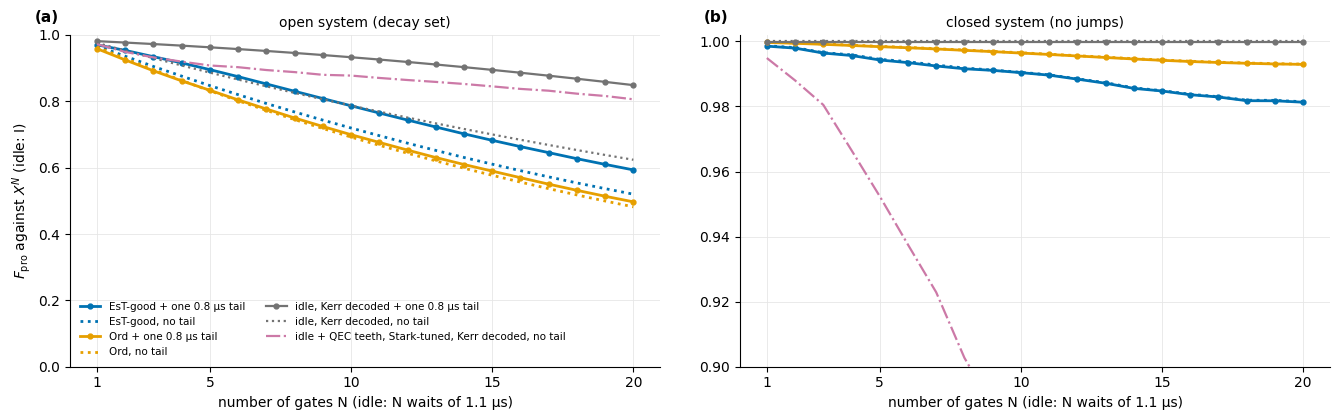

In [35]:
# Section 8: repeated X gates (DGRAPE/fwm_repeat.py, run by DGRAPE/fwm_repeat_run.py; forward only, n_c 24, n_r 2).
# Cached: delete the two CSVs and run
#   python DGRAPE/fwm_repeat_run.py --tails EsT-good=X_tail_estg_T08_t2 Ord=X_tail_ord_T08_t2 \
#       EsT-mid=X_tail_est_T08_z idle=X_tail_idle_T08_t2 --out-dir tables          (~4 h on 16 cores)
# (the CSVs also hold EsT-mid rows, an earlier gate no longer shown)
# Memory references with the Kerr-corrected decoding (fwm_repeat.kerr_decode), rows decode = "kerr": idle with and
# without its tail, the QEC teeth every 1.1 us (B1), and idle and the teeth every 1.9 us (B2). The teeth are
# Stark-tuned (fwm_tail.teeth_stark_shifts); TEETH_BARE = the same at the no-pump lines, as run until 2026-11-09:
#   python DGRAPE/fwm_repeat_run.py --tails idle=X_tail_idle_T08_t2 --kerr-decode --n-jobs 8 --out-dir tables  (~15 min)
REP1 = pd.read_csv("tables/fwm_tail_repeat_B1.csv")
REP2 = pd.read_csv("tables/fwm_tail_repeat_B2.csv")
REPK = pd.read_csv("tables/fwm_tail_repeat_kerr.csv")
KB1, KB2 = (REPK[(REPK.decode == "kerr") & (REPK.protocol == pr)] for pr in ("B1", "B2"))
TEETH = "idle + Table II teeth"                          # Stark-tuned; CSV labels, shown as QEC teeth
TEETH_BARE = "idle + Table II teeth, bare carriers"      # untuned, for the record only
REP_COL = {"EsT-good": GCOL["EsT"], "Ord": GCOL["Ord"], "idle": "0.45", TEETH: OKABE[3]}
REP_LW = {"EsT-good": 2.0, "Ord": 2.0, "idle": 1.6, TEETH: 1.6}
TEETH_NAME = "idle + QEC teeth, Stark-tuned, Kerr decoded"
N_SHOW = [1, 2, 5, 10, 20]


def rep(df, label, system="open", tail=None, n_r=2):
    q = (df.label == label) & (df.system == system) & (df.n_r == n_r)
    if tail is not None:
        q &= df["tail"] == tail
    return df[q].sort_values("N")


for lab in ("EsT-good", "Ord", "idle"):                      # N = 1 is the single-gate result (training)
    d = rep(REP1, lab, tail="tail")
    print(f"{lab:9s} tail {d.tag.iloc[0]:20s} F_pro after one gate + tail, n_c 24: {d.F_pro.iloc[0]:.5f}")
for pr, kb in (("B1", KB1), ("B2", KB2)):                    # the Stark tuning of the teeth (§8 intro), open
    t, b = (rep(kb, lab).set_index("N") for lab in (TEETH, TEETH_BARE))
    N = t.index.max()
    print(f"QEC teeth after {t.time_us[N]:.1f} us ({pr} sampling), Kerr decoded: Stark-tuned {t.F_pro[N]:.4f}, "
          f"no-pump lines {b.F_pro[N]:.4f}")


fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.3))
for ax, system in zip(axes, ("open", "closed")):
    for lab in ("EsT-good", "Ord", "idle"):
        for tail, ls in (("tail", "-"), ("none", ":")):
            d = rep(KB1 if lab == "idle" else REP1, lab, system, tail)          # idle: Kerr-corrected decoding
            name = "idle, Kerr decoded" if lab == "idle" else lab
            ax.plot(d.N, d.F_pro, color=REP_COL[lab], lw=REP_LW[lab], ls=ls, marker="o" if tail == "tail" else None,
                    ms=3.5, label=name + (" + one 0.8 μs tail" if tail == "tail" else ", no tail"))
    d = rep(KB1, TEETH, system)                                              # the QEC teeth held on, no tail
    ax.plot(d.N, d.F_pro, color=REP_COL[TEETH], lw=REP_LW[TEETH], ls="-.", label=TEETH_NAME + ", no tail")
    ax.set_xlabel("number of gates N (idle: N waits of 1.1 μs)")
    ax.set_xticks([1, 5, 10, 15, 20])
    ax.set_title("open system (decay set)" if system == "open" else "closed system (no jumps)", fontsize=10)
    tidy(ax)
axes[0].set_ylabel(r"$F_{\rm pro}$ against $X^N$ (idle: I)")
axes[0].set_ylim(0, 1)
axes[1].set_ylim(0.9, 1.002)                                                # the teeth leave below 0.9 (closed: a Raman leak)
axes[0].legend(fontsize=7.5, frameon=False, ncol=2, loc="lower left")
for ax, k in zip(axes, "ab"):
    panel(ax, k)
fig.tight_layout()
fig.savefig("figures/fwm_tails_repeat_B1.png", dpi=150)
plt.show()

**Figure 13. N gates, then one 0.8 μs tail (B1), against memory.** Solid with dots: with the tail; dotted: the same
N gates (or waits) without it. Memory, Kerr decoded (§8.1): grey = idle, with and without the idle tail; purple,
dash-dot = idle with the QEC teeth held on, Stark-tuned.
(a) Open system, decay set; (b) closed, from 0.9 to 1 (the closed
teeth leave the panel after N = 8: 0.903 at 8.8 μs, 0.804 at 22 μs, the leak of §8.1).
*Symbols:* $F_{\rm pro}$ against $X^N$ (memory: identity); N = number of gates or 1.1 μs waits.

In [36]:
b1_rows = []
for lab, df in (("EsT-good", REP1), ("Ord", REP1), ("idle, Kerr decoded", KB1),
                ("idle, no Kerr correction", REP1)):
    q = lab.split(",")[0]
    none, tl = rep(df, q, tail="none").set_index("N").F_pro, rep(df, q, tail="tail").set_index("N").F_pro
    nc, tc = (rep(df, q, "closed", t).set_index("N").F_pro for t in ("none", "tail"))
    for N in N_SHOW:
        b1_rows.append({"gate": lab, "N": N, "no tail": none[N], "+ one tail": tl[N], "gain of the tail": tl[N] - none[N],
                        "gain, closed": tc[N] - nc[N]})
teeth = rep(KB1, TEETH).set_index("N").F_pro
for N in N_SHOW:                                                         # the teeth: no tail, so only F_pro
    b1_rows.append({"gate": "idle + QEC teeth (Stark-tuned), Kerr decoded", "N": N, "no tail": teeth[N]})
B1TAB = pd.DataFrame(b1_rows)
display(B1TAB.style.hide(axis="index")
        .format({"no tail": "{:.4f}", "+ one tail": "{:.4f}", "gain of the tail": "{:+.2%}", "gain, closed": "{:+.2%}"},
                na_rep="")
        .set_caption("Table 17. N gates, then one tail (B1)"))

gate,N,no tail,+ one tail,gain of the tail,"gain, closed"
EsT-good,1,0.9671,0.9703,+0.32%,-0.01%
EsT-good,2,0.9359,0.9533,+1.74%,-0.02%
EsT-good,5,0.8472,0.8954,+4.82%,-0.02%
EsT-good,10,0.7195,0.7864,+6.69%,-0.01%
EsT-good,20,0.5200,0.5932,+7.32%,-0.02%
Ord,1,0.9638,0.9585,-0.53%,-0.01%
Ord,2,0.9289,0.9246,-0.43%,-0.01%
Ord,5,0.8316,0.8331,+0.15%,-0.01%
Ord,10,0.6922,0.6994,+0.71%,-0.01%
Ord,20,0.4818,0.4969,+1.51%,-0.01%


**Table 17. N gates, then one tail (B1),** at selected N.
*Symbols:* gain of the tail = $F_{\rm pro}$(+ one tail) − $F_{\rm pro}$(no tail), open system; gain, closed = the same
with no jumps.

**What it shows.** One tail at the end helps more the more gates come before it.

- **After the EsT gate the gain grows with N:** +0.32 % (N = 1), +1.7 % (2), +4.8 % (5), +7.3 % (20). Closed it stays
  at −0.01 to −0.02 %, so all of it is repair: more gates leave more weight in repairable single-loss branches, although
  the tail was trained after one gate.
- **After Ord the tail** Not much help at all. 
- **Kerr-decoded memory beats every gated curve without a QEC tail:** closed it stays at 1.0000; open it falls from 0.976
  to 0.624 after 22 μs, the photon-loss rate $\bar n/T_{1a}$ = 2.1 % per μs. Each gate costs about 0.9 % on top (EsT
  back to back: 0.967 at N = 1, 0.520 at N = 20). Undecoded idle fell to 0.13 (last rows), all of it Kerr phase.
- **Kerr-decoded memory + QEC tail repairs memory far better than any gate:** +22.5 % after 20 waits (0.849 against 0.624), three times
  the gain after 20 EsT gates. A loss during a plain wait leaves a clean single-loss state.
- **The QEC teeth (Stark-tuned) beat plain idle from 3.3 μs on** (0.806 against 0.624 at 22 μs), but one trained
  tail at the end does better (0.849): at the QEC teeth's strength a repair takes microseconds, so 8 % of the population
  still waits in error states at 22 μs (17 % untuned). Closed the teeth fall to 0.804 (14 % pumped to
  $|n+1, g, 1\rangle$, §8.1; untuned 0.540 and 43 %), and it is mostly not a phase: the best phase correction gains
  3.2 % (checked at $n_c = 12$).

## 8.3 N (gate + tail) pairs (B2)

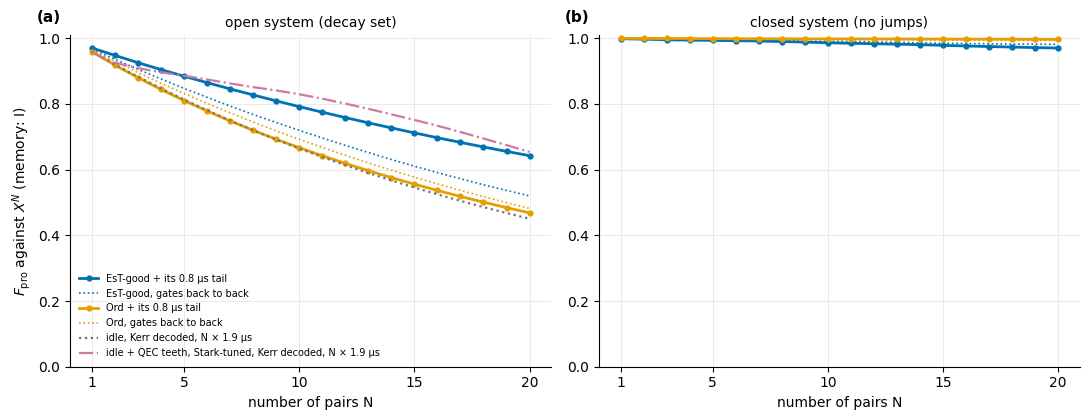

In [37]:
def fit_p(d):
    """F = A p^N, least squares on log F over N = 1..20. Returns A, p."""
    k, c = np.polyfit(d.N, np.log(d.F_pro), 1)
    return np.exp(c), np.exp(k)


fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
for lab in ("EsT-good", "Ord"):
    for ax, system in zip(axes, ("open", "closed")):
        d = rep(REP2, lab, system)                                       # gate + its trained tail
        ax.plot(d.N, d.F_pro, color=REP_COL[lab], lw=REP_LW[lab], marker="o", ms=3.5, label=f"{lab} + its 0.8 μs tail")
        d = rep(REP1, lab, system, "none")                               # gates back to back, no tails (B1)
        ax.plot(d.N, d.F_pro, color=REP_COL[lab], lw=1.2, ls=":", label=f"{lab}, gates back to back")
for lab, ls, name in (("idle", ":", "idle, Kerr decoded"), (TEETH, "-.", TEETH_NAME)):   # memory, same time, (a) only
    d = rep(KB2, lab)
    axes[0].plot(d.N, d.F_pro, color=REP_COL[lab], lw=REP_LW[lab], ls=ls, label=f"{name}, N × 1.9 μs")
for ax, k, tt in zip(axes, "ab", ("open system (decay set)", "closed system (no jumps)")):
    ax.set_xlabel("number of pairs N")
    ax.set_title(tt, fontsize=10)
    ax.set_ylim(0, 1.01)
    ax.set_xticks([1, 5, 10, 15, 20])
    tidy(ax)
    panel(ax, k)
axes[0].set_ylabel(r"$F_{\rm pro}$ against $X^N$ (memory: I)")
axes[0].legend(fontsize=7, frameon=False, loc="lower left")
fig.tight_layout()
fig.savefig("figures/fwm_tails_repeat_B2.png", dpi=150)
plt.show()

**Figure 14. N (gate + 0.8 μs tail) pairs (B2), against memory.** Solid with dots: gate + its trained tail; thin
dotted: the same N gates back to back. Panel (a) also shows memory for as long as N pairs take (N × 1.9 μs), Kerr
decoded: grey dotted = idle, purple dash-dot = QEC teeth, Stark-tuned.
(a) Open system, decay set; (b) closed, gates only.
*Symbols:* $F_{\rm pro}$ against $X^N$ (memory: identity); one pair = 1.9 μs (gate 1.1 + tail 0.8).

In [38]:
b2_rows = []
T_PAIR = {lab: rep(REP2, lab).time_us.iloc[0] for lab in REP2.label.unique()}
for lab in ("EsT-good", "Ord"):
    d, dc = rep(REP2, lab).set_index("N"), rep(REP2, lab, "closed").set_index("N")
    row = {"pairs": lab, **{f"N = {N}": d.F_pro[N] for N in N_SHOW}}
    A, p = fit_p(d.reset_index())
    row.update({"fit A": A, "fit p (per pair)": p, "loss per μs": 1 - p ** (1 / T_PAIR[lab]),
                "closed, N = 20": dc.F_pro[20]})
    r3 = rep(REP2, lab, n_r=3).set_index("N").F_pro
    row["n_r 3 − 2, max"] = (r3 - d.F_pro).abs().max()
    b2_rows.append(row)
for lab in ("EsT-good", "Ord"):                                         # gates back to back (B1, no tail)
    d = rep(REP1, lab, tail="none").set_index("N")
    A, p = fit_p(d.reset_index())
    b2_rows.append({"pairs": f"{lab}, gates back to back", **{f"N = {N}": d.F_pro[N] for N in N_SHOW},
                    "fit A": A, "fit p (per pair)": p, "loss per μs": 1 - p ** (1 / 1.1),
                    "closed, N = 20": rep(REP1, lab, "closed", "none").set_index("N").F_pro[20]})
for lab, name in (("idle", "idle, Kerr decoded"), (TEETH, "idle + QEC teeth (Stark-tuned), Kerr decoded")):  # memory, N × 1.9 μs
    d = rep(KB2, lab).set_index("N")
    A, p = fit_p(d.reset_index())
    b2_rows.append({"pairs": f"{name} (N × 1.9 μs)", **{f"N = {N}": d.F_pro[N] for N in N_SHOW},
                    "fit A": A, "fit p (per pair)": p, "loss per μs": 1 - p ** (1 / d.time_us.iloc[0]),
                    "closed, N = 20": rep(KB2, lab, "closed").set_index("N").F_pro[20]})
B2TAB = pd.DataFrame(b2_rows)
fmt = {c: "{:.4f}" for c in B2TAB.columns if c.startswith("N =") or c in ("fit A", "fit p (per pair)", "closed, N = 20")}
display(B2TAB.style.hide(axis="index")
        .format({**fmt, "loss per μs": "{:.2%}", "n_r 3 − 2, max": "{:.0e}"}, na_rep="")
        .set_caption("Table 18. N (gate + tail) pairs (B2)"))

pairs,N = 1,N = 2,N = 5,N = 10,N = 20,fit A,fit p (per pair),loss per μs,"closed, N = 20","n_r 3 − 2, max"
EsT-good,0.9703,0.9476,0.8842,0.7917,0.6425,0.9860,0.9786,1.13%,0.9701,1e-03
Ord,0.9585,0.9178,0.8102,0.6667,0.4684,0.9791,0.9631,1.96%,0.9967,2e-04
"EsT-good, gates back to back",0.9671,0.9359,0.8472,0.7195,0.5200,0.9981,0.9678,2.93%,0.9815,
"Ord, gates back to back",0.9638,0.9289,0.8316,0.6922,0.4818,0.9982,0.9642,3.26%,0.9930,
"idle, Kerr decoded (N × 1.9 μs)",0.9590,0.9200,0.8129,0.6641,0.4505,0.9921,0.9610,2.07%,1.0000,
"idle + QEC teeth (Stark-tuned), Kerr decoded (N × 1.9 μs)",0.9562,0.9255,0.8857,0.8294,0.6538,0.9779,0.9818,0.96%,0.8955,


**Table 18. N (gate + tail) pairs (B2),** open system at selected N, with a fit.
*Symbols:* fit $F \approx A\,p^N$ (least squares on $\log F$, N = 1–20); $p$ = fidelity kept per pair (per gate for
"back to back", per 1.9 μs for memory); loss per μs = $1 - p^{1/T}$; closed, N = 20 = no jumps; $n_r$ 3 − 2, max: the
largest change in F_pro when the readout in truncated at 2 levels vs 3 levels, across different truncations; memory rows Kerr decoded, N × 1.9 μs.

**What it shows.** Repeated tails help the EsT gate a lot. EsT pairs keep the qubit better than plain memory in the same
time; memory with the Stark-tuned QEC teeth does better still, from about 9 to 41 μs.

- **EsT pairs are the best gated curve at every N:** 0.642 after 20 pairs against 0.520 for 20 gates back to back (+12 %),
  although the pairs take 38 μs instead of 22. Per pair $p$ = 0.979, against 0.968 per bare gate.
- **Ord pairs** end slightly below Ord back to back (0.468 against 0.482): for a fixed number of gates Ord gains nothing.
- **Against memory in the same time, the tuned teeth lead from N = 5 (9.5 μs) on:** by up to 4.3 % at N = 12
  (22.8 μs; 0.801 against 0.759) and by 1.1 % at 38 μs (teeth 0.654, EsT pairs 0.642, plain idle 0.450). The fit
  gives the teeth 0.96 % per μs against 1.13 % for the EsT pairs, but the teeth curve bends down: the gap closes, and in
  §8.4 (Figure 15b) the EsT pairs pass the teeth at about 41 μs (0.442 against 0.354 at 76 μs). The teeth keep about
  91 % of the population on the code levels $|1\rangle, |3\rangle, |5\rangle$ the whole time ($n_c = 16$), so the
  extra loss is not leakage; it is in the amplitudes and phases the repairs leave behind. Untuned, the teeth lost to the
  EsT pairs at every N (0.613 at 38 μs).
- **The tail also cancels the Kerr phase:** with the tail switched off (gate + idle, in the CSV) the pairs fall to
  0.775 after 20 even closed (0.970 with the tail).
- **Transmon excitation builds up:** after 20 EsT pairs $P_e$ ≈ 0.12 and $P_f$ ≈ 0.03; the tails remove only part of it.

## 8.4 One tail every k gates (B3)

B1 shows a tail repairs more the more gates come before it; B2 puts one after every gate. In between: run k gates,
then one tail, and repeat. Is it better to correct less often?

**What runs.** The EsT gate and its 0.8 μs tail (reused unchanged), k = 1 to 8, up to 40 gates, open (decay set) and
closed, $n_c = 24$, `fwm_repeat.every_k`. After every gate the state is scored two ways: **ends with a tail** (the
scheduled tail if k divides N, otherwise one extra tail on a copy, so every k is compared after the same final step)
and **as is**. k = 1 is B2; the first k gates are B1. References: the same 40 gates back to back, and Kerr-decoded
idle and QEC-teeth memory out to 76 μs (the time 40 gates + 40 tails take).

  k = 1 vs B2 (open)                     max |dF| = 0.0e+00
  first block vs B1 + tail (open)        max |dF| = 0.0e+00
  back to back vs B1 (open)              max |dF| = 0.0e+00
  k = 1 vs B2 (closed)                   max |dF| = 0.0e+00
  first block vs B1 + tail (closed)      max |dF| = 0.0e+00
  back to back vs B1 (closed)            max |dF| = 0.0e+00
  idle vs Kerr table (open)              max |dF| = 1.1e-16
  teeth vs Kerr table (open)             max |dF| = 0.0e+00
largest population at storage Fock >= 20 (truncation check): 3.0e-02


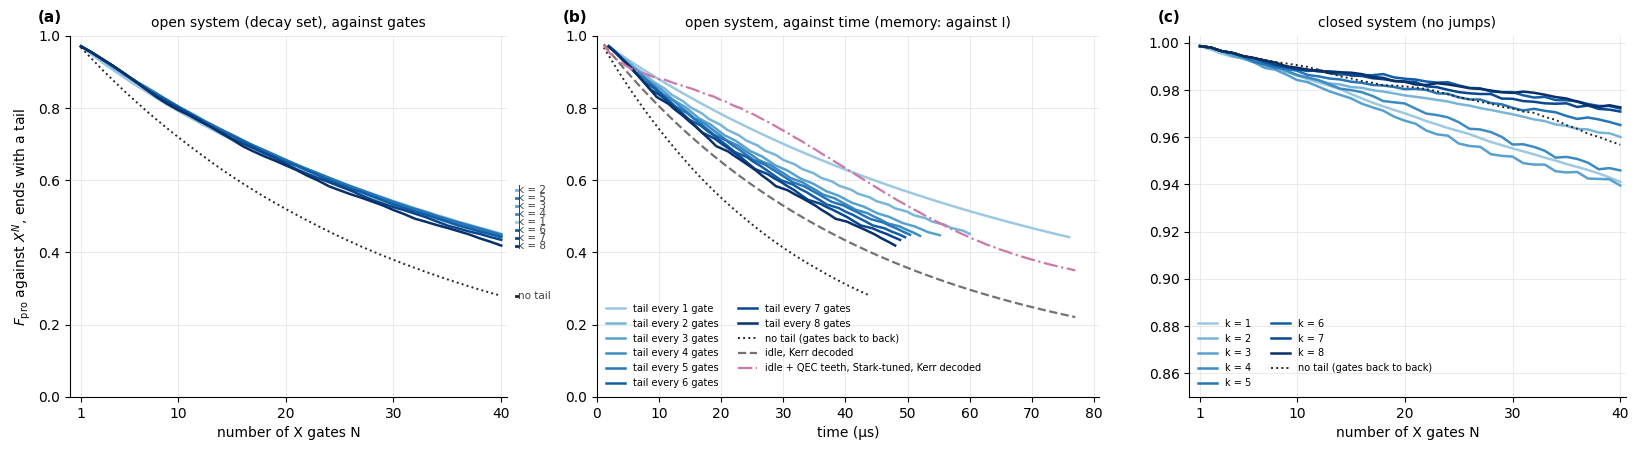

In [39]:
# Section 8.4: a tail after every k-th gate (B3; DGRAPE/fwm_repeat.every_k, forward only, n_c 24, n_r 2).
# Cached: delete the CSV and run (writes one part per job to <out-dir>/B3_parts, then merges them)
#   OPENBLAS_NUM_THREADS=1 python DGRAPE/fwm_repeat_run.py --tails EsT-good=X_tail_estg_T08_t2 \
#       --every-k 1 2 3 4 5 6 7 8 --n-max 40 --n-jobs 20 --out-dir ~/fwm_runs/repeat_B3     (3.5 h with 20 jobs on the PC)
# then copy ~/fwm_runs/repeat_B3/fwm_tail_repeat_B3.csv to tables/.
REP3 = pd.read_csv("tables/fwm_tail_repeat_B3.csv")
K_LIST = sorted(int(k) for k in REP3.k.dropna().unique())
B2B = "EsT-good, back to back"
# one hue, light to dark with k (an ordered quantity): the EsT blue family
K_COL = {k: plt.cm.Blues(0.38 + 0.62 * i / (len(K_LIST) - 1)) for i, k in enumerate(K_LIST)}


def b3(k, system="open", end="tail"):
    q = (REP3.protocol == "B3") & (REP3.label == "EsT-good") & (REP3.k == k) & (REP3.system == system)
    return REP3[q & (REP3.end == end)].sort_values("N")


def b2b(system="open"):
    return REP3[(REP3.label == B2B) & (REP3.system == system)].sort_values("N")


def mem3(label):
    return REP3[(REP3.protocol == "memory") & (REP3.label == label) & (REP3.decode == "kerr")].sort_values("N")


def label_ends(ax, items, x, gap):
    """Direct labels at x for (y, text, color) items, pushed apart to at least `gap` (data units)."""
    items = sorted(items)
    ys = [y for y, _, _ in items]
    for i in range(1, len(ys)):
        ys[i] = max(ys[i], ys[i - 1] + gap)
    for y, (_, text, col) in zip(ys, items):
        ax.text(x, y, text, color="0.25", fontsize=7.5, va="center")
        ax.plot([x - 0.25, x - 0.05], [y, y], color=col, lw=2, clip_on=False)


# Checks against the B1/B2 tables (N <= 20): k = 1 is B2, the first k gates + tail of every k is B1 with its tail,
# gates back to back are B1 without; memory is B1 of the Kerr table (sampled every 1.1 us, both).
chk = {}
for system in ("open", "closed"):
    chk[f"k = 1 vs B2 ({system})"] = (b3(1, system).set_index("N").F_pro
                                      - rep(REP2, "EsT-good", system).set_index("N").F_pro).abs().max()
    b1t = rep(REP1, "EsT-good", system, "tail").set_index("N").F_pro
    chk[f"first block vs B1 + tail ({system})"] = max(abs(b3(k, system).set_index("N").F_pro[N] - b1t[N])
                                                      for k in K_LIST for N in range(1, min(k, b1t.index.max()) + 1))
    chk[f"back to back vs B1 ({system})"] = (b2b(system).set_index("N").F_pro
                                             - rep(REP1, "EsT-good", system, "none").set_index("N").F_pro).abs().max()
chk["idle vs Kerr table (open)"] = (mem3("idle").set_index("N").F_pro
                                    - rep(KB1, "idle", tail="none").set_index("N").F_pro).abs().max()
chk["teeth vs Kerr table (open)"] = (mem3(TEETH).set_index("N").F_pro - rep(KB1, TEETH).set_index("N").F_pro).abs().max()
for key, v in chk.items():
    print(f"  {key:38s} max |dF| = {v:.1e}")
print(f"largest population at storage Fock >= {int(REP3.n_c.iloc[0]) - 4} (truncation check): "
      f"{REP3[REP3.protocol == 'B3'].P_top.max():.1e}")

fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.6), gridspec_kw={"width_ratios": [1, 1.15, 1]})
N_MAX3 = int(REP3[REP3.protocol == "B3"].N.max())
for ax, system in ((axes[0], "open"), (axes[2], "closed")):
    for k in K_LIST:
        d = b3(k, system)
        ax.plot(d.N, d.F_pro, color=K_COL[k], lw=1.8, label=f"k = {k}")
    d = b2b(system)
    ax.plot(d.N, d.F_pro, color="0.15", lw=1.4, ls=":", label="no tail (gates back to back)")
    ax.set_xlabel("number of X gates N")
    ax.set_xlim(0, N_MAX3 + 0.5)
    ax.set_xticks([1, 10, 20, 30, 40][: 1 + N_MAX3 // 10])
label_ends(axes[0], [(b3(k).F_pro.iloc[-1], f"k = {k}", K_COL[k]) for k in K_LIST]
           + [(b2b().F_pro.iloc[-1], "no tail", "0.15")], N_MAX3 + 1.6, 0.022)
axes[0].set_ylabel(r"$F_{\rm pro}$ against $X^N$, ends with a tail")
axes[0].set_ylim(0, 1)
axes[0].set_title("open system (decay set), against gates", fontsize=10)

ax = axes[1]
for k in K_LIST:
    d = b3(k)
    ax.plot(d.time_us, d.F_pro, color=K_COL[k], lw=1.8, label=f"tail every {k} gate" + ("s" if k > 1 else ""))
d = b2b()
ax.plot(d.time_us, d.F_pro, color="0.15", lw=1.4, ls=":", label="no tail (gates back to back)")
d = mem3("idle")
ax.plot(d.time_us, d.F_pro, color=REP_COL["idle"], lw=REP_LW["idle"], ls="--", label="idle, Kerr decoded")
d = mem3(TEETH)
ax.plot(d.time_us, d.F_pro, color=REP_COL[TEETH], lw=REP_LW[TEETH], ls="-.", label=TEETH_NAME)
ax.set_xlabel("time (μs)")
ax.set_ylim(0, 1)
ax.set_xlim(0, None)
ax.set_title("open system, against time (memory: against I)", fontsize=10)
ax.legend(fontsize=7, frameon=False, loc="lower left", ncol=2)

ax = axes[2]
ax.set_ylim(0.85, 1.003)
ax.set_title("closed system (no jumps)", fontsize=10)
ax.legend(fontsize=7, frameon=False, loc="lower left", ncol=2)
for ax, k in zip(axes, "abc"):
    tidy(ax)
    panel(ax, k)
fig.tight_layout()
fig.savefig("figures/fwm_tails_repeat_B3.png", dpi=150)
plt.show()

**Figure 15. A tail every k gates (B3).** Every curve ends with a tail. (a) Open system against the number of gates;
dotted: no tail. (b) The same against time, with memory (Kerr decoded): grey dashed = idle, purple dash-dot = QEC
teeth, Stark-tuned. (c) Closed system.
*Symbols:* $F_{\rm pro}$ against $X^N$ (memory: identity); k = gates per tail, light to dark = 1 to 8; one gate 1.1 μs,
one tail 0.8 μs.

In [40]:
N_TAB = [N for N in (1, 5, 10, 20, 30, 40) if N <= N_MAX3]


def fit_time(d):
    """F = A q^t, least squares on log F against time t (us). Returns q, the fidelity kept per us."""
    k, _ = np.polyfit(d.time_us, np.log(d.F_pro), 1)
    return np.exp(k)


b3_rows = []
for k in K_LIST + [None]:
    d = (b3(k) if k else b2b()).set_index("N")
    dc = (b3(k, "closed") if k else b2b("closed")).set_index("N")
    bare = (b3(k, end="bare") if k else b2b()).set_index("N")
    _, p = fit_p(d.reset_index())
    b3_rows.append({"tail every": f"{k} gate" + ("s" if k > 1 else "") if k else "no tail (back to back)",
                    **{f"N = {N}": d.F_pro[N] for N in N_TAB},
                    f"time at N = {N_MAX3} (μs)": d.time_us[N_MAX3],
                    "fit p (per gate)": p, "loss per μs": 1 - fit_time(d.reset_index()),
                    f"closed, N = {N_MAX3}": dc.F_pro[N_MAX3], f"as is, N = {N_MAX3}": bare.F_pro[N_MAX3]})
B3TAB = pd.DataFrame(b3_rows)
fmt = {c: "{:.4f}" for c in B3TAB.columns if c.startswith(("N =", "fit p", "closed", "as is"))}
display(B3TAB.style.hide(axis="index")
        .format({**fmt, f"time at N = {N_MAX3} (μs)": "{:.1f}", "loss per μs": "{:.2%}"}, na_rep="")
        .set_caption("Table 19. A tail after every k gates (B3)"))

# the best k at each N (open, ends with a tail), in runs of equal k
F_by_k = pd.DataFrame({k: b3(k).set_index("N").F_pro for k in K_LIST})
best = F_by_k.idxmax(axis=1)
runs, start = [], best.index[0]
for N in best.index[1:].tolist() + [None]:
    if N is None or best[N] != best[start]:
        end = (N - 1) if N is not None else best.index[-1]
        runs.append(f"N = {start}" + (f"-{end}" if end > start else "") + f": k = {best[start]}")
        start = N
print("best k (open, ends with a tail):", "; ".join(runs))
lead = F_by_k.max(axis=1) - F_by_k.apply(lambda r: r.drop(r.idxmax()).max(), axis=1)
print("lead of the best k over the next best at N = " + ", ".join(f"{N}: {lead[N]:+.2%}" for N in N_TAB))

tail every,N = 1,N = 5,N = 10,N = 20,N = 30,N = 40,time at N = 40 (μs),fit p (per gate),loss per μs,"closed, N = 40","as is, N = 40"
1 gate,0.9703,0.8842,0.7917,0.6425,0.5293,0.4419,76.0,0.9801,1.05%,0.9410,0.4347
2 gates,0.9703,0.8909,0.8020,0.6557,0.5415,0.4510,60.0,0.9806,1.30%,0.9601,0.4371
3 gates,0.9703,0.8941,0.8023,0.6537,0.5375,0.4472,55.2,0.9802,1.45%,0.9395,0.4392
4 gates,0.9703,0.8931,0.8039,0.6557,0.5386,0.4455,52.0,0.9802,1.53%,0.9459,0.4201
5 gates,0.9703,0.8954,0.8042,0.6556,0.5397,0.4486,50.4,0.9803,1.57%,0.9651,0.4170
6 gates,0.9703,0.8954,0.8029,0.6505,0.5324,0.4417,49.6,0.9799,1.64%,0.9721,0.4153
7 gates,0.9703,0.8954,0.8001,0.6453,0.5250,0.4343,48.8,0.9794,1.70%,0.9708,0.4026
8 gates,0.9703,0.8954,0.7944,0.6408,0.5170,0.4187,48.0,0.9787,1.79%,0.9726,0.3802
no tail (back to back),0.9671,0.8472,0.7195,0.5200,0.3792,0.2795,44.0,0.9686,2.86%,0.9568,0.2795


best k (open, ends with a tail): N = 1: k = 1; N = 2: k = 2; N = 3: k = 3; N = 4: k = 4; N = 5: k = 5; N = 6: k = 3; N = 7-8: k = 4; N = 9-10: k = 5; N = 11-12: k = 4; N = 13-14: k = 5; N = 15-16: k = 4; N = 17-18: k = 5; N = 19: k = 4; N = 20-40: k = 2
lead of the best k over the next best at N = 1: +0.00%, 5: +0.00%, 10: +0.03%, 20: +0.01%, 30: +0.19%, 40: +0.24%


**Table 19. A tail every k gates (B3),** open system, every row ending with a tail.
*Symbols:* time = gates + tails up to N = 40; fit $F \approx A\,p^N$ over N = 1–40, $p$ per gate; loss per μs from
a fit against time; closed = no jumps; as is = the same chain without a tail at the end.

**What it shows.** Correcting less often costs nothing per gate and saves time.

- **k = 2 to 5 are equal within 0.6 %** after 40 gates (0.4455–0.4510), and k = 2 is the best from N = 20 on (+0.24 %
  over the next best at N = 40). Up to N = 5 the best k is N itself: one tail at the end, as in B1.
- **A tail after every gate is not the best:** k = 1 ends 0.9 % below k = 2 (0.442 against 0.451) and takes 76 μs
  instead of 60. k = 8 ends 3.2 % below.
- **Any schedule beats no tail:** 0.42–0.45 against 0.280 after 40 gates.
- **Closed, the schedules end between 0.940 and 0.973** after 40 gates (no tail: 0.957): the tails add or cancel a
  small coherent error, with no clear trend in k.
- **Truncation holds:** up to 3 % of the population reaches photon number 20 or more by N = 40 (printed
  under Figure 15). Rerun at $n_c = 28$ (k = 1 and 8, open, every N), no $F_{\rm pro}$ moves by more than
  $5\times10^{-4}$, and all move down together: far less than the gaps the bullets above rest on.

## 8.5 Tails retrained after m gates

Every tail so far was trained once, after **one** gate, and reused after any number of gates. Here the 0.8 μs tail is
trained again, from a cold start, on the state it actually meets: the output of **m EsT gates back to back**
(m = 1–8, open system, decay set).

**What is trained.** Everything as in §5 except the input and the target: the same cost, caps, band, ramp and 600
iterations; the m gates run at $n_c = 24$ and their output is cut to 16 for training (the cut drops $1\times10^{-7}$
of the population after one gate and $7\times10^{-4}$ after eight); the target is $X^m$ (X for odd m, the identity for
even m). Two cold starts per m, QEC teeth and zero + noise, as in §6; the one with the higher training $F_{\rm pro}$ is
kept. m = 1 is the existing tail, so 14 new runs (`train_fwm_tail.py --n-gates m`, tails
`pulses/dgrape/X_tail_estg_T08_m{m}_{t2,z}`; 15.7 h each, all side by side).

**What is scored** (`fwm_repeat_run.py --matched`, $n_c = 24$, `tables/fwm_tail_matched.csv`, 3 h with 17 jobs):
(1) one block, m gates + the retrained tail, against the same gates with the reused tail (B1) and with none (Table 20);
(2) the retrained tail after every m gates up to 40 gates, against §8.4's reused tail on the same schedule (Table 21).

In [41]:
# Section 8.5: the 0.8 us tail retrained after m EsT gates (train_fwm_tail.py --n-gates m), scored at n_c 24 by
# fwm_repeat_run.py --matched -> tables/fwm_tail_matched.csv. One block: m gates + tail, against the reused tail (B1).
MT = pd.read_csv("tables/fwm_tail_matched.csv")
B1T = pd.read_csv("tables/fwm_tail_repeat_B1.csv")
M_LIST = list(range(1, 9))


def tail_json(m, start):
    tag = "X_tail_estg_T08" + (f"_m{m}" if m > 1 else "") + f"_{start}"
    return json.load(open(f"pulses/dgrape/{tag}.json"))


def blk(m, system, end, kept=True):
    d = MT[(MT.protocol == "block") & (MT.m == m) & (MT.system == system) & (MT.end == end)]
    return float(d[d.kept == kept].F_pro.iloc[0]) if kept is not None else d


def b1(m, system, tail):
    d = B1T[(B1T.label == "EsT-good") & (B1T.N == m) & (B1T.system == system)]
    return float(d[(d["tail"] == "none") != tail].F_pro.iloc[0])


t13 = []
for m in M_LIST:
    kept_tag = MT[(MT.protocol == "block") & (MT.m == m) & MT.kept].tag.iloc[0]
    alone, reused, retr = blk(m, "open", "bare"), b1(m, "open", True), blk(m, "open", "tail")
    t13.append({"m": m, "target": "X" if m % 2 else "I", "gates alone": alone, "+ reused tail": reused,
                "+ retrained tail": retr, "retrained − alone": retr - alone, "retrained − reused": retr - reused,
                "closed: retrained − alone": blk(m, "closed", "tail") - blk(m, "closed", "bare"),
                "start kept": "QEC teeth" if kept_tag.endswith("_t2") else "zero + noise"})
T13 = pd.DataFrame(t13)
pct = {c: "{:+.2%}" for c in ("retrained − alone", "retrained − reused", "closed: retrained − alone")}
display(T13.style.hide(axis="index")
        .format({**pct, **{c: "{:.5f}" for c in ("gates alone", "+ reused tail", "+ retrained tail")}})
        .set_caption("Table 20. One block: m gates, then a tail retrained for them"))

# checks: m = 1 is the existing tail (= B1); the n_c 24 score against the training score (n_c 16, cut input)
d1 = max(abs(blk(1, s, "tail") - b1(1, s, True)) for s in ("open", "closed"))
dho = max(abs(float(r.F_pro) - tail_json(r.m, r.tag.rsplit("_", 1)[1])["F_pro"])
          for r in MT[(MT.protocol == "block") & (MT.system == "open") & (MT.end == "tail")].itertuples())
cut = [tail_json(m, "t2")["trace_cut"] for m in M_LIST]
both = [abs(tail_json(m, "t2")["F_pro"] - tail_json(m, "z")["F_pro"]) for m in M_LIST]
print(f"m = 1 against B1 (open, closed): max |dF| = {d1:.1e}")
print(f"scored at n_c 24 against training at n_c 16, all 16 tails: max |dF| = {dho:.1e}")
print(f"population cut above Fock 16 for training: {cut[0]:.1e} (m = 1) to {max(cut):.1e} (m = 8)")
print(f"the two starts differ by at most {max(both):.1e} in training F_pro")

m,target,gates alone,+ reused tail,+ retrained tail,retrained − alone,retrained − reused,closed: retrained − alone,start kept
1,X,0.96706,0.97027,0.97027,+0.32%,+0.00%,-0.01%,QEC teeth
2,I,0.93590,0.95335,0.95264,+1.67%,-0.07%,-0.01%,QEC teeth
3,X,0.90498,0.93446,0.93514,+3.02%,+0.07%,-0.00%,QEC teeth
4,I,0.87589,0.91572,0.91808,+4.22%,+0.24%,-0.01%,zero + noise
5,X,0.84720,0.89535,0.89955,+5.24%,+0.42%,-0.01%,zero + noise
6,I,0.82001,0.87429,0.88048,+6.05%,+0.62%,-0.01%,QEC teeth
7,X,0.79342,0.85228,0.85999,+6.66%,+0.77%,-0.01%,QEC teeth
8,I,0.76785,0.83024,0.83966,+7.18%,+0.94%,-0.01%,QEC teeth


m = 1 against B1 (open, closed): max |dF| = 0.0e+00
scored at n_c 24 against training at n_c 16, all 16 tails: max |dF| = 1.2e-15
population cut above Fock 16 for training: 1.3e-07 (m = 1) to 6.7e-04 (m = 8)
the two starts differ by at most 7.4e-05 in training F_pro


**Table 20. One block: m gates, then one tail,** open system unless marked.
*Symbols:* reused tail = the tail trained after one gate (B1); retrained tail = trained after these m gates, the start
kept; differences of $F_{\rm pro}$ in percentage points; closed = the same blocks with no jumps.

**What it shows.** In one block, retraining adds little: the tail trained after one gate already repairs most of
what more gates leave behind.

- **The retrained tail gains more the more gates come before it:** +1.67 % (m = 2) to +7.18 % (m = 8) over the gates
  alone. Closed it changes nothing (within 0.014 %), so all of it is repair.
- **The reused tail is close behind:** retraining adds −0.07 % (m = 2) to +0.94 % (m = 8); the reused tail gets 87 %
  or more of the retrained tail's gain.
- **At m = 2 the reused tail is better,** by 0.07 %, and both cold starts end at the same place (within
  $7\times10^{-5}$): a cold start does not always find the best tail.
- **The training score holds:** at $n_c = 24$ every tail scores what it did in training, to $10^{-15}$ (the cut
  population sits at photon number 17 and up, which nothing couples to the code words within the tail).

In [42]:
# Section 8.5, repeated: the kept retrained tail after every m gates up to 40 gates (open), against section 8.4's
# reused tail on the same schedule (B3, k = m). Both are scored right after a scheduled tail.
T_G, T_T = 1.1, 0.8


def chain(df, m):
    return df[(df.end == "tail") & (df.closing == False) & (df.system == "open")].set_index("N").F_pro  # noqa: E712


t14 = []
for m in M_LIST:
    re_ = chain(MT[(MT.protocol == "every_k") & (MT.m == m)], m)
    ru = chain(REP3[(REP3.protocol == "B3") & (REP3.label == "EsT-good") & (REP3.k == m)], m)
    N = m * (40 // m)                      # the last scheduled tail at or before 40 gates
    n = N // m
    per_gate = lambda s: (s[N] / s[m]) ** (1 / (N - m)) if N > m else np.nan  # noqa: E731
    t14.append({"m": m, "N": N, "time (μs)": N * T_G + n * T_T, "reused every m": ru[N],
                "retrained every m": re_[N], "retrained − reused": re_[N] - ru[N],
                "per gate, reused": per_gate(ru), "per gate, retrained": per_gate(re_)})
T14 = pd.DataFrame(t14)
display(T14.style.hide(axis="index")
        .format({"time (μs)": "{:.1f}", "reused every m": "{:.4f}", "retrained every m": "{:.4f}",
                 "retrained − reused": "{:+.2%}", "per gate, reused": "{:.4f}", "per gate, retrained": "{:.4f}"})
        .set_caption("Table 21. Repeated: a tail every m gates, retrained or reused, up to 40 gates"))
best = T14[T14.N == 40].sort_values("retrained every m", ascending=False).iloc[0]
print(f"best at N = 40: retrained every {int(best.m)} gates, F_pro {best['retrained every m']:.4f} "
      f"in {best['time (μs)']:.1f} μs; best reused schedule (section 8.4): "
      f"{T14[T14.N == 40]['reused every m'].max():.4f}")

m,N,time (μs),reused every m,retrained every m,retrained − reused,"per gate, reused","per gate, retrained"
1,40,76.0,0.4419,0.4419,+0.00%,0.9800,0.9800
2,40,60.0,0.4510,0.4779,+2.69%,0.9805,0.9820
3,39,53.3,0.4557,0.4633,+0.76%,0.9802,0.9807
4,40,52.0,0.4455,0.4689,+2.34%,0.9802,0.9815
5,40,50.4,0.4486,0.4732,+2.46%,0.9804,0.9818
6,36,44.4,0.4744,0.5004,+2.60%,0.9798,0.9813
7,35,42.5,0.4742,0.4978,+2.36%,0.9793,0.9807
8,40,48.0,0.4187,0.4464,+2.77%,0.9788,0.9804


best at N = 40: retrained every 2 gates, F_pro 0.4779 in 60.0 μs; best reused schedule (section 8.4): 0.4510


**Table 21. Repeated: one tail after every m gates, up to 40 gates,** open system, scored right after the last
scheduled tail.
*Symbols:* N = the last multiple of m up to 40; time = N gates + N/m tails; reused = §8.4's chain with k = m (Table 19);
retrained − reused in percentage points; per gate = $(F_N / F_m)^{1/(N-m)}$, the fidelity kept per gate after the
first block.

**What it shows.** Over many blocks the retrained tails win clearly, and every 2 gates is the best schedule.

- **The retrained tail keeps 2.3–2.8 % more after 35–40 gates** at every m except 3 (+0.76 %); m = 1 is the same tail.
  Per gate it keeps 0.9804–0.9820 against 0.9788–0.9805.
- **The gain comes from the later blocks.** At m = 2 the first block is 0.07 % worse (Table 20), but each later block
  keeps 0.9644 against 0.9614. The tail was trained on the first block's input only, so why it carries over this well
  is not tested here; a candidate is a small coherent error of the reused tail that adds up from block to block.
- **Best: a tail retrained for 2 gates, after every 2 gates,** 0.478 after 40 gates (60 μs), +2.7 % over the best reused
  schedule (also every 2 gates, 0.451). Every 5 gates is next (0.473), in 50.4 μs.

# 9. Is the tail error transparent?

§3 asked the gate to keep an error that happens *during* it correctable. Here the same question is asked of the tail.
If a photon is lost while the tail runs, the branch can end in one of three ways: **repaired** by the rest of the tail
(transparent), as a **clean error word** that a later repair can fix (semi-transparent), or **scrambled** (lost).
Photon loss is the code's error: about 2.2 % of runs lose a photon per μs.

**What runs.** The EsT gate and its 0.8 μs tail (`X_tail_estg_T08_t2`). Only the readout decays alongside (a repair
needs it); the photon loss under test is put in by hand, one per branch. §9.1: gate at $n_c = 24$, tail at 16; §9.2:
24 throughout.

## 9.1 One photon loss inside the tail

**The simulation** (Figure 16). One run with no jump saves the state at every step of the tail. Then one *branch* per
loss time $t$, every 10 ns (81 branches): the saved state at $t$, one photon removed by hand ($\hat a$) and the state
renormalized, the rest of the tail run unchanged (it does not know a photon was lost), scored at 800 ns.

**What is measured,** for each $t$, the branch's conditional $F_{\rm pro}$: (1) **as it is**; (2) **+ ideal repair**
at the end (§2.1, one phase set for all $t$): is it a clean error word? Each $t$ has a **weight**, the chance of a loss in those 10 ns ($\kappa_a\langle\hat n\rangle$
× 10 ns); summed, the weights give the **exposure**, and weight × (no-jump $F_{\rm pro}$ − conditional $F_{\rm pro}$)
the **cost**. A repair cannot know *when* the photon was lost, so Table 22 also scores the **time-summed branch** of
each window (all loss times mixed with their weights).

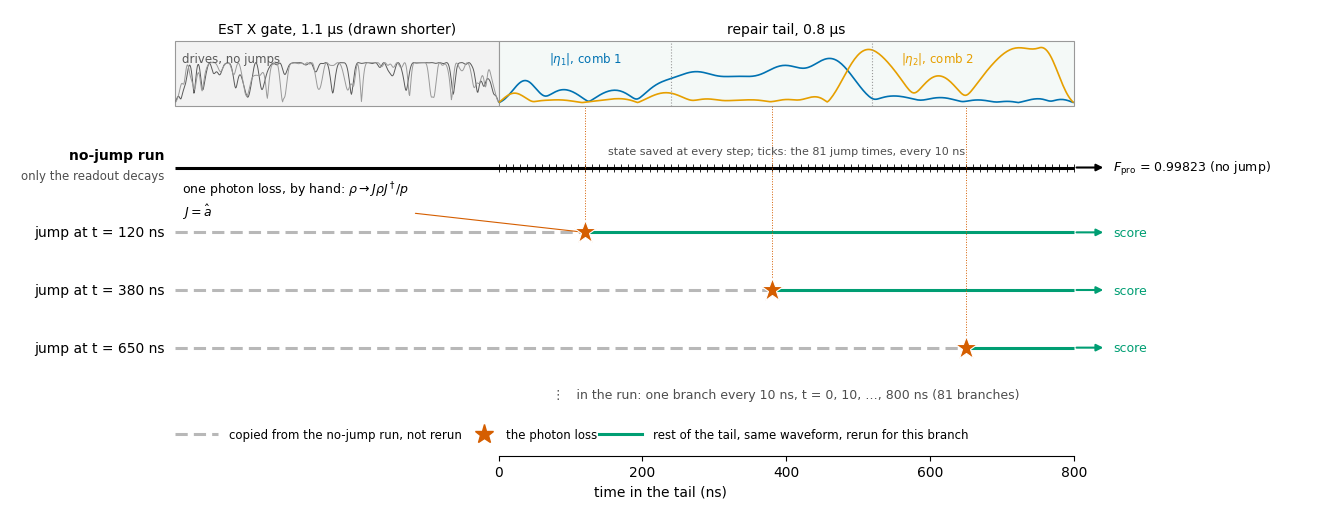

In [43]:
# Section 9.1, the simulation as a picture: the no-jump run, then one branch per jump time t.
# Three example branches are drawn (one per window of Table 22); the real run has one every 10 ns.
from matplotlib.patches import FancyBboxPatch

sc_eta = np.abs(np.load("pulses/dgrape/eta_X_tail_estg_T08_t2.npy"))
sc_u = np.load(EST_PULSE)
GATE_W = 450                                      # width the 1.1 us gate is drawn with (ns on the axis; shortened)
T_END = sc_eta.shape[0] * DT * 1e3                # 800 ns
SHARED, JUMP, AFTER = "0.72", OKABE[4], OKABE[2]

fig, ax = plt.subplots(figsize=(13.5, 5.2))
# top strip: the controls. Gate: |cavity| and |transmon| drives, shrunk to GATE_W; tail: |eta_1|, |eta_2|.
y0, h = 4.55, 0.9
ax.add_patch(FancyBboxPatch((-GATE_W, y0), GATE_W, h, boxstyle="square,pad=0", fc="0.95", ec="0.6", lw=0.8))
ax.add_patch(FancyBboxPatch((0, y0), T_END, h, boxstyle="square,pad=0", fc="#F4F9F7", ec="0.6", lw=0.8))
x_gate = -GATE_W + (np.arange(len(sc_u)) + 0.5) / len(sc_u) * GATE_W
for (i, q), col, lab in (((0, 1), "0.35", "cavity drive"), ((2, 3), "0.6", "transmon drive")):
    m = np.hypot(sc_u[:, i], sc_u[:, q])
    ax.plot(x_gate, y0 + 0.05 + 0.8 * m / 36, color=col, lw=0.7)
x_tail = (np.arange(len(sc_eta)) + 0.5) * DT * 1e3
for c, col in ((0, OKABE[0]), (1, OKABE[1])):
    ax.plot(x_tail, y0 + 0.05 + 0.8 * sc_eta[:, c] / 0.105, color=col, lw=1.2)
ax.text(-GATE_W / 2, y0 + h + 0.08, "EsT X gate, 1.1 μs (drawn shorter)", ha="center", va="bottom", fontsize=10)
ax.text(T_END / 2, y0 + h + 0.08, "repair tail, 0.8 μs", ha="center", va="bottom", fontsize=10)
ax.text(70, y0 + 0.62, r"$|\eta_1|$, comb 1", color=OKABE[0], fontsize=8.5)
ax.text(560, y0 + 0.62, r"$|\eta_2|$, comb 2", color=OKABE[1], fontsize=8.5)
ax.text(-GATE_W + 10, y0 + 0.62, "drives, no jumps", color="0.35", fontsize=8.5)

# the no-jump run
yr = 3.7
ax.plot([-GATE_W, T_END], [yr, yr], color="k", lw=2.2, solid_capstyle="butt")
x_jump = np.arange(0, T_END + 1, 10)
ax.plot(x_jump, np.full(len(x_jump), yr), "|", color="k", ms=6, mew=0.6)
ax.annotate("", xy=(T_END + 45, yr), xytext=(T_END, yr), arrowprops=dict(arrowstyle="-|>", color="k", lw=1.5))
ax.text(T_END + 55, yr, "$F_{\\rm pro}$ = 0.99823 (no jump)", va="center", fontsize=9)
ax.text(-GATE_W - 15, yr + 0.08, "no-jump run", ha="right", va="bottom", fontsize=10, fontweight="bold")
ax.text(-GATE_W - 15, yr - 0.02, "only the readout decays", ha="right", va="top", fontsize=8.5, color="0.3")
ax.text(T_END / 2, yr + 0.16, "state saved at every step; ticks: the 81 jump times, every 10 ns", ha="center", va="bottom", fontsize=8, color="0.3")

# example branches, one jump each
for yb, t in ((2.8, 120), (2.0, 380), (1.2, 650)):
    ax.plot([-GATE_W, t], [yb, yb], color=SHARED, lw=2.2, ls=(0, (4, 2)), solid_capstyle="butt")
    ax.plot([t, T_END], [yb, yb], color=AFTER, lw=2.2, solid_capstyle="butt")
    ax.plot([t, t], [yb, y0], color=JUMP, lw=0.7, ls=":")
    ax.plot(t, yb, marker="*", ms=17, color=JUMP, mec="white", mew=0.8, zorder=5)
    ax.annotate("", xy=(T_END + 45, yb), xytext=(T_END, yb), arrowprops=dict(arrowstyle="-|>", color=AFTER, lw=1.5))
    ax.text(T_END + 55, yb, "score", va="center", fontsize=9, color=AFTER)
    ax.text(-GATE_W - 15, yb, f"jump at t = {t} ns", ha="right", va="center", fontsize=10)
ax.annotate(r"one photon loss, by hand: $\rho \to J\rho J^\dagger/p$" "\n"
            r"$J = \hat a$",
            xy=(120, 2.8), xytext=(-GATE_W + 10, 3.25), fontsize=9, va="center",
            arrowprops=dict(arrowstyle="-", color=JUMP, lw=0.8))
ax.text(T_END / 2, 0.55, "⋮   in the run: one branch every 10 ns, t = 0, 10, …, 800 ns (81 branches)",
        ha="center", va="center", fontsize=9, color="0.3")
# legend for the line styles
ax.plot([-GATE_W, -GATE_W + 60], [0.0, 0.0], color=SHARED, lw=2.2, ls=(0, (4, 2)))
ax.text(-GATE_W + 75, 0.0, "copied from the no-jump run, not rerun", va="center", fontsize=8.5)
ax.plot(-GATE_W + 430, 0.0, marker="*", ms=14, color=JUMP)
ax.text(-GATE_W + 460, 0.0, "the photon loss", va="center", fontsize=8.5)
ax.plot([-GATE_W + 590, -GATE_W + 650], [0.0, 0.0], color=AFTER, lw=2.2)
ax.text(-GATE_W + 665, 0.0, "rest of the tail, same waveform, rerun for this branch", va="center", fontsize=8.5)

for x in (240, 520):                                # the windows of Table 22
    ax.plot([x, x], [y0, y0 + h], color="0.6", ls=":", lw=0.8)
ax.set_xlim(-GATE_W - 230, T_END + 330)
ax.set_ylim(-0.3, y0 + h + 0.45)
ax.set_xticks(np.arange(0, T_END + 1, 200))
ax.set_xlabel("time in the tail (ns)")
ax.set_yticks([])
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_bounds(0, T_END)
fig.tight_layout()
fig.savefig("figures/fwm_tails_transparency_scheme.png", dpi=150)
plt.show()

**Figure 16. How §9.1 puts one jump into the EsT + 0.8 μs tail.** Top: the controls (gate drives in grey, drawn
shorter than 1.1 μs; the two comb waveforms); dotted, the windows of Table 22. Black: the no-jump run, with the 81 jump
times as ticks. Below, three branches, one per window: dashed grey up to $t$ is copied from the no-jump run, the star is
the photon loss, green the rest of the tail, run for that branch only.
*Symbols:* $\rho$ = the state at $t$ (one per code input); $J = \hat a$, the photon-loss
operator; $p$ = the trace of $J\rho J^\dagger$; no-jump $F_{\rm pro}$ = 0.99823 at the end of the tail.

The diagram is trying to say that before the jump happens, the evolution a saved cropped version of the 'no-jump' run; after a photon is lost, it reruns only the rest of the evolution.

no jump: F_pro 0.99823 at the end of the tail (readout decay only)


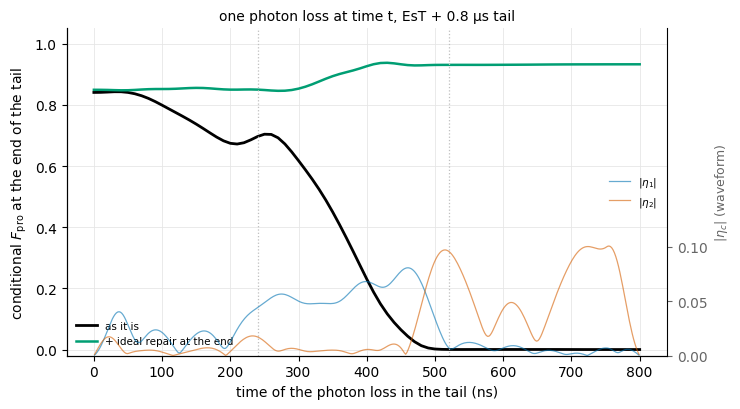

window,exposure,cost as it is,cost after ideal repair,summed branch: as it is,+ ideal repair (refit)
"0–240 ns, comb 1 weak",0.537%,0.123%,0.079%,0.770,0.857
"240–520 ns, comb 1 strong",0.668%,0.437%,0.067%,0.344,0.898
"520–800 ns, comb 2 only",0.641%,0.640%,0.043%,0.000,0.932
whole tail,1.847%,1.200%,0.189%,0.349,0.896


In [44]:
# Section 9.1: one photon loss inside the EsT + 0.8 us tail (the best tail of section 6). Gate (n_c 24, cut to 16, as
# in 6.2) and tail run with only the readout decaying. ONE photon is removed by hand at time t of the tail; the branch
# runs to the end of the tail and is scored two ways. Cached in the two CSVs; delete them to recompute
# (~1.5 min with 8 jobs).
from joblib import Parallel, delayed

TR_TAG = "X_tail_estg_T08_t2"
TR_ETA = np.load(f"pulses/dgrape/eta_{TR_TAG}.npy")
TR_KEEP = {"r"}                                  # the readout decays (a repair needs it); no other jumps
TR_STRIDE = 5                                    # steps between loss times: 10 ns
TR_JUMPS = {"photon loss": ("a", dev.kappa_a)}   # the jump under test: operator name, rate per photon (1/us)
TR_WIN = {"0–240 ns, comb 1 weak": (0, 240), "240–520 ns, comb 1 strong": (240, 520),
          "520–800 ns, comb 2 only": (520, 801), "whole tail": (0, 801)}
TR_CSV, TR_SUM_CSV = "tables/fwm_tail_transparency_jumps.csv", "tables/fwm_tail_transparency_summary.csv"


def tr_pop(R):
    """Branch weight: mean trace over the code inputs |0_L>, |1_L>."""
    return float(np.mean([np.real(np.trace(R[b])) for b in (0, 1)]))


def tr_kraus(Ks, R):
    return sum(np.einsum("ij,bjk,lk->bil", K, R, K.conj()) for K in Ks)


def tr_branch(rho_k, k, op):
    """One jump `op` on the state at step k of the tail, then the rest of the tail. Returns (weight, end state / weight)."""
    tm = ft.tail_model(N_C, 2, keep=TR_KEEP)
    J = operators(N_C, 2)[op]
    Rb = np.einsum("ij,bjk,lk->bil", J, rho_k, J.conj())
    p = tr_pop(Rb)
    if p < 1e-12:
        return p, None
    Rb = Rb / p
    return p, (ft.propagate(tm, TR_ETA[k:], Rb)[0] if k < len(TR_ETA) else Rb)


if not (os.path.exists(TR_CSV) and os.path.exists(TR_SUM_CSV)):
    tm = ft.tail_model(N_C, 2, keep=TR_KEEP)
    Tt, Wt = ft.tail_targets(N_C, 2)
    R_end, rhos = ft.propagate(tm, TR_ETA, ft.tail_input(np.load(EST_PULSE), N_C, 2, 24, keep=TR_KEEP), store=True)
    rhos = list(rhos) + [R_end]
    F_nojump = ft.fidelity_from_outputs(R_end, Tt, Wt)
    ks = list(range(0, len(TR_ETA) + 1, TR_STRIDE))
    jobs = [(name, k) for name in TR_JUMPS for k in ks]
    out = Parallel(n_jobs=8)(delayed(tr_branch)(rhos[k], k, TR_JUMPS[name][0]) for name, k in jobs)
    ends = {j: o for j, o in zip(jobs, out)}
    # one set of repair phases for every loss time: fitted on the photon-loss branches of the whole tail, summed
    R_loss = sum(ends[("photon loss", k)][0] * ends[("photon loss", k)][1] for k in ks)
    ph = ft.ideal_repair_fidelity(R_loss / tr_pop(R_loss), Tt, Wt, N_C, 2, n_starts=4)["phases"]
    REP = list(ft.ideal_repair_kraus(N_C, 2, phases=ph))
    rows = []
    for (name, k), (p, R) in ends.items():
        r = {"jump": name, "t_ns": k * DT * 1e3, "pop": p, "rate_per_us": TR_JUMPS[name][1], "F_nojump": F_nojump}
        if R is not None:
            r.update(f_as_is=ft.fidelity_from_outputs(R, Tt, Wt), f_repair=ft.fidelity_from_outputs(tr_kraus(REP, R), Tt, Wt))
        rows.append(r)
    pd.DataFrame(rows).to_csv(TR_CSV, index=False)
    # the time-summed branch of each window (what a later repair actually receives)
    srows = []
    for name in TR_JUMPS:
        for win, (lo, hi) in TR_WIN.items():
            sel = [k for k in ks if lo <= k * DT * 1e3 < hi and ends[(name, k)][1] is not None]
            R = sum(ends[(name, k)][0] * ends[(name, k)][1] for k in sel)
            R = R / tr_pop(R)
            srows.append({"jump": name, "window": win, "F_as_is": ft.fidelity_from_outputs(R, Tt, Wt),
                          "F_repair_refit": ft.ideal_repair_fidelity(R, Tt, Wt, N_C, 2, n_starts=4)["F"]})
    pd.DataFrame(srows).to_csv(TR_SUM_CSV, index=False)
TRJ, TRS = pd.read_csv(TR_CSV), pd.read_csv(TR_SUM_CSV)
TRJ = TRJ.assign(w=TRJ.rate_per_us * TRJ["pop"] * TR_STRIDE * DT)          # probability of a loss in that 10 ns
print(f"no jump: F_pro {TRJ.F_nojump.iloc[0]:.5f} at the end of the tail (readout decay only)")

fig, ax = plt.subplots(figsize=(7.5, 4.2))
t_ns = (np.arange(len(TR_ETA)) + 0.5) * DT * 1e3
g = TRJ[TRJ.jump == "photon loss"]
ax.plot(g.t_ns, g.f_as_is, color="k", lw=2.0, label="as it is")
ax.plot(g.t_ns, g.f_repair, color=OKABE[2], lw=1.8, label="+ ideal repair at the end")
ax2 = ax.twinx()
for c, col in ((0, OKABE[0]), (1, OKABE[4])):
    ax2.plot(t_ns, np.abs(TR_ETA[:, c]), color=col, lw=0.9, alpha=0.6, label=fr"$|\eta_{c + 1}|$")
ax2.set_ylim(0, 0.3)
ax2.set_yticks([0, 0.05, 0.1])
ax2.set_ylabel(r"$|\eta_c|$ (waveform)", fontsize=9, color="0.4")
ax2.tick_params(axis="y", colors="0.4")
ax2.spines["top"].set_visible(False)
ax2.legend(fontsize=7.5, frameon=False, loc="center right")
for x in (240, 520):
    ax.axvline(x, color="0.75", ls=":", lw=0.9)
ax.set_ylim(-0.02, 1.05)
ax.set_xlabel("time of the photon loss in the tail (ns)")
ax.set_ylabel("conditional $F_{\\rm pro}$ at the end of the tail")
ax.set_title("one photon loss at time t, EsT + 0.8 μs tail", fontsize=10)
ax.legend(fontsize=7.5, frameon=False, loc="lower left")
tidy(ax)
fig.tight_layout()
fig.savefig("figures/fwm_tails_transparency_jumps.png", dpi=150)
plt.show()

tr_rows = []
for win, (lo, hi) in TR_WIN.items():
    g = TRJ[(TRJ.jump == "photon loss") & (TRJ.t_ns >= lo) & (TRJ.t_ns < hi)].fillna(0.0)
    s = TRS[(TRS.jump == "photon loss") & (TRS.window == win)]
    tr_rows.append({"window": win, "exposure": g.w.sum(),
                    "cost as it is": (g.w * (g.F_nojump - g.f_as_is)).sum(),
                    "cost after ideal repair": (g.w * (g.F_nojump - g.f_repair)).sum(),
                    "summed branch: as it is": s.F_as_is.iloc[0],
                    "+ ideal repair (refit)": s.F_repair_refit.iloc[0]})
TRTAB = pd.DataFrame(tr_rows)
pct = {c: "{:.3%}" for c in ("exposure", "cost as it is", "cost after ideal repair")}
display(TRTAB.style.hide(axis="index")
        .format({**pct, **{c: "{:.3f}" for c in ("summed branch: as it is", "+ ideal repair (refit)")}})
        .set_caption("Table 22. One photon loss inside the EsT + 0.8 μs tail"))

**Figure 17. One photon loss at time $t$ inside the EsT + 0.8 μs tail.** Black: the branch as it is; green: after
an ideal repair at the end. Right axis: the two comb
waveforms. Dotted: the windows of Table 22.

**Table 22. Exposure, cost and what is left, for each window of the tail.**
*Symbols:* exposure = the chance of a photon loss in the window; cost = $\sum_t$ weight × (no-jump $F_{\rm pro}$ −
conditional $F_{\rm pro}$), in percentage points (after ideal repair: the same with the repair); summed branch = all
loss times of the window mixed with their weights, scored as it is and after the ideal repair (phases refitted); no-jump $F_{\rm pro}$ = 0.99823.

**What it shows.** The tail is semi-transparent to photon loss: a late loss is not repaired, but it is not lost
either.

- **Delayed, not lost.** A loss in the first 240 ns is mostly repaired in place (0.77). A loss after 520 ns is not
  repaired (0.000) but ends as a clean error word: an ideal repair takes it to 0.93 (the kitten limit). Over the tail 1.85 % of runs lose a photon, costing 1.20 % as is and 0.19 % if a repair
  followed.
- **The repair in the middle is half done.** A loss while comb 1 is strong (240–520 ns) ends at 0.34 as is, but an
  ideal repair still takes it to 0.90: the shot has started on it and not finished.
- **The ideal repair increase mid tail** the fidelity of the ideal repair increase in the middle of the tail, because before the increase, the error gets correct by the QEC tail + ideal repair (lower fidelity), after the tail can no longer correct it, so it gets corrected by the ideal repair at the end instead (higher fidelity).
- **The readout's decay costs early repairs a little** (0.77 with it, 0.83 closed): a readout photon that leaks away
  cuts comb 2's back-and-forth swap short.

## 9.2 Does the next pair repair it?

A late loss ends as a clean error word, which only a *later* repair can fix: in a computation, the next gate + tail.
§8's B2 protocol with two pairs, $n_c = 24$, readout decay only, one photon loss at time $t$ of tail 1 (every 20 ns):

```
 gate 1 ──▶ tail 1, loss at t ──▶ gate 2 ──▶ tail 2
                               ▲            ▲         ▲
                         after pair 1  after gate 2  after pair 2
```

Scored at the three checkpoints (against X, I, I), after pair 1 and gate 2 also with the ideal repair (what a perfect
next tail could do). With no loss: 0.99823, 0.99689, 0.99645.

no loss: after pair 1 0.99823, after gate 2 0.99689, after pair 2 0.99645


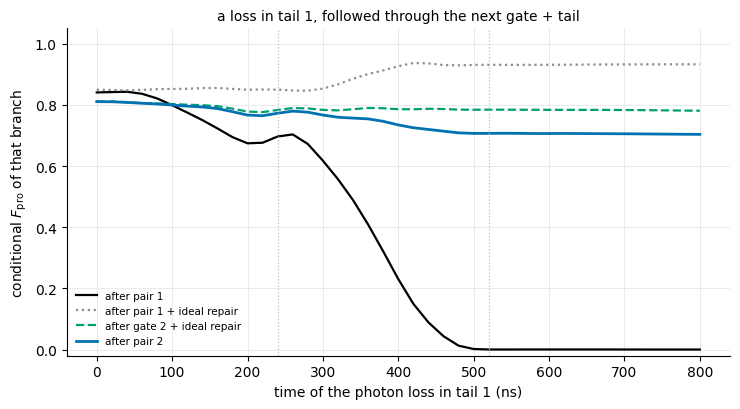

loss in tail 1,after pair 1,after pair 1 + ideal repair,after gate 2,after gate 2 + ideal repair,after pair 2
"0–240 ns, comb 1 weak",0.773,0.851,0.736,0.798,0.793
"240–520 ns, comb 1 strong",0.355,0.897,0.338,0.786,0.744
"520–800 ns, comb 2 only",0.000,0.932,0.000,0.783,0.706
whole tail,0.349,0.896,0.333,0.788,0.745


B2: the first pair loses 2.97%, a pair between N = 10 and 20 loses 2.07% (difference 0.91%; Table 7's unrepaired window costs 0.91 %)


In [45]:
# Section 9.2: does the NEXT (gate + tail) pair repair a photon lost in tail 1? Section 8's B2 protocol (gate, tail,
# gate, tail; target I), n_c 24, n_r 2, readout decay only, one photon loss put in by hand at time t of tail 1. The
# branch is scored at four checkpoints. Cached; delete the CSV to recompute (~11 min with 8 jobs).
from DGRAPE import fwm_repeat as fr

P2_CSV = "tables/fwm_tail_transparency_pair2.csv"
P2_NC = 24


def p2_models():
    return fr._models(P2_NC, 2, TR_KEEP, True, False, False)


def p2_branch(rho_k, k):
    """Loss at step k of tail 1: rest of tail 1, back to the DGRAPE frame, gate 2, tail 2. Returns the weight and the
    three normalized states (end of pair 1, after gate 2, end of pair 2)."""
    gm, tm = p2_models()
    a = operators(P2_NC, 2)["a"]
    Rb = np.einsum("ij,bjk,lk->bil", a, rho_k, a.conj())
    p = tr_pop(Rb)
    Rb = Rb / p
    R1 = ft.propagate(tm, TR_ETA[k:], Rb)[0] if k < len(TR_ETA) else Rb
    R1 = fr.frame_back(tm, len(TR_ETA) * DT, R1)
    G2 = fr.gate_step(gm, np.load(EST_PULSE), R1)
    P2 = fr.tail_step(tm, TR_ETA, G2)
    return p, R1, G2, P2


if not os.path.exists(P2_CSV):
    gm, tm = p2_models()
    TX, w2 = ft.tail_targets(P2_NC, 2, "X")
    TI, _ = ft.tail_targets(P2_NC, 2, "I")
    pulse = np.load(EST_PULSE)
    R_g1 = fr.gate_step(gm, pulse, fr.inputs(P2_NC, 2))
    R_t1, rhos = ft.propagate(tm, TR_ETA, R_g1, store=True)
    rhos = list(rhos) + [R_t1]
    P1 = fr.frame_back(tm, len(TR_ETA) * DT, R_t1)                       # no loss: the reference
    G2_0 = fr.gate_step(gm, pulse, P1)
    ref = {"after pair 1": ft.fidelity_from_outputs(P1, TX, w2), "after gate 2": ft.fidelity_from_outputs(G2_0, TI, w2),
           "after pair 2": ft.fidelity_from_outputs(fr.tail_step(tm, TR_ETA, G2_0), TI, w2)}
    ks = list(range(0, len(TR_ETA) + 1, 2 * TR_STRIDE))                  # every 20 ns
    out = Parallel(n_jobs=8)(delayed(p2_branch)(rhos[k], k) for k in ks)
    # one set of repair phases at each checkpoint, fitted on all loss times together (weighted)
    tot = lambda j: sum(o[0] * o[j] for o in out) / sum(o[0] for o in out)          # noqa: E731
    ph1 = ft.ideal_repair_fidelity(tot(1), TX, w2, P2_NC, 2, n_starts=4)["phases"]
    ph2 = ft.ideal_repair_fidelity(tot(2), TI, w2, P2_NC, 2, n_starts=4)["phases"]
    K1, K2 = list(ft.ideal_repair_kraus(P2_NC, 2, phases=ph1)), list(ft.ideal_repair_kraus(P2_NC, 2, phases=ph2))
    rows = []
    for k, (p, R1, G2, P2) in zip(ks, out):
        rows.append({"t_ns": k * DT * 1e3, "pop": p, "after pair 1": ft.fidelity_from_outputs(R1, TX, w2),
                     "after pair 1 + ideal repair": ft.fidelity_from_outputs(tr_kraus(K1, R1), TX, w2),
                     "after gate 2": ft.fidelity_from_outputs(G2, TI, w2),
                     "after gate 2 + ideal repair": ft.fidelity_from_outputs(tr_kraus(K2, G2), TI, w2),
                     "after pair 2": ft.fidelity_from_outputs(P2, TI, w2),
                     **{f"no loss, {s}": v for s, v in ref.items()}})
    pd.DataFrame(rows).to_csv(P2_CSV, index=False)
P2 = pd.read_csv(P2_CSV)
print("no loss: " + ", ".join(f"{s} {P2[f'no loss, {s}'].iloc[0]:.5f}" for s in ("after pair 1", "after gate 2", "after pair 2")))

fig, ax = plt.subplots(figsize=(7.5, 4.2))
for s, col, ls in (("after pair 1", "k", "-"), ("after pair 1 + ideal repair", "0.55", ":"),
                   ("after gate 2 + ideal repair", OKABE[2], "--"), ("after pair 2", OKABE[0], "-")):
    ax.plot(P2.t_ns, P2[s], color=col, ls=ls, lw=2.0 if s == "after pair 2" else 1.6, label=s)
for x in (240, 520):
    ax.axvline(x, color="0.75", ls=":", lw=0.9)
ax.set_ylim(-0.02, 1.05)
ax.set_xlabel("time of the photon loss in tail 1 (ns)")
ax.set_ylabel(r"conditional $F_{\rm pro}$ of that branch")
ax.set_title("a loss in tail 1, followed through the next gate + tail", fontsize=10)
ax.legend(fontsize=7.5, frameon=False, loc="lower left")
tidy(ax)
fig.tight_layout()
fig.savefig("figures/fwm_tails_transparency_pair2.png", dpi=150)
plt.show()

p2_rows = []
for win, (lo, hi) in TR_WIN.items():
    g = P2[(P2.t_ns >= lo) & (P2.t_ns < hi)]
    wt = g["pop"] / g["pop"].sum()                                      # loss rate ∝ photon number
    p2_rows.append({"loss in tail 1": win, **{s: float(np.dot(wt, g[s])) for s in
                    ("after pair 1", "after pair 1 + ideal repair", "after gate 2", "after gate 2 + ideal repair",
                     "after pair 2")}})
P2TAB = pd.DataFrame(p2_rows)
display(P2TAB.style.hide(axis="index").format({c: "{:.3f}" for c in P2TAB.columns[1:]})
        .set_caption("Table 23. A photon lost in tail 1, followed through the next gate + tail"))

# cross-check with section 8 (B2, open system, decay set): the first pair against a later pair
b2 = pd.read_csv("tables/fwm_tail_repeat_B2.csv")
b2 = b2[(b2.label == "EsT-good") & (b2.system == "open") & (b2.n_r == 2)].sort_values("N").set_index("N").F_pro
first, later = 1 - b2[1], 1 - (b2[20] / b2[10]) ** 0.1
print(f"B2: the first pair loses {first:.2%}, a pair between N = 10 and 20 loses {later:.2%} "
      f"(difference {first - later:.2%}; Table 7's unrepaired window costs 0.91 %)")

**Figure 18. A photon lost in tail 1, followed through the next gate + tail.** Conditional $F_{\rm pro}$ against the
time of the loss, at the checkpoints of the sketch. Dotted: the windows of Table 22.

**Table 23. The same, averaged over each window** (weights ∝ $\kappa_a\langle\hat n\rangle$).
*Symbols:* after pair 1 against X, after gate 2 and pair 2 against I; + ideal repair = §2.1's photon-add, one phase
set per checkpoint.

**What it shows.** The next pair repairs the late losses; the gate in between limits it.

- **Repaired one pair later:** a loss in the last 280 ns of tail 1 ends pair 1 at 0.000 and pair 2 at 0.71; over the
  whole tail, 0.35 becomes 0.74.
- **The gate is the leak:** right after tail 1 the error word would repair to 0.93; after gate 2 only to 0.78, and
  tail 2 gets 0.71. The EsT gate was trained to
  keep losses *during* it repairable, not an error word present at its start.
- **It is already in §8:** in B2 (Table 18) the first pair loses 2.97 % and a later pair 2.07 % (printed); the 0.91 %
  difference equals the cost of Table 7's unrepaired window. In a long sequence each pair's late losses are repaired
  by the next pair.

## 9.3 What this says

- **The tail is already semi-transparent to photon loss,** and repeated use pays for it (§8): a late loss ends as a
  clean error word, and the next pair repairs it. The leaks left are the next gate (0.93 → 0.78 repairable) and the
  readout's decay during comb 2's swap (0.83 → 0.77): they ask for a gate that carries an incoming error word and a
  one-way comb 2.
- **Limits:** one tail, one photon loss per branch with only the readout decaying otherwise, an instant ideal repair
  as the yardstick.

# 10. Conclusions and next steps

**What the simulations show.**

1. **After the EsT gate, an instant repair is worth +1.99 % (§2).** Photon loss is 2.40 % of the gate's 4.27 %
   infidelity (all channels; Figure 1), and a perfect, instant repair wins back 1.98 % of it (0.9671 → 0.9870), because
   a loss at any time in the gate stays repairable (0.85 on average, 0.93 for a late one). The other 1.9 %, transmon
   decay, dephasing, heating and the coherent error, is out of a tail's reach. Waiting costs 2.7 % per μs idle.
2. **The gate decides (§3, §6.1).** The EsT gate keeps a loss during it repairable (0.851 after an ideal repair; d2
   0.461) and is also the best gate alone (0.967). The same tail gains +0.28 % at 1 μs after EsT and loses 0.58 % and
   0.67 % after Ord and d2.
3. **A trained tail repairs photon loss with one ~600 ns shot at its end (§6.2, §6.3).** A loss before the shot repairs
   to 0.92, a loss after it not at all, and nothing coherent is fixed (closed, every tail is within 0.01 % of its gate
   alone). The price is transmon decay while the shot holds population in $|f\rangle$, about 0.25 %. With no gate in
   front (§6.6) every tail leaves the code words alone (closed ≥ 0.9998) and repairs a clean error word to 97–99 % of
   the kitten limit; open, readout decay is the largest cost of a short repair (6.2 % at 0.8 μs, none at 2 μs).
4. **A small gain, and fragile (§6.1, §6.4, §6.5).** The best tail, EsT + 0.8 μs, gains +0.32 %. The slow
   shot, transmon decay and imperfect repairs take three quarters of the +1.23 % estimate (Table 9). A 10 % pump error
   costs about 10 %; dephasing and heating remove the gain; a readout that must end empty costs 1.2 %.
5. **The tail works after the H gate too, and corrects the same way (§7).** After the 2 μs EsT H gate a 0.8 μs
   tail trained from a cold start gains +1.19 % (0.9501 → 0.9620), and the X tail moved over unchanged +1.30 %:
   the longer gate loses more photons, so there is more to repair, and the gain survives dephasing and heating
   (+0.98 %). Both tails are the same photon-loss corrector with different timing: with no gate in front they repair
   clean error words to 0.90 and 0.89, and their repair against the time of the loss is the same after either gate.
   Both cold starts stop in an early-shot optimum that the X tail beats.
6. **Tails pay off over many gates (§8).** One tail after 20 EsT gates gains +7.3 %. 20 gate + tail pairs keep 0.642
   against 0.520 for 20 gates back to back (0.979 per pair against 0.968 per gate), and a tail every 2–5 gates does as
   well or slightly better in less time (§8.4). Retrained for the state after m gates, a tail adds little in one block
   (−0.07 to +0.94 %) but keeps 2.3–2.8 % more over 40 gates; the best schedule, a tail retrained for 2 gates after
   every 2 gates, keeps 0.478 after 40 gates against 0.451 reused (§8.5). Ord gains nothing per gate. As a memory, the Stark-tuned QEC teeth beat the
   EsT pairs from about 9 to 41 μs and fall below them after that.
7. **The tail is semi-transparent to photon loss (§9).** A late loss is not repaired but ends as a clean error word
   (0.93 after an ideal repair), and the next gate + tail repairs it to 0.71. The next gate is the leak: it takes the
   error word from 0.93 to 0.78 repairable.

**Next steps,** each aimed at one gap above, roughly in order of cost.

1. **A faster shot, above all comb 2** (findings 3, 4). The unrepaired end of the shot costs about 1 % (Table 7),
   three times the net gain, and is the largest single term in Table 9. Levers: comb 2's cap, or one cap on
   $|\eta_1|^2 + |\eta_2|^2$ instead of one per comb. Target: the unprotected window down from 498 ns towards the
   300 ns of the estimate.
2. **Robust training** (finding 4). Average the cost over pump scales of about ±5 % (the Stark shift moves with them).
   Target: η × 0.9 and × 1.1 each cost well under 1 %, without losing the gain.
3. **Train with all channels** (finding 4). Dephasing and heating are only in the held-out scoring today, and they
   remove the gain.
4. **A gate trained for repairable losses** (finding 2), for example against the ideal repair's adjoint targets,
   $\hat T_b \to \mathcal R^\dagger(\hat T_b)$ ($\mathcal R$ = the ideal repair), so that loss branches land where the
   repair expects them. A more transparent gate alone did not do it: seed 24's four times lower $\Delta_{\rm QEC}$
   repairs a mid-gate loss no better than the earlier gate (`est_gate_selection.ipynb`).
5. **Train gate and tail for repeated use** (findings 6, 7). A tail trained for its input already pays over 40 gates
   (§8.5); next, train it on a later block's input, inside the chain, and train the gate to carry an incoming error
   word (0.93 → 0.78 today). Add a transmon
   reset: after 20 pairs $P_e$ ≈ 0.12.
6. **A one-way comb 2** (findings 3, 7). Readout decay during comb 2's swap cuts early repairs short (0.83 → 0.77)
   and costs a clean error word 6.2 % at 0.8 μs (Table 11).
7. **One tail for every gate** (finding 5). The tail does not depend on the gate in front, so train one tail on the
   outputs of several gates (X and H) at once, starting from the X tail; it already beats both H cold starts.

**Suggested first: 1 and 2 together.** They are the largest term (about 1 %) and the reason the best tail is not usable,
and both change only how the tail is trained (same gate, same scripts).

The checklist of what was verified and the open decisions are in Appendix B (B.4, B.5).

# Appendix A. Checks and cost

## A.1 Checks of the propagator and the gradient

Each check compares the tail propagator with something it does not use; `validation/test_fwm_tail.py` runs smaller
versions of all three.

1. **No pumps = DGRAPE's idle evolution:** with $\eta = 0$, same $F_{\rm pro}$ and transmon-$g$ block.
2. **The frame is exact:** a random piecewise-constant $\eta$ (Stark and pump mixing on) against `fwm.propagate` in the
   DGRAPE frame with explicit carriers and CF4 sub-steps, which must converge to it at fourth order.
3. **The gradient:** the W form against the augmented-generator derivative and central differences.

In [46]:
# Check 1: eta = 0 for 0.5 us at n_c = 16
N05 = ft.n_steps(0.5)
R0 = ft.d2_output(N_C, 2)
R_tail, _ = ft.propagate(tm16, np.zeros((N05, 2)), R0)
R_dg = lnp.propagate(fwm.model_with_channels(N_C, 2, None, True), np.zeros((N05, 4)), R0, DT)
g_idx = (np.arange(tm16.model.d) // 2) % 3 == G
for readout in ("traced", "empty"):
    T_, w_ = ft.tail_targets(N_C, 2, readout=readout)
    print(f"readout {readout:6s}: F tail {ft.fidelity_from_outputs(R_tail, T_, w_):.12f}, "
          f"F DGRAPE {ft.fidelity_from_outputs(R_dg, T_, w_):.12f}")
print(f"largest difference in the transmon-g block: {np.abs(R_tail[:, g_idx][:, :, g_idx] - R_dg[:, g_idx][:, :, g_idx]).max():.1e}")

readout traced: F tail 0.943625106382, F DGRAPE 0.943625106382
readout empty : F tail 0.943625106382, F DGRAPE 0.943625106382
largest difference in the transmon-g block: 2.4e-14


In [47]:
# Check 2: the frame against the DGRAPE frame with explicit carriers, n_c = 10, 0.1 us, strong random eta
n_c10, N_chk = 10, 50
rng = np.random.default_rng(0)
eta_chk = 0.05 * (rng.normal(size=(N_chk, 2)) + 1j * rng.normal(size=(N_chk, 2)))
tm10 = ft.tail_model(n_c10, 2, mixing=1.0)
R0_10 = ft.d2_output(n_c10, 2)
R_f, spec_f = ft.propagate(tm10, eta_chk, R0_10)
m10 = Model(n_c10, 2, include_higher_order=True)
fw10 = fwm.fwm_terms(m10, 1.0, paths=(ft.N_REF,))
fw10.Delta = np.array([tm10.delta_ref, -tm10.delta_ref])
ph = np.exp(1j * tm10.delta_ref * N_chk * DT * np.real(np.diag(operators(n_c10, 2)["Pf"])))
R_f_dg = ph[:, None] * R_f * ph[None, :].conj()            # back to the DGRAPE frame
T10, w10 = ft.tail_targets(n_c10, 2)
rows = []
for S in (2, 4, 8, 16):
    R_d, spec_d = fwm.propagate(m10, fw10, np.zeros((N_chk, 4)), eta_chk, DT, S, R0_10)
    rows.append({"CF4 sub-steps S": S, "max |rho_DGRAPE - rho_tail|": np.abs(R_d - R_f_dg).max(),
                 "F_DGRAPE - F_tail": ft.fidelity_from_outputs(R_d, T10, w10) - ft.fidelity_from_outputs(R_f, T10, w10),
                 "Taylor (s, m) per exponential": str(spec_d)})
display(pd.DataFrame(rows).style.hide(axis="index")
        .format({"max |rho_DGRAPE - rho_tail|": "{:.1e}", "F_DGRAPE - F_tail": "{:+.1e}"})
        .set_caption(f"Table A1. One exponential per step (Taylor {spec_f}) against CF4 in the DGRAPE frame"))

CF4 sub-steps S,max |rho_DGRAPE - rho_tail|,F_DGRAPE - F_tail,"Taylor (s, m) per exponential"
2,5.0e-05,+2.3e-05,"(1, 15)"
4,3.2e-06,+1.4e-06,"(1, 12)"
8,2.0e-07,+9.0e-08,"(1, 10)"
16,1.2e-08,+5.6e-09,"(1, 8)"


**Table A1. One exponential per step against CF4 in the DGRAPE frame** ($n_c = 10$, 0.1 μs, random $|\eta|$ up to
0.12, Stark and mixing on).
*Symbols:* $S$ = CF4 sub-steps per 2 ns step; $\rho$ = the output density matrices; Taylor $(s, m)$ = scaling steps and
series terms per exponential.

In [48]:
# Check 3: the exact gradient, n_c = 8, 20 steps
tm8 = ft.tail_model(8, 2, mixing=1.0)
R0_8 = ft.d2_output(8, 2)
T8, w8 = ft.tail_targets(8, 2)
rng = np.random.default_rng(1)
eta8 = 0.05 * (rng.normal(size=(20, 2)) + 1j * rng.normal(size=(20, 2)))
deta = rng.normal(size=(20, 2)) + 1j * rng.normal(size=(20, 2))
F8, g8 = ft.fidelity_and_grad(tm8, eta8, R0_8, T8, w8)
w_form = np.sum(g8 * fwm.real_from_beta(deta))
aug = ft.directional_derivative(tm8, eta8, R0_8, T8, w8, deta)
h = 1e-6
fd = (ft.fidelity(tm8, eta8 + h * deta, R0_8, T8, w8) - ft.fidelity(tm8, eta8 - h * deta, R0_8, T8, w8)) / (2 * h)
print(f"W form {w_form:+.15f}\naugmented {aug:+.15f}   (relative difference {abs(w_form - aug) / abs(aug):.1e})\n"
      f"central differences {fd:+.12f}   (relative difference {abs(w_form - fd) / abs(fd):.1e})")

W form -0.035802026860084
augmented -0.035802026860084   (relative difference 5.8e-16)
central differences -0.035802026899   (relative difference 1.1e-09)


**Reading the checks.** (1) Tail and DGRAPE agree to round-off, readout traced or empty. (2) CF4 converges to the
tail's answer 16 times closer per doubling of $S$, the fourth-order rate: the single exponential per step is exact.
(3) The W form equals the augmented derivative to about $10^{-15}$ relative, central differences to about $10^{-9}$.

## A.2 Cost of one evaluation

One cost-and-gradient evaluation (three process inputs as three parallel jobs), $n_c = 16$, the 1 μs tail after d2.

In [49]:
obj = ft.TailObjective(tail_us=ft.TAIL_US, n_c=N_C, n_jobs=3)
try:
    x_t2 = ft.eta_preimage(lib["tableII"])
    obj.evaluate(np.zeros_like(x_t2) + 1e-9)                # warm up the workers (model build)
    t0 = time.time()
    cost_t2, g_t2, terms_t2 = obj.evaluate(x_t2)
    t_eval = time.time() - t0
finally:
    obj.close()
spec_tail = fwm.spec_for(tm16.model, tm16.fw, np.zeros((1, 4)), np.full((1, 2), 0.1), DT, 1, "midpoint")
m16 = Model(N_C, 2, include_higher_order=True)
fw16 = fwm.fwm_terms(m16)
spec_cf4 = fwm.spec_for(m16, fw16, np.zeros((1, 4)), np.array([[0.1, 0, 0, 0.1, 0, 0]]), DT, 2, "cf4")
print(f"one evaluation, {ft.TAIL_US:g} μs tail, n_c = {N_C}, 3 jobs: {t_eval:.1f} s   (F_pro {terms_t2['F_pro']:.5f})")
print(f"Taylor (s, m) at the cap: tail {spec_tail}, one exponential per step; "
      f"fwm_grape CF4 S = 2: {spec_cf4}, four per step")

one evaluation, 1 μs tail, n_c = 16, 3 jobs: 3.8 s   (F_pro 0.92824)
Taylor (s, m) at the cap: tail (1, 18), one exponential per step; fwm_grape CF4 S = 2: (1, 15), four per step


**Reading.** About 4 s alone on the Mac with 3 jobs; linear in tail length, steep in $n_c$. Training runs side by side
on the Windows PC took about 27 s per 1 μs evaluation (Appendix B.2). `fwm_grape`'s 1.1 μs Stage 2 evaluation took
48–62 s: one exponential per step (18 Taylor terms) instead of CF4's four (60 terms per step).

# Appendix B. Decisions and run logistics

## B.1 Decisions

| item | choice | date |
|---|---|---|
| input to the tail | the mixed output state of a gate: EsT in §2 (d2 until 2026-11-10), d2 in §4; for training, EsT, Ord and d2 | 2026-10-19; EsT and Ord 2026-10-20 |
| baseline | **the same gate alone**, scored at the end of the gate (d2: $F_{\rm pro} = 0.955554$ at $n_c = 16$) | 2026-10-19 |
| controls | the two combs only; the cavity drive may be added later | 2026-10-19 |
| strength cap | $\lvert\eta_c(t)\rvert = \lvert\xi_c(t)\rvert \le 0.1$ for each comb (§4.1) | 2026-10-19 |
| readout | readout decay in the model; the readout is **traced out** at the end; $\langle\hat n_r\rangle$ at the end is reported | 2026-10-19 |
| tail length | **1 μs** by default, a parameter (3 μs until 2026-10-20, see §2.4); baselines also at 0.5, 2 and 3 μs | 2026-10-20 |
| free rotation | **none**: the target is the ideal X. The storage Kerr phase and the tail's own Stark rotation are errors the tail must cancel | 2026-10-19 |
| EsT gate (§3) | first EST's cost and two-stage weights, seed 42 (the "mid" gate, no longer shown); then **seed 24 of the $C_{\rm err}$ cost**, picked out of 50 seeds by a rule fixed before training (`est_gate_selection.ipynb`). Closed system, d2's chip, code, duration, drive limits and start shape; scored in the open system | 2026-10-20; seed 24 picked 2026-10-29 |
| control for it | an Ord gate trained the same way (seed 42) with the transparency terms off | 2026-10-20 |
| tails in §3 | upper limits and fixed tails only (ideal repair, idle, QEC teeth) | 2026-10-20 |
| teeth in §8 | each QEC tooth moved by its mean pump Stark shift (±204 kHz; `fwm_tail.teeth_stark_shifts`); the untuned rows are kept as `bare carriers`. §2, §3, §6 keep the no-pump lines | 2026-11-09 |
| tail training (§5, §6) | first campaign: mid EsT, Ord and d2; 0.5, 1, 2 μs; starts QEC teeth and zero + noise (d2: QEC teeth only); the tail at $n_c = 16$ on the gate output propagated at $n_c = 24$ and cut (≤ 2 × 10⁻⁵ lost) | 2026-10-21 |
| EsT tails at five lengths | 0.5, 0.8, 1, 1.4, 2 μs after the seed-24 gate, both starts, 600 iterations in one leg | 2026-10-31 |
| replace mid with good | the seed-24 gate is "EsT" throughout; the good-vs-mid comparison (a former appendix) was removed 2026-11-09 | 2026-11-01 |
| truncation | $n_c = 16$ for d2; $n_c = 24$ (held out: 28) for anything with a closed-trained gate, which reaches photon number 13–17 | 2026-10-20 |
| error-transparency check (§9) | one photon loss put in by hand every 10 ns of the EsT + 0.8 μs tail, readout decay only (`keep={"r"}`), tail at $n_c = 16$; the next pair at $n_c = 24$, every 20 ns. Forward only, ~12.5 min with 8 jobs (§9.1 1.5 min, §9.2 11 min); cached in `tables/fwm_tail_transparency_{jumps,summary,pair2}.csv` | 2026-11-04 |
| jumps tested in §9 | photon loss only; f→e and e→g decay dropped from §9 (user) | 2026-11-09 |
| tails retrained after m gates (§8.5) | 0.8 μs, m = 1–8 EsT gates of open evolution, cold starts QEC teeth and zero + noise, the better kept; scored alone and after every m gates up to 40 | 2026-11-09 |
| limits in §2 | the EsT X gate (seed 24) at $n_c = 24$, tails at 16 on the cut output, instead of d2; its infidelity split by channel (all channels, one at a time) in a pie, Figure 1; Figure 2 for the EsT gate only (user) | 2026-11-10 |
| population map in §2.2 | Figure 3: the state at $T_g$ split into right / wrong code word, odd outside the code, right / wrong error word, even uncorrectable, transmon in e or f, per row of Table 1; correctable = on the right error word $\hat a X|b\rangle$; numbers in Table C10 (user) | 2026-11-11 |
| Table 1b | where the even population sits at $T_g$, per row of Table 1 and per logical input: shares at $n = 0, 2, 4, 6, \ge 8$, on the right / wrong error word, overlap of the two inputs; explains Table 1's gain per unit (user) | 2026-11-11 |
| tails after the H gate (§7) | the EsT H gate of `est_gate_selection.ipynb` §7 (seed 17, 2 μs, user); a 0.8 μs tail trained for it from the two cold starts, 600 iterations, target H; the X tail and the H tail also swapped between the gates | 2026-11-10 |

## B.2 Run logistics

- **Machine.** The tails were trained on the Windows PC. numpy there uses OpenBLAS, so the scripts'
  `MKL_NUM_THREADS=1` does nothing, and each joblib worker took 8 threads. The runs were launched with
  `OPENBLAS_NUM_THREADS=2`, which cut one 1 μs evaluation from 31 s to 12 s with a run alone on the machine.
- **First leg (d2, Ord and the mid gate).** Four runs side by side (`xargs -P 4`, longest first), which roughly
  doubles the time per evaluation: about 11 s (0.5 μs), 27 s (1 μs) and 50–56 s (2 μs), with about 1.06 evaluations per iteration. The 15 runs took
  10.4 h (2026-10-21, 02:14 to 12:37).
- **Resumed leg.** The eight resumed runs, four side by side, took 8.1 h (2026-10-21 20:53 to 2026-10-22 04:57).
- **Total per run (d2, Ord).** About 5 h for a 1 μs tail (600 iterations) and 11 h for a 2 μs tail (Table C5, "hours").
- **EsT tails (2026-10-31).** Ten runs of 600 iterations, eight side by side with one BLAS thread each (about 12 %
  more throughput than four with two). 3.1–3.6 h for 0.5 μs, about 8 h for 0.8 and 1 μs, 12–13 h for 1.4 μs and
  16–18 h for 2 μs (Table C5, "hours"). Held-out scoring with `DGRAPE/fwm_tail_score.py` writes
  `tables/fwm_tail_heldout_good.csv`.
- **Tails retrained after m gates (2026-11-09/10).** 14 runs of 600 iterations side by side, one BLAS thread
  each, 15.7 h; the whole job was capped at 80 % of the CPU (user). Scoring (`--matched`, 17 jobs) 3 h.
- **H tails (2026-11-10).** Two runs of 600 iterations side by side, two BLAS threads each, about 16 s per
  iteration, 2.7 h each (`--gate-pulse pulses/dgrape/u_H_est_err_closed_T2_s17.npy --gate-n-c 24 --target H
  --tail-us 0.8`, tags `H_tail_esth_T08_{t2,z}`, outputs in `~/fwm_runs/tails_H`). Held-out scoring of the two runs
  and the two swaps, 16 jobs, 7 min → `tables/fwm_tail_heldout_H.csv`; the §7 caches
  (`tables/fwm_tail_H_{baselines,profiles,code}.csv`) take a few minutes each.

- **Commands.** For example:

  ```
  python3 DGRAPE/train_fwm_tail.py --gate-pulse pulses/dgrape/u_X_est_err_closed_s24.npy --gate-n-c 24 \
      --tail-us 0.8 --start tableII --tag X_tail_estg_T08_t2 --max-iter 600
  python3 DGRAPE/train_fwm_tail.py --tail-us 1 --start tableII --tag X_tail_d2_T1_t2 --max-iter 300     # d2
  ```

  Each run writes `eta_<tag>.npy`, `xe_<tag>.npy`, `xe_<tag>_best.npy` (for resuming, `--start xe_<tag>_best.npy`) and
  `<tag>.json` to `~/fwm_runs`; these were copied to `pulses/dgrape/` (never `pulses/`).

## B.3 How the EsT and Ord gates were trained

Code: `DGRAPE/est_gate.py` (cost and measures), `DGRAPE/train_est_gate.py` (training), `DGRAPE/est_gate_seeds.py`
(the 50-seed selection).

- **Shared with d2:** chip, code, duration (1.1 μs), 2 ns steps, drive limits (bands ±27/±33 MHz, 48 ns ramp, cap
  25 rad/μs, box 25) and the shape of the smooth start (each gate from its own seed).
- **EsT (variant `est_err`, seed 24):** EST's cost in the closed system, $n_c = 20$, two stages of 2000 iterations,
  with the $C_{\rm err}$ term of `est_optimization.ipynb` §7 in stage 1. Weights (fidelity, transparency, even speed,
  drive cap, $C_{\rm err}$, two unused terms): stage 1 (1, 0.7, 7, 1, 0.3, 0, 0) builds transparency, stage 2
  (1, 0.1, 0, 1, 0, 0, 0) closes the gate. Stage 1 ended at F1 0.528 with $F_{\rm ET}$ 0.898 (a pulse that barely
  drives is trivially transparent); stage 2 closed it to F1 0.99871 with $F_{\rm ET}$ 0.800 (Ord: 0.331); 89 min.
- **Seed selection** (`est_gate_selection.ipynb`, rule fixed before training): F1 ≥ 0.99; peaks of $\Delta_{\rm QEC}$,
  $L$, $\eta_{\rm ET}$ ≤ 0.5; their means over the last 10 % of the gate ≤ 0.1 / 0.2 / 0.2; F1 at $n_c$ 28 and 24
  agreeing to $10^{-4}$; rank by the mean of the three time means. Of 50 seeds, 5 passed; seed 24 ranked first (score
  0.110).
- **Ord (seed 42):** the plain EST cost's two stages with the transparency and speed weights set to 0.
- **EST's tiers** (printed under Figure 4): *closed* (F1 ≥ 0.999), *open* (drives, but F1 < 0.999), *parked* (barely
  drives). They have nothing to do with the open or closed *system*. EsT seed 24 is *open*, Ord *closed*.

```
python3 DGRAPE/train_est_gate.py --variant est_err --seed 24 --maxiter 2000 --tag X_est_err_closed_s24
python3 DGRAPE/train_est_gate.py --variant ord --maxiter 2000     # tag X_ord_closed
```

## B.4 Checklist

| # | check | status |
|---|---|---|
| 1 | The frame is exact: idle = DGRAPE idle; random $\eta$ = DGRAPE frame with CF4 | done (Appendix A; tests `Idle`, `Frame`) |
| 2 | Teeth land on their paths (offsets, a path-1 swap) | done (Table 5; test `Teeth`) |
| 3 | Exact gradient: W form = augmented = central differences | done (Appendix A; test `Gradient`) |
| 4 | Objective: pre-image gradient, cap penalty, 3 jobs = 1 job | done (test `Objective`) |
| 5 | Input = the gate's output, propagated at $n_r = 2$ directly | done (test `Input`) |
| 6 | Upper limits: ideal repair, kitten limit | done (§2; test `Ceilings`) |
| 7 | $n_r = 2$ against 3 | done for modest pumps (test `Readout`); trained tails in held-out scoring (§6.5) |
| 8 | Timing of one evaluation | done (Appendix A.2) |
| 9 | EsT gate on this chip: closed cost and gradient, frame = DGRAPE's, transparency measures | done (§3; `validation/test_est_gate.py`) |
| 10 | Training a tail | done (§6): 19 runs; EsT + 0.8 μs +0.32 % (the best), EsT 1 and 1.4 μs smaller gains, every d2 and Ord tail a loss |
| 11 | Repeated gates | done (§8; `validation/test_fwm_repeat.py`): a tail every k gates (§8.4), tails retrained after m gates (§8.5; test `NGates`) |
| 12 | Is the tail error transparent? | done (§9): semi-transparent to photon loss, the next pair repairs it |
| 13 | Tails after the H gate | done (§7): X gate + X tail reproduces Table 6 and §6.2's loss-time cache; H tail +1.19 %, the X tail after H +1.30 %, held out at $n_c = 28$ the same |

## B.5 Open decisions

| decision | options | current choice |
|---|---|---|
| the gate | d2 / EsT / a gate trained for repairable losses | EsT (seed 24); the gain follows how repairable the gate leaves its losses |
| tail length | 0.5 – 3 μs | 0.8–1 μs (+0.32 %, +0.28 %; 0.8 μs is more fragile); 0.5 μs is too short for the ~600 ns shot |
| controls | combs / combs + cavity drive | combs; the cavity drive keeps the frame exact and is the next knob |
| cap | per comb / on $\lvert\eta_1\rvert^2 + \lvert\eta_2\rvert^2$ | 0.1 per comb |
| readout at the end | traced / must be empty | traced; "empty" reported (Figure 8, Table C9) |

# Appendix C. Supporting tables and figures

Results that back the main text but are not needed to follow it. Each is computed by the cells above; nothing here is
new.

In [50]:
display(pd.DataFrame(timing_rows).style.hide(axis="index")
        .format({"share of losses": "{:.1%}", "F after ideal repair": "{:.3f}", "F without repair": "{:.3f}"})
        .set_caption("Table C1. Photon losses during the EsT gate, by when they happen"))

loss time (μs),share of losses,F after ideal repair,F without repair
0.0-0.2,17.0%,0.792,0.061
0.2-0.4,18.0%,0.843,0.109
0.4-0.6,19.4%,0.872,0.165
0.6-0.8,19.0%,0.854,0.171
0.8-0.9,9.2%,0.821,0.137
0.9-1.0,9.0%,0.879,0.107
1.0-1.1,8.4%,0.927,0.055


**Table C1. Photon losses during the EsT gate, grouped by when they happen** (Figure 2 binned).
*Symbols:* share of losses = fraction of all single-loss branches in that window; F after / without repair =
conditional $F_{\rm pro}$ of those branches at $T_g$.

In [51]:
est_rows = []
for T in TAIL_LENGTHS:
    gain, late, rep, total = tail_estimate(GAIN_IDEAL, T)
    est_rows.append({"tail (μs)": T, "gate's losses repaired": gain, "losses too late": late,
                     "repaired losses (kitten limit)": rep, "estimate vs gate alone": total})
cols = [k for k in est_rows[0] if k != "tail (μs)"]
display(pd.DataFrame(est_rows).style.hide(axis="index").format({**{c: "{:+.2%}" for c in cols}, "tail (μs)": "{:g}"})
        .set_caption("Table C2. The estimate of Table 4 term by term, after the EsT gate"))

tail (μs),gate's losses repaired,losses too late,repaired losses (kitten limit),estimate vs gate alone
0.5,+1.99%,-0.66%,-0.03%,+1.30%
1,+1.99%,-0.66%,-0.10%,+1.23%
2,+1.99%,-0.66%,-0.24%,+1.09%
3,+1.99%,-0.66%,-0.39%,+0.95%


**Table C2. The §3.3 estimate term by term, after the EsT gate.** The last column is the sum of the three before it.
*Symbols:* the three terms of the §3.3 formula, in % of $F_{\rm pro}$. The gain stays positive at every length
(+0.95 % at 3 μs): the late and kitten-limited losses take about half of the +1.99 % repair gain. After d2
(+0.96 %) they took all of it at 3 μs.

In [52]:
display(cmp_txt.style.set_caption("Table C3. The three gates compared, every row"))

**Table C3. The three gates compared, every row** (Table 3 is a selection).
*Symbols:* as Table 3; "F1 at n_c 24 minus F1 at n_c 16" = how far the closed fidelity moves with the truncation
(the closed-trained gates need $n_c \ge 20$); idle tail and QEC teeth = the fixed 1 μs tails of §2.3, after each
gate (both cost about the same after every gate).

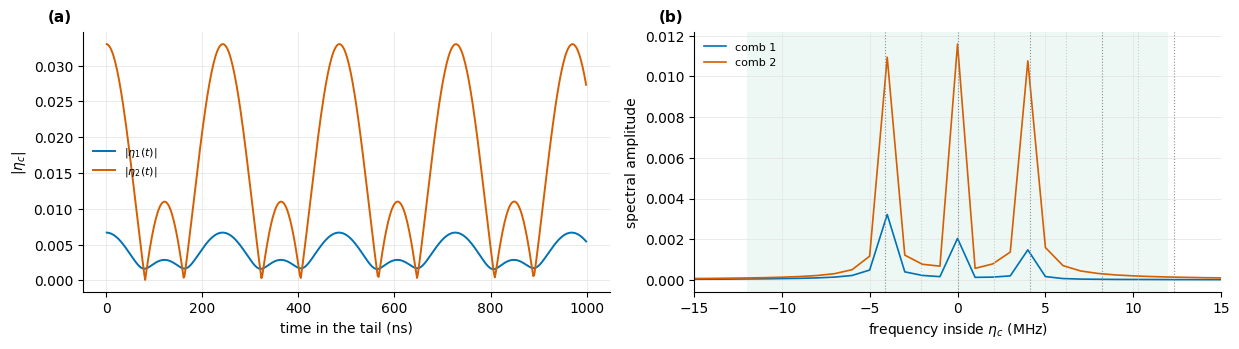

In [53]:
off = ft.tooth_offsets(N_C, ft.N_REF, fwm.FULL_PATHS)
band = ft.ETA_BAND
eta_t2 = lib["tableII"]
N_T = eta_t2.shape[0]
t_us = (np.arange(N_T) + 0.5) * DT
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.6))
show = t_us <= 1.0                                          # at most the first us
for c, col in ((0, OKABE[0]), (1, OKABE[4])):
    axes[0].plot(t_us[show] * 1e3, np.abs(eta_t2[show, c]), color=col, lw=1.4, label=fr"$|\eta_{c + 1}(t)|$")
axes[0].set_xlabel("time in the tail (ns)")
axes[0].set_ylabel(r"$|\eta_c|$")
axes[0].legend(fontsize=8, frameon=False)
freq = np.fft.fftshift(np.fft.fftfreq(N_T, DT))             # MHz
for c, col in ((0, OKABE[0]), (1, OKABE[4])):
    spec = np.abs(np.fft.fftshift(np.fft.fft(eta_t2[:, c]))) / N_T
    axes[1].plot(freq, spec, color=col, lw=1.2, label=f"comb {c + 1}")
for n, x1 in zip(off["paths"], mhz(off["comb1"])):
    axes[1].axvline(x1, color="0.8" if n % 2 == 0 else "0.55", lw=0.8, ls=":")
axes[1].axvspan(band[0], band[1], color=OKABE[2], alpha=0.07, lw=0)
axes[1].set_xlim(-15, 15)
axes[1].set_xlabel("frequency inside $\\eta_c$ (MHz)")
axes[1].set_ylabel("spectral amplitude")
axes[1].legend(fontsize=8, frameon=False)
for ax, k in zip(axes, "ab"):
    tidy(ax)
    panel(ax, k)
fig.tight_layout()
fig.savefig("figures/fwm_tails_tableII_waveform.png", dpi=150)
plt.show()

**Figure C1. The QEC teeth written as one waveform per comb.** (a) $|\eta_c(t)|$ over a 1 μs tail. (b) Its
spectrum (1 MHz resolution; a tone on for only 1 μs has a width). Dotted: the comb-1 teeth (darker: repair teeth,
$n$ odd). Green: the ±12 MHz band.
*Symbols:* $\eta_1$, $\eta_2$ = the comb-1 and comb-2 waveforms.

A comb of fixed teeth is a pulse train: the three repair teeth, 4.13 MHz apart, beat every 242 ns. The comb-2 teeth
are the strong ones ($\beta = 0.011$ each, so $|\eta_2|$ reaches 0.033).

In [54]:
chain = ft.eta_chain(N_tail)
F_D2 = ft.score(np.zeros((0, 2)), n_c=N_C)["F_pro"]                 # d2 alone (section 2 is about EsT)
START_NAME = {"tableII": "QEC teeth", "tableII_x3": "QEC teeth × 3"}   # display names of start_library keys
start_rows = []
for name, eta in lib.items():
    eta_c = fwm.beta_from_real(chain.to_physical(ft.eta_preimage(eta)))     # as the optimizer will see it
    r = ft.score(eta_c, n_c=N_C)
    start_rows.append({"start": START_NAME.get(name, name), "F_pro": r["F_pro"], "change vs gate alone": r["F_pro"] - F_D2,
                 "F (readout empty)": r["F_empty"], "⟨n_r⟩ at end": r["n_r_end"], "P_f at end": r["P_f_end"],
                 "max |eta_1|": r["max_eta_1"], "max |eta_2|": r["max_eta_2"]})
display(pd.DataFrame(start_rows).style.hide(axis="index")
        .format({"F_pro": "{:.5f}", "change vs gate alone": "{:+.2%}", "F (readout empty)": "{:.5f}",
                 "⟨n_r⟩ at end": "{:.1e}", "P_f at end": "{:.1e}", "max |eta_1|": "{:.3f}", "max |eta_2|": "{:.3f}"})
        .set_caption(f"Table C4. Candidate training starts, {ft.TAIL_US:g} μs tail after d2"))
base_d2 = pd.DataFrame(ft.baselines((ft.TAIL_US,), N_C, label="gate"))   # QEC teeth without band and ramp
F_t2_raw = base_d2.query("case == 'gate + Table II teeth'")["F_pro"].item()
F_t2_chain = next(r["F_pro"] for r in start_rows if r["start"] == START_NAME["tableII"])
print(f"QEC teeth, {ft.TAIL_US:g} μs: raw {F_t2_raw:.5f}, through the band and ramp (Table C4) "
      f"{F_t2_chain:.5f} ({F_t2_chain - F_t2_raw:+.4f})")

start,F_pro,change vs gate alone,F (readout empty),⟨n_r⟩ at end,P_f at end,max |eta_1|,max |eta_2|
zero,0.92917,-2.64%,0.92917,0.0e+00,1.4e-08,0.000,0.000
QEC teeth,0.92824,-2.73%,0.92808,3.9e-04,2.4e-03,0.007,0.033
QEC teeth × 3,0.83247,-12.31%,0.83196,2.0e-02,5.2e-02,0.020,0.099
bursts_f0.5,0.81306,-14.25%,0.81260,2.6e-02,7.0e-02,0.049,0.074


QEC teeth, 1 μs: raw 0.92545, through the band and ramp (Table C4) 0.92824 (+0.0028)


**Table C4. Candidate training starts, 1 μs tail after d2,** each passed through the band filter and ramp, as the
optimizer sees it.
*Symbols:* QEC teeth = Shirol's tooth strengths (library key `tableII`); QEC teeth × 3 = three times stronger (`tableII_x3`); `bursts_f0.5` = comb 1 then comb 2
every 0.6 μs at half a full swap; F (readout empty) = $F_{\rm pro}$ when the readout must also end empty; ⟨$n_r$⟩,
$P_f$ = readout photons and transmon-$f$ population at the end.

Every start begins below d2 alone, so the optimizer must climb from below the baseline. The band and ramp lift the
QEC teeth by 0.28 % (printed). The stronger starts are far worse (−12 % and −14 %) and leave 5–7 % of the
population in $|f\rangle$, likely because a strong comb-1 tooth also drives its neighbours, which start from code
words (Table 5; not tested).

In [55]:
display(RUN_TAB.drop(columns="tag").rename(columns=MU).style.hide(axis="index")
        .format({"tail (μs)": "{:g}", "F at start": "{:.5f}", "F at 300 it": "{:.5f}", "F trained": "{:.5f}",
                 "vs gate alone": "{:+.2%}", "vs idle tail": "{:+.2%}", "gain, last 50 it": "{:+.1e}",
                 "max |eta_1|": "{:.3f}", "max |eta_2|": "{:.3f}", "x pinned": "{:.2%}", "hours": "{:.1f}"})
        .set_caption("Table C5. The nineteen training runs"))

gate,tail (μs),start,F at start,F at 300 it,resumed,F trained,vs gate alone,vs idle tail,"gain, last 50 it",max |eta_1|,max |eta_2|,x pinned,iterations,hours,returned
d2,0.5,QEC teeth,0.94298,0.94482,False,0.94482,-1.07%,+0.12%,+4.8e-09,0.012,0.004,0.00%,300,0.8,best_seen
d2,1,QEC teeth,0.92824,0.94692,True,0.94885,-0.67%,+1.97%,+1.1e-05,0.063,0.098,0.00%,600,4.7,best_seen
d2,2,QEC teeth,0.89116,0.94378,True,0.94496,-1.06%,+5.18%,+1.8e-04,0.050,0.093,0.00%,600,10.7,final
Ord,0.5,QEC teeth,0.95123,0.95304,False,0.95304,-1.08%,+0.12%,-1.0e-08,0.012,0.004,0.00%,300,1.1,best_seen
Ord,0.5,zero + noise,0.95091,0.95304,False,0.95304,-1.08%,+0.12%,+3.4e-07,0.012,0.000,0.00%,300,1.0,final
Ord,1,QEC teeth,0.93651,0.95588,True,0.95799,-0.58%,+2.06%,+4.7e-06,0.063,0.099,0.00%,600,4.7,best_seen
Ord,1,zero + noise,0.93729,0.95447,True,0.95801,-0.58%,+2.06%,+2.8e-05,0.065,0.099,0.00%,600,4.5,best_seen
Ord,2,QEC teeth,0.89948,0.95278,True,0.95428,-0.95%,+5.29%,+3.2e-04,0.050,0.094,0.00%,600,10.8,final
Ord,2,zero + noise,0.89917,0.92193,False,0.92193,-4.19%,+2.05%,+4.3e-06,0.012,0.001,0.00%,300,4.3,final
EsT,0.5,QEC teeth,0.95436,0.95623,False,0.95623,-1.08%,+0.12%,-9.4e-10,0.013,0.007,0.00%,600,3.6,best_seen


**Table C5. The nineteen training runs,** one row per gate, tail length and start. Five d2 and Ord runs were resumed for
300 more iterations, and their "F trained" is after 600; the EsT runs ran 600 iterations in one leg.
*Symbols:* F = $F_{\rm pro}$ of gate + tail at $n_c = 16$; F at 300 it = after the first 300 iterations; gain, last 50
it = the rise over the last 50 iterations (near 0 = plateaued); x pinned = fraction of the pre-image at the box;
returned = best point seen or the last one.

Two kinds of run: those that built large pumps ($|\eta_2|$ 0.09–0.10) and those that stalled at a nearly empty tail
(every 0.5 μs run and the Ord 2 μs zero start). The EsT 2 μs zero start sat on a plateau until iteration ~510 and was
still climbing when it stopped (−1.23 %, +1.2 % over its last 50 iterations); every other run has plateaued to within
$4\times10^{-4}$. Where both starts build a shot, they reach the same fidelity (to $3\times10^{-5}$; 0.08 % apart at
1.4 μs for EsT) and the same waveform. No pre-image entry hit the box.

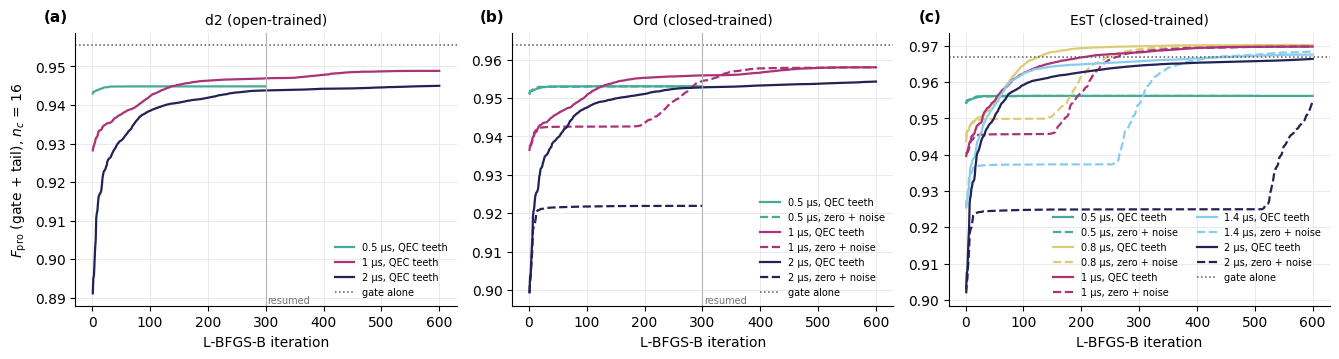

In [56]:
fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.7), sharey=False)
for ax, g in zip(axes, TAIL_GATES):
    for (gg, T, s), r in RUNS.items():
        if gg != g:
            continue
        h = r["info"]["history"]
        ax.plot([e["it"] for e in h], [e["F_pro"] for e in h], color=T_COL[T],
                ls="-" if s == "t2" else "--", lw=1.6, label=f"{T:g} μs, {STARTS[s]}")
    ax.axhline(F_ALONE[g], color="0.35", ls=":", lw=1.1, label="gate alone")
    if any(r["resumed"] for (gg, _, _), r in RUNS.items() if gg == g):
        ax.axvline(300, color="0.7", lw=0.8)
        ax.text(303, ax.get_ylim()[0], "resumed", fontsize=7, color="0.45", va="bottom")
    ax.set_title(GATE_LONG[g], fontsize=10)
    ax.set_xlabel("L-BFGS-B iteration")
    tidy(ax)
axes[0].set_ylabel(r"$F_{\rm pro}$ (gate + tail), $n_c$ = 16")
for ax, k, g in zip(axes, "abc", TAIL_GATES):
    ax.legend(fontsize=7, frameon=False, loc="lower right", ncol=2 if g == G_SHOT else 1)
    panel(ax, k)
fig.tight_layout()
fig.savefig("figures/fwm_tails_training.png", dpi=150)
plt.show()

**Figure C2. Training curves:** (a) d2, (b) Ord, (c) EsT. Colour = tail length (teal 0.5 μs, sand 0.8 μs, wine 1 μs,
cyan 1.4 μs, indigo 2 μs); solid = QEC-teeth start, dashed = zero + noise; dotted = the gate alone. The grey line at
iteration 300 marks where the resumed d2 and Ord runs restart. The zero starts sit on a plateau before leaving it, the
longer the tail the later: about 150–200 iterations at 0.8 and 1 μs, 260 at 1.4 μs and 510 at 2 μs (EsT). A flat region,
not a wall.

In [57]:
gain_rows = []
for (g, T, s), r in RUNS.items():
    tr = HELD[(HELD.tag == r["tag"])].set_index("condition")
    a, b = HELD_NC[g]
    gain_rows.append({"gate": g, "tail (us)": T, "start": STARTS[s], "best start": s == BEST[(g, T)],
                      "gain, n_c 16 (train)": tr.loc["train", "gain_vs_alone"],
                      "held-out n_c": f"{a}, {b}",
                      "gain, lower held-out n_c": tr.loc["nc_a", "gain_vs_alone"],
                      "gain, higher held-out n_c": tr.loc["nc_b", "gain_vs_alone"],
                      "F difference between held-out n_c": abs(tr.loc["nc_a", "F_pro"] - tr.loc["nc_b", "F_pro"]),
                      "§3.3 estimate": tail_estimate(GAIN_REPAIR[g], T)[3]})
GAIN_TAB = pd.DataFrame(gain_rows)
gcols = [c for c in GAIN_TAB.columns if c.startswith("gain") or c == "§3.3 estimate"]
display(GAIN_TAB.rename(columns=MU).style.hide(axis="index")
        .format({**{c: "{:+.2%}" for c in gcols}, "tail (μs)": "{:g}", "F difference between held-out n_c": "{:.1e}"})
        .set_caption("Table C6. Gain of every trained tail over its gate alone"))

gate,tail (μs),start,best start,"gain, n_c 16 (train)",held-out n_c,"gain, lower held-out n_c","gain, higher held-out n_c",F difference between held-out n_c,§3.3 estimate
d2,0.5,QEC teeth,True,-1.07%,"18, 20",-1.07%,-1.07%,4.5e-07,+0.27%
d2,1,QEC teeth,True,-0.67%,"18, 20",-0.67%,-0.67%,4.6e-07,+0.20%
d2,2,QEC teeth,True,-1.06%,"18, 20",-1.06%,-1.06%,4.6e-07,+0.06%
Ord,0.5,QEC teeth,True,-1.08%,"24, 28",-1.08%,-1.08%,3.6e-06,+0.38%
Ord,0.5,zero + noise,False,-1.08%,"24, 28",-1.08%,-1.08%,3.6e-06,+0.38%
Ord,1,QEC teeth,False,-0.58%,"24, 28",-0.58%,-0.58%,3.6e-06,+0.31%
Ord,1,zero + noise,True,-0.58%,"24, 28",-0.58%,-0.58%,3.6e-06,+0.31%
Ord,2,QEC teeth,True,-0.95%,"24, 28",-0.95%,-0.95%,3.6e-06,+0.16%
Ord,2,zero + noise,False,-4.19%,"24, 28",-4.19%,-4.19%,3.5e-06,+0.16%
EsT,0.5,QEC teeth,True,-1.08%,"24, 28",-1.08%,-1.08%,1.6e-08,+1.30%


**Table C6. Gain of every trained tail over its gate alone,** at the training truncation and at the two held-out
truncations (gate and tail re-run without the cut). The held-out $n_c$ change no gain by more than $4\times10^{-6}$.
*Symbols:* held-out $n_c$ = 18 and 20 for d2, 24 and 28 for EsT and Ord.

In [58]:
F_1US = RUNS[(G_SHOT, 1.0, BEST[(G_SHOT, 1.0)])]["info"]["F_pro"]
rt_rows = []
for T in EST_T:
    r = RUNS[(G_SHOT, T, BEST[(G_SHOT, T)])]
    i, h = r["info"], r["info"]["history"]
    Fh = np.array([e["F_pro"] for e in h])
    rt_rows.append({"tail (us)": T, "start": STARTS[BEST[(G_SHOT, T)]], "F at start": i["F_pro_start"],
                    "F trained": i["F_pro"], "vs gate alone": i["F_pro"] - F_ALONE[G_SHOT],
                    "vs idle tail": i["F_pro"] - F_IDLE[(G_SHOT, T)], "vs 1 μs tail": i["F_pro"] - F_1US,
                    "gain, last 100 it": Fh[-1] - Fh[max(len(Fh) - 101, 0)],
                    "max |eta_1|": i["max_eta_1"], "max |eta_2|": i["max_eta_2"],
                    "x pinned": i["frac_preimage_pinned"], "iterations": i["nit"], "hours": i["wall_s"] / 3600,
                    "returned": i["returned"]})
RT_TAB = pd.DataFrame(rt_rows)
display(RT_TAB.rename(columns=MU).style.hide(axis="index")
        .format({"tail (μs)": "{:g}", "F at start": "{:.5f}", "F trained": "{:.5f}", "vs gate alone": "{:+.2%}",
                 "vs idle tail": "{:+.2%}", "vs 1 μs tail": "{:+.3%}", "gain, last 100 it": "{:+.1e}",
                 "max |eta_1|": "{:.3f}", "max |eta_2|": "{:.3f}", "x pinned": "{:.2%}", "hours": "{:.1f}"})
        .set_caption("Table C7. The EsT tails at five lengths, better start"))

tail (μs),start,F at start,F trained,vs gate alone,vs idle tail,vs 1 μs tail,"gain, last 100 it",max |eta_1|,max |eta_2|,x pinned,iterations,hours,returned
0.5,QEC teeth,0.95436,0.95623,-1.08%,+0.12%,-1.362%,+4.2e-10,0.013,0.007,0.00%,600,3.6,best_seen
0.8,QEC teeth,0.94370,0.97027,+0.32%,+2.37%,+0.042%,-1.5e-05,0.081,0.101,0.00%,600,8.1,best_seen
1,zero + noise,0.94026,0.96985,+0.28%,+2.95%,+0.000%,+9.3e-05,0.068,0.100,0.00%,600,8.6,final
1.4,zero + noise,0.92514,0.96843,+0.14%,+4.15%,-0.142%,+8.5e-04,0.060,0.099,0.00%,600,12.1,final
2,QEC teeth,0.90321,0.96642,-0.06%,+6.24%,-0.343%,+6.3e-04,0.056,0.096,0.00%,600,17.8,final


**Table C7. Training of the EsT tails at five lengths,** better start.
*Symbols:* "vs 1 μs tail" = against the trained 1 μs tail (0.96985); "gain, last 100 it" = change over the last 100
iterations.

The 0.8 μs tail is the best, +0.04 % over 1 μs; 1.4 and 2 μs are 0.14 % and 0.34 % below it. The 0.8 μs run returned
its best point (flat within $2\times10^{-5}$ at the end); the 1.4 and 2 μs runs still rose by $6$–$9\times10^{-4}$ over
their last 100 iterations, which would not change their place.

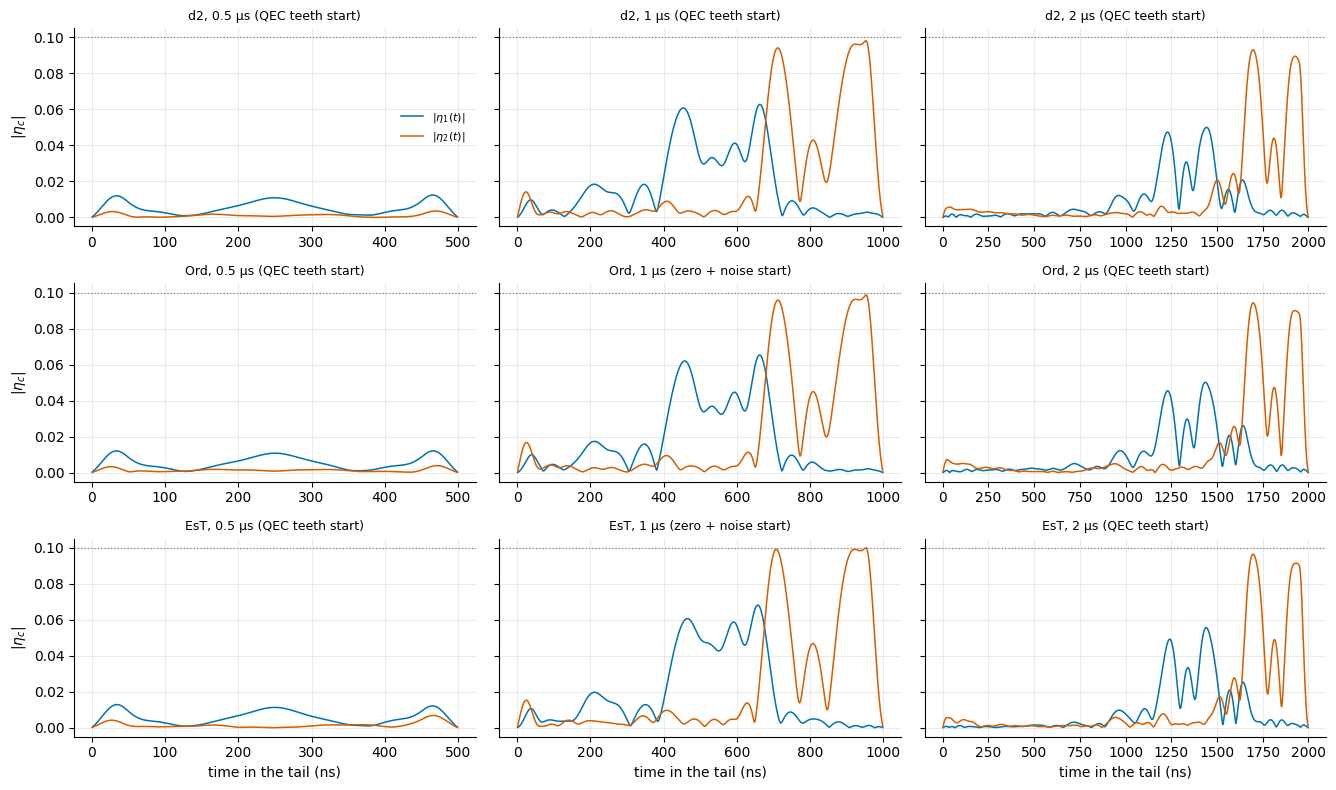

In [59]:
fig, axes = plt.subplots(3, 3, figsize=(13.5, 8.0), sharey=True)
for i, g in enumerate(TAIL_GATES):
    for j, T in enumerate(TAIL_T):
        ax = axes[i, j]
        eta = RUNS[(g, T, BEST[(g, T)])]["eta"]
        t_ns = (np.arange(len(eta)) + 0.5) * DT * 1e3
        for c, col in ((0, OKABE[0]), (1, OKABE[4])):
            ax.plot(t_ns, np.abs(eta[:, c]), color=col, lw=1.1, label=fr"$|\eta_{c + 1}(t)|$")
        ax.axhline(ft.ETA_CAP, color="0.5", ls=":", lw=0.9)
        ax.set_title(f"{g}, {T:g} μs ({STARTS[BEST[(g, T)]]} start)", fontsize=9)
        if i == 2:
            ax.set_xlabel("time in the tail (ns)")
        if j == 0:
            ax.set_ylabel(r"$|\eta_c|$")
        tidy(ax)
axes[0, 0].legend(fontsize=8, frameon=False)
fig.tight_layout()
fig.savefig("figures/fwm_tails_waveforms.png", dpi=150)
plt.show()

**Figure C3. The trained waveforms,** better start of each gate (rows) and length (columns 0.5, 1, 2 μs; the EsT
0.8 and 1.4 μs tails are in Figure C5). Blue: $|\eta_1(t)|$; vermilion: $|\eta_2(t)|$; dotted: the cap 0.1. After every
gate and from both starts the shape is the same: almost nothing at first, then a comb-1 burst (about 300–500 ns,
$|\eta_1|$ up to 0.05–0.07), then comb 2 near the cap.

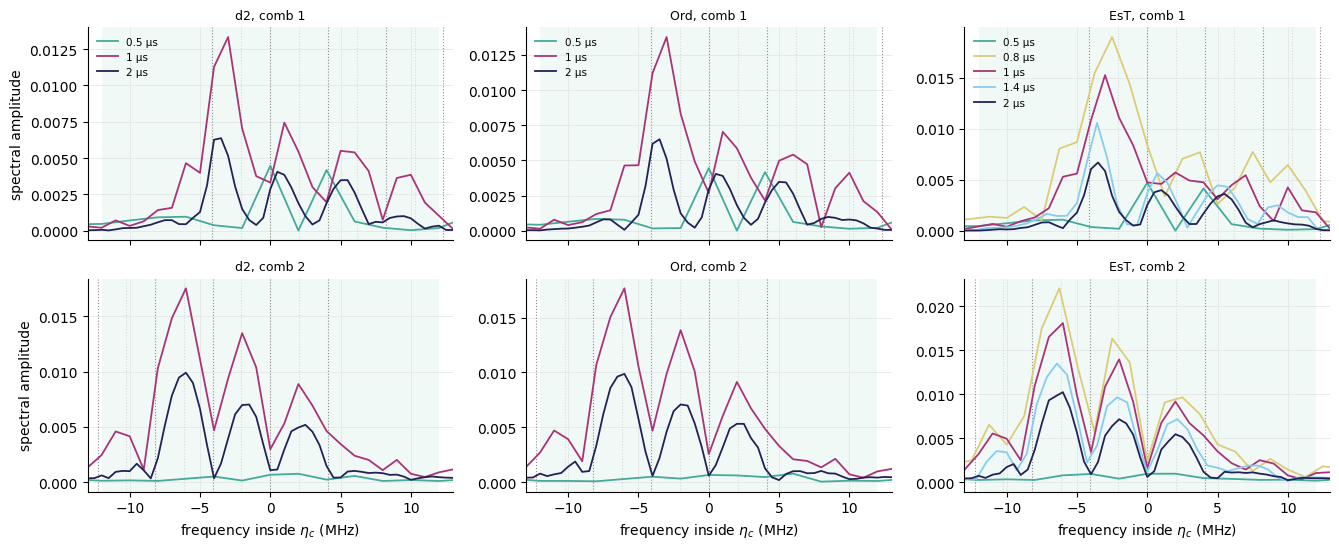

In [60]:
off5 = ft.tooth_offsets(N_C, ft.N_REF, fwm.FULL_PATHS)
fig, axes = plt.subplots(2, 3, figsize=(13.5, 5.6), sharex=True)
for j, g in enumerate(TAIL_GATES):
    for c in range(2):
        ax = axes[c, j]
        for n, x in zip(off5["paths"], mhz(off5[f"comb{c + 1}"])):
            ax.axvline(x, color="0.55" if n % 2 else "0.85", lw=0.8, ls=":")
        for T in GATE_T[g]:
            eta = RUNS[(g, T, BEST[(g, T)])]["eta"][:, c]
            freq = np.fft.fftshift(np.fft.fftfreq(len(eta), DT))
            ax.plot(freq, np.abs(np.fft.fftshift(np.fft.fft(eta))) / len(eta), color=T_COL[T], lw=1.3,
                    label=f"{T:g} μs")
        ax.axvspan(*ft.ETA_BAND, color=OKABE[2], alpha=0.06, lw=0)
        ax.set_xlim(-13, 13)
        ax.set_title(f"{g}, comb {c + 1}", fontsize=9)
        if c == 1:
            ax.set_xlabel(r"frequency inside $\eta_c$ (MHz)")
        if j == 0:
            ax.set_ylabel("spectral amplitude")
        tidy(ax)
    axes[0, j].legend(fontsize=7.5, frameon=False)
fig.tight_layout()
fig.savefig("figures/fwm_tails_spectra.png", dpi=150)
plt.show()

**Figure C4. Spectra of the trained waveforms.** Upper row comb 1, lower row comb 2; colour = tail length. Dotted:
the bare teeth of Table 5 (darker for repair teeth). Green: the band.

The peaks sit 1–2 MHz below the repair teeth they serve (comb 1 near −3 MHz for tooth 1 at −4.1; comb 2 near −6, −2
and +2 MHz for −4.1, 0, +4.1). That matches the Stark shift at these amplitudes (2π·538 MHz·$|\xi|^2$: 2 MHz at 0.06):
the tails aim at the shifted lines. The EsT tails have the same peaks; the 0.8 μs tail is the strongest, since it
packs the same repair into the shortest time.

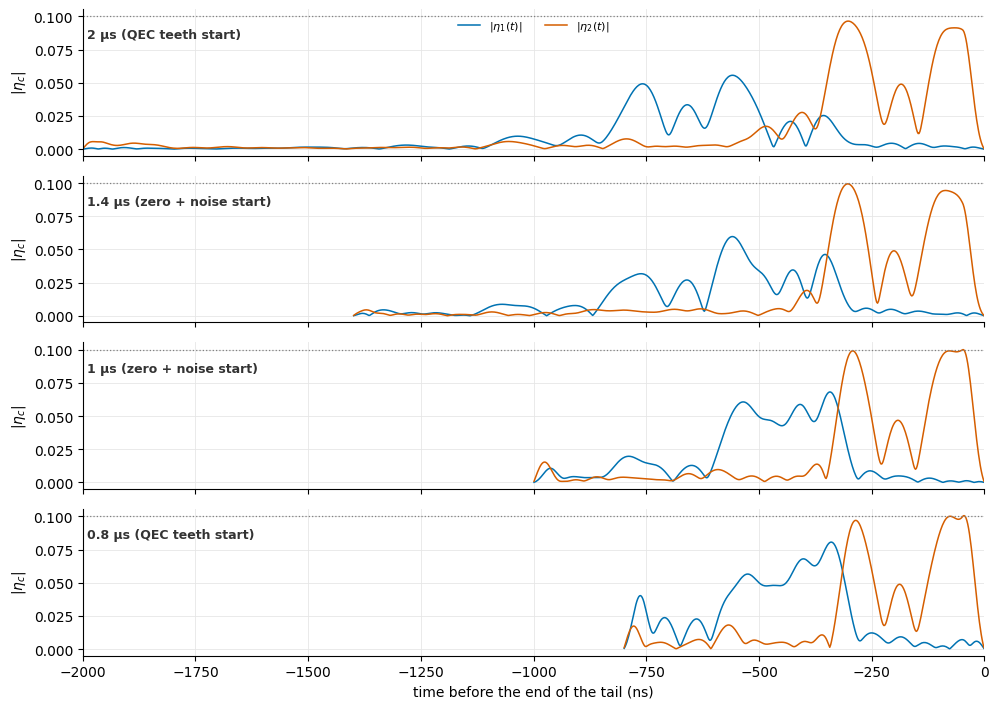

In [61]:
fig, axes = plt.subplots(len(SHOT_T), 1, figsize=(10.0, 7.2), sharex=True, sharey=True)
for ax, T in zip(axes, SHOT_T[::-1]):
    eta = best_eta(T)
    t_end = ((np.arange(len(eta)) + 0.5) * DT - T) * 1e3            # ns, counted back from the end of the tail
    for c, col in ((0, OKABE[0]), (1, OKABE[4])):
        ax.plot(t_end, np.abs(eta[:, c]), color=col, lw=1.1, label=fr"$|\eta_{c + 1}(t)|$")
    ax.axhline(ft.ETA_CAP, color="0.5", ls=":", lw=0.9)
    ax.text(0.005, 0.8, f"{T:g} μs ({STARTS[BEST[(G_SHOT, T)]]} start)", transform=ax.transAxes,
            fontsize=9, color="0.2", fontweight="bold")
    ax.set_ylabel(r"$|\eta_c|$")
    tidy(ax)
axes[0].legend(fontsize=8, frameon=False, loc="upper center", ncol=2)
axes[-1].set_xlabel("time before the end of the tail (ns)")
axes[-1].set_xlim(-2000, 0)
fig.tight_layout()
fig.savefig("figures/fwm_tails_est_waveforms_aligned.png", dpi=150)
plt.show()

**Figure C5. The four EsT tails that build a shot, aligned at their end** (top 2 μs, bottom 0.8 μs; blue $|\eta_1|$,
vermilion $|\eta_2|$). All end in the same shot: comb 1 from about 600–800 ns to 300 ns before the end, then comb 2
near the cap in two lobes. The shorter the tail, the stronger and more compact comb 1 (peak 0.081 at 0.8 μs, 0.068 at
1 μs, 0.056–0.060 at 1.4 and 2 μs). Before the shot the longer tails stay nearly idle.

In [62]:
run_label = {r["tag"]: f"{g} {T:g} μs, {'QEC' if s == 't2' else 'zero'}" for (g, T, s), r in RUNS.items()}
piv = (HELD[HELD.tag.isin(run_label)]
       .assign(run=lambda d: d.tag.map(run_label))
       .pivot(index="condition", columns="run", values="gain_vs_alone").loc[conds, list(run_label.values())])
display(piv.rename(index=COND_LABEL).style.format("{:+.2%}")
        .set_caption("Table C8. Gain over the gate alone under each held-out condition, every run"))

run,"d2 0.5 μs, QEC","d2 1 μs, QEC","d2 2 μs, QEC","Ord 0.5 μs, QEC","Ord 0.5 μs, zero","Ord 1 μs, QEC","Ord 1 μs, zero","Ord 2 μs, QEC","Ord 2 μs, zero","EsT 0.5 μs, QEC","EsT 0.5 μs, zero","EsT 0.8 μs, QEC","EsT 0.8 μs, zero","EsT 1 μs, QEC","EsT 1 μs, zero","EsT 1.4 μs, QEC","EsT 1.4 μs, zero","EsT 2 μs, QEC","EsT 2 μs, zero"
condition,,,,,,,,,,,,,,,,,,,
"training (n_c 16, cut)",-1.07%,-0.67%,-1.06%,-1.08%,-1.08%,-0.58%,-0.58%,-0.95%,-4.19%,-1.08%,-1.08%,+0.32%,+0.32%,+0.28%,+0.28%,+0.06%,+0.14%,-0.06%,-1.23%
"n_c 18 (d2) / 24 (EsT, Ord)",-1.07%,-0.67%,-1.06%,-1.08%,-1.08%,-0.58%,-0.58%,-0.95%,-4.19%,-1.08%,-1.08%,+0.32%,+0.32%,+0.28%,+0.28%,+0.06%,+0.14%,-0.06%,-1.23%
"n_c 20 (d2) / 28 (EsT, Ord)",-1.07%,-0.67%,-1.06%,-1.08%,-1.08%,-0.58%,-0.58%,-0.95%,-4.19%,-1.08%,-1.08%,+0.32%,+0.32%,+0.28%,+0.28%,+0.06%,+0.14%,-0.06%,-1.23%
n_r = 3,-1.07%,-0.67%,-1.06%,-1.08%,-1.08%,-0.58%,-0.58%,-0.96%,-4.19%,-1.08%,-1.08%,+0.32%,+0.31%,+0.27%,+0.28%,+0.05%,+0.13%,-0.07%,-1.24%
+ dephasing and heating,-1.21%,-1.02%,-1.65%,-1.21%,-1.21%,-0.88%,-0.88%,-1.49%,-4.67%,-1.22%,-1.22%,+0.03%,+0.02%,-0.08%,-0.07%,-0.39%,-0.31%,-0.66%,-1.82%
couplings g/√2,-1.10%,-3.64%,-3.36%,-1.11%,-1.11%,-3.60%,-4.35%,-3.17%,-4.70%,-1.11%,-1.11%,-8.64%,-6.97%,-5.66%,-5.72%,-3.47%,-2.07%,-3.01%,-2.93%
η × 0.9,-1.08%,-3.82%,-2.26%,-1.08%,-1.08%,-3.83%,-4.74%,-2.07%,-4.26%,-1.09%,-1.09%,-10.27%,-8.21%,-6.39%,-6.50%,-3.00%,-1.47%,-1.76%,-1.51%
η × 1.1,-1.08%,-4.74%,-2.31%,-1.08%,-1.08%,-4.79%,-5.91%,-2.03%,-4.27%,-1.09%,-1.09%,-12.79%,-10.30%,-8.12%,-8.22%,-3.93%,-1.70%,-1.83%,-1.63%
Stark shift off,-1.08%,-33.84%,-14.19%,-1.08%,-1.08%,-34.58%,-41.77%,-13.35%,-4.19%,-1.09%,-1.09%,-77.37%,-69.30%,-56.93%,-57.55%,-36.73%,-18.02%,-19.19%,-4.96%


**Table C8. Gain over the gate alone under each held-out condition, every run.** Columns: gate, tail length and start
(QEC = QEC-teeth start, zero = zero + noise).
*Symbols:* each entry is $F_{\rm pro}$(gate + tail) − $F_{\rm pro}$(gate alone), both scored under that row's condition.

In [63]:
end_rows = [{"gate": g, "tail (μs)": T, "⟨n_r⟩ at end": held("trained", g, tag=RUNS[(g, T, s)]["tag"]).n_r_end,
             "P_e at end": held("trained", g, tag=RUNS[(g, T, s)]["tag"]).P_e_end,
             "P_f at end": held("trained", g, tag=RUNS[(g, T, s)]["tag"]).P_f_end,
             "F_empty − F_pro": held("trained", g, tag=RUNS[(g, T, s)]["tag"]).F_empty
             - held("trained", g, tag=RUNS[(g, T, s)]["tag"]).F_pro}
            for (g, T), s in BEST.items()]
display(pd.DataFrame(end_rows).style.hide(axis="index")
        .format({"tail (μs)": "{:g}", "⟨n_r⟩ at end": "{:.1e}", "P_e at end": "{:.1e}", "P_f at end": "{:.1e}",
                 "F_empty − F_pro": "{:+.2%}"})
        .set_caption("Table C9. What is left at the end of the better tails"))

gate,tail (μs),⟨n_r⟩ at end,P_e at end,P_f at end,F_empty − F_pro
EsT,0.5,6.1e-06,6.9e-03,5.1e-03,-0.00%
EsT,0.8,1.7e-02,9.3e-03,2.8e-03,-1.50%
EsT,1,1.9e-02,9.3e-03,1.9e-03,-1.66%
EsT,1.4,2.1e-02,9.0e-03,1.8e-03,-1.83%
EsT,2,2.5e-02,9.2e-03,1.5e-03,-2.24%
Ord,0.5,1.5e-06,1.4e-02,3.5e-03,-0.00%
Ord,1,1.5e-02,1.7e-02,2.1e-03,-1.14%
Ord,2,2.1e-02,1.6e-02,1.7e-03,-1.79%
d2,0.5,1.4e-06,2.0e-02,3.4e-03,-0.00%
d2,1,1.4e-02,2.2e-02,2.2e-03,-1.08%


**Table C9. What is left at the end of the better tails** (training condition).
*Symbols:* ⟨$n_r$⟩, $P_e$, $P_f$ = readout photons and the transmon's $e$ and $f$ populations at the end;
$F_{\rm empty} - F_{\rm pro}$ = the change in score when the readout must also end empty. The repaired losses sit in
the readout (0.014–0.025 photons), which empties on its own in $1/\kappa_r$ = 0.27 μs. The EsT gate leaves the transmon
less excited at the end ($P_e$ 0.009 against 0.016–0.022).

In [64]:
display(POP.style.format("{:.5f}").set_caption("Table C10. Where the population is at T_g, EsT gate (Figure 3)"))

,right code word,correctable (right error word),wrong error word,"even, uncorrectable",wrong code word,"odd, outside the code",transmon in e or f
closed (no dissipation),0.99870,0.00001,0.00004,0.00024,0.00003,0.00023,0.00074
storage photon loss only,0.97469,0.02063,0.00011,0.00094,0.00026,0.00045,0.00292
transmon T1 only,0.99101,0.00064,0.00080,0.00125,0.00045,0.00132,0.00454
storage dephasing only,0.99281,0.00132,0.00107,0.00093,0.00004,0.00127,0.00257
transmon dephasing only,0.99493,0.00020,0.00034,0.00071,0.00032,0.00093,0.00257
heating only,0.99830,0.00002,0.00016,0.00032,0.00004,0.00029,0.00088
all decay (training model),0.96720,0.02109,0.00086,0.00194,0.00068,0.00153,0.00670
all channels,0.95755,0.02235,0.00227,0.00315,0.00100,0.00327,0.01041


**Table C10. Where the population is at $T_g$** (Figure 3), EsT X gate, one row per row of Table 1. Each row adds up
to 1.
*Symbols:* the categories of §2.2, mean over the inputs $|0_L\rangle$, $|1_L\rangle$; $n_c = 24$, readout cut to one
level.